# PhishGuard AI — Branch B: OCR & Text Analysis

This notebook consumes the existing `reports/cleaned_image_manifest.csv` from Dataset Audit. It does not repeat the audit, change labels, images, or audit outputs. It builds a CPU-first OCR workflow, saves restartable results under `reports/ocr/`, and creates structured text features for future model integration.

**Scope:** OCR and screenshot text analysis only. No URL, DNS, HTML, logo, brand, classifier, or fusion analysis. OCR runtime metrics are not recognition accuracy; accuracy requires ground-truth text.

`Dataset Audit → Cleaned Image Manifest → Image Preparation → Above-the-Fold Extraction → PaddleOCR → Text Filtering & Cleaning → Keyword & Pattern Analysis → Structured OCR Results → Future ML / Fusion Model`


## Introduction & OCR Pipeline Overview

Optical Character Recognition (OCR) detects text regions in an image and converts them into text with positions and confidence values. Website screenshot text can expose sign-in prompts, account notices, or payment language that whole-image classification cannot explain. Classification assigns a category to an image; OCR extracts localized text evidence. In PhishGuard, this branch turns the audited image manifest into structured text records for future combination with other signals. OCR can miss small, stylized, blurred, or low-contrast text, so its results are evidence for review, not a phishing verdict.


## Environment Setup & Imports

In [ ]:
from pathlib import Path
import json, os, platform, re, sys, time
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
try:
    import cv2
except ImportError:
    cv2 = None
try:
    import google.colab  
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PROJECT_ROOT = None  
DATASET_ROOT = None  
MANIFEST_PATH = None  
if PROJECT_ROOT is not None:
    PROJECT_ROOT = Path(PROJECT_ROOT).expanduser()
else:
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    PROJECT_ROOT = next((p for p in candidates if (p / "reports" / "cleaned_image_manifest.csv").is_file()), None)
    if PROJECT_ROOT is None and IN_COLAB:
        PROJECT_ROOT = Path("/content/project")  
if MANIFEST_PATH is not None:
    MANIFEST_PATH = Path(MANIFEST_PATH).expanduser()
elif PROJECT_ROOT is not None:
    MANIFEST_PATH = PROJECT_ROOT / "reports" / "cleaned_image_manifest.csv"
if PROJECT_ROOT is None and MANIFEST_PATH is not None:
    PROJECT_ROOT = Path(MANIFEST_PATH).expanduser().resolve().parent.parent
if PROJECT_ROOT is None or MANIFEST_PATH is None or not MANIFEST_PATH.is_file():
    raise FileNotFoundError("Complete Dataset Audit first, then set PROJECT_ROOT or MANIFEST_PATH in this cell.")
PROJECT_ROOT = PROJECT_ROOT.resolve()
sys.path.insert(0, str(PROJECT_ROOT))
REPORTS_DIR = PROJECT_ROOT / "reports"
OCR_OUTPUT_DIR = REPORTS_DIR / "ocr"
OCR_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OCR_USE_GPU = False
OCR_CONFIDENCE_THRESHOLD = 0.4
OCR_BATCH_SIZE = 1
OCR_USE_PREPROCESSING = False
OCR_USE_GRAYSCALE = False
OCR_USE_DENOISING = False
OCR_THRESHOLD_VALUE = None  
OCR_RESUME = True
OCR_RETRY_FAILED = True
ABOVE_FOLD_RATIO = 0.40
OCR_DEFAULT_LANGUAGE = "en"
OCR_MODEL_VERSION = "PP-OCRv5"
OCR_CPU_THREADS = 4
OCR_CROP_MODE = "full"  
OCR_MAX_SIDE = 1600  
SAMPLE_IMAGES_PER_CLASS = 2
MAX_IMAGES = 8
RUN_FULL_DATASET = False  
FORCE_RERUN = False
print({"python":sys.version.split()[0], "platform":platform.platform(), "colab":IN_COLAB,
       "pandas":pd.__version__, "numpy":np.__version__, "opencv":getattr(cv2,"__version__","not installed")})
try:
    import paddleocr, paddle
    print({"paddleocr":getattr(paddleocr,"__version__","unknown"), "paddle":paddle.__version__,
           "cuda_compiled":paddle.is_compiled_with_cuda(), "device":paddle.device.get_device()})
except Exception as exc:
    print(f"PaddleOCR unavailable: {type(exc).__name__}: {exc}. Install CPU packages and restart the kernel.")


{'python': '3.11.18', 'platform': 'Windows-10-10.0.26200-SP0', 'colab': False, 'pandas': '3.1.0', 'numpy': '2.4.6', 'opencv': '4.10.0'}


c:\Users\smata\anaconda3\envs\phishguard-ocr\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


{'paddleocr': '3.7.0', 'paddle': '3.2.2', 'cuda_compiled': False, 'device': 'cpu'}


## Load and Validate the Audited Dataset

The actual manifest shape and columns are inspected before use. Required columns are verified; missing values, class counts, duplicate IDs/paths, file existence, and image readability are reported. Supplied absolute paths are preserved; relative paths resolve only against configured project/dataset roots. Invalid rows are displayed and saved, and no replacement paths are guessed. The source DataFrame stays unchanged; OCR uses a separate working copy.


In [ ]:

manifest = pd.read_csv(
    MANIFEST_PATH,
    dtype={"image_id": "string", "path": "string", "label": "string"}
)

print(
    "Manifest:", MANIFEST_PATH,
    "| shape:", manifest.shape,
    "| columns:", manifest.columns.tolist()
)

display(manifest.head())
display(manifest.isna().sum().rename("missing_values").to_frame())

required = {"image_id", "path", "label"}

if not required.issubset(manifest.columns):
    raise ValueError(
        f"Required columns {sorted(required)} missing; "
        f"found {manifest.columns.tolist()}"
    )

print(
    "Duplicate IDs:",
    int(manifest.image_id.duplicated(keep=False).sum()),
    "| duplicate paths:",
    int(manifest.path.duplicated(keep=False).sum())
)

display(
    manifest.label.value_counts(dropna=False)
    .rename_axis("label")
    .to_frame("count")
)


def resolve_image_path(value):
    raw = str(value).strip()
    candidate = Path(raw).expanduser()

    if candidate.is_absolute():
        return candidate

    if PureWindowsPath(raw).is_absolute() and os.name != "nt":
        return candidate

    roots = (
        [Path(DATASET_ROOT).expanduser(), PROJECT_ROOT]
        if DATASET_ROOT is not None
        else [PROJECT_ROOT]
    )

    for base in roots:
        test = base / candidate
        if test.exists():
            return test

    return roots[0] / candidate


working_df = manifest.copy()

working_df["resolved_path"] = working_df["path"].map(
    resolve_image_path
)

working_df["path_exists"] = working_df["resolved_path"].map(
    lambda p: Path(p).is_file()
)

working_df["image_readable"] = working_df["path_exists"]

working_df["image_width"] = pd.NA
working_df["image_height"] = pd.NA

invalid = (
    working_df.image_id.isna()
    | working_df.path.isna()
    | working_df.label.isna()
    | ~working_df.path_exists
    | working_df.image_id.duplicated(keep=False)
    | working_df.resolved_path.astype(str).duplicated(keep=False)
)

invalid_rows = working_df.loc[invalid].copy()

missing_paths = working_df.loc[
    ~working_df.path_exists,
    ["image_id", "path", "resolved_path", "label"]
]

print({
    "rows": len(working_df),
    "valid_rows": int((~invalid).sum()),
    "missing_paths": len(missing_paths),
    "invalid_records": len(invalid_rows)
})

if len(missing_paths):
    display(missing_paths.head(30))
    missing_paths.to_csv(
        OCR_OUTPUT_DIR / "missing_image_paths.csv",
        index=False,
        encoding="utf-8-sig"
    )

if len(invalid_rows):
    invalid_rows.to_csv(
        OCR_OUTPUT_DIR / "manifest_validation_issues.csv",
        index=False,
        encoding="utf-8-sig"
    )

valid_df = working_df.loc[~invalid].copy()

if len(missing_paths):
    raise FileNotFoundError(
        "Some manifest paths are inaccessible. "
        "Check PROJECT_ROOT and DATASET_ROOT."
    )

print("Manifest validation completed.")
print("Valid images:", len(valid_df))


Manifest: D:\DEPI Graduation Project\computer_vision_milstone\reports\cleaned_image_manifest.csv | shape: (15184, 14) | columns: ['record_id', 'image_id', 'path', 'label', 'file_name', 'file_size_bytes', 'width', 'height', 'image_mode', 'readable', 'is_fully_white', 'validation_error', 'sha256', 'phash']


,record_id,image_id,path,label,file_name,file_size_bytes,width,height,image_mode,readable,is_fully_white,validation_error,sha256,phash
0,1,img_000001,D:\DEPI Graduation Project\computer_vision_mil...,phishing,10010_qrco.de_bfWgu0.png,94567,1920.0,1080.0,RGB,True,False,NaN,38fc9b38b1c19e6257fdf67c3d5cd069090a888a24c5c3...,bc3c313367464676
1,3,img_000003,D:\DEPI Graduation Project\computer_vision_mil...,phishing,10021_q-r.to_bfJnIk.png,36318,1920.0,1080.0,RGB,True,False,NaN,c266ac92cd1ba26e0481947a50fb89661c1b60fb605974...,e66666667c591919
2,4,img_000004,D:\DEPI Graduation Project\computer_vision_mil...,phishing,10030_linkin.bio_bankaxept.png,689150,1920.0,1080.0,RGB,True,False,NaN,c3f8a167c3b50ac524292792a5f4153e034b32b44fe97a...,c74ae120b9fb8ac3
3,5,img_000005,D:\DEPI Graduation Project\computer_vision_mil...,phishing,10037_qrco.de_bfO5Oe.png,56333,1920.0,1080.0,RGB,True,False,NaN,aa373ebbfceb9ca3d4484307cc626f63c0289a9b87e700...,b333cccc333398cc
4,8,img_000008,D:\DEPI Graduation Project\computer_vision_mil...,phishing,10093_did.li_F8i6q.png,22593,1920.0,1080.0,RGB,True,False,NaN,b47bb400bbda623c2de95858684ac3eef54cd31c8c7eec...,e68c993366cc9933


,missing_values
record_id,0
image_id,0
path,0
label,0
file_name,0
file_size_bytes,0
width,0
height,0
image_mode,0
readable,0


Duplicate IDs: 0 | duplicate paths: 0


,count
label,
legitimate,10432
phishing,4752


{'rows': 15184, 'valid_rows': 15184, 'missing_paths': 0, 'invalid_records': 0}
Manifest validation completed.
Valid images: 15184


## Image Preparation & Controlled Variant Experiment

A small sample from both classes is compared across original, downscaled, grayscale, contrast-enhanced, top crop, and top crop with mild enhancement. The same OCR model is used for each variant. A table reports text-line count, mean confidence, and processing time; plots show the images and the extracted text supports manual quality review. 


OCR runtime versions: {'paddleocr': '3.7.0', 'paddlepaddle': '3.2.2', 'paddle_runtime': '3.2.2', 'gpu_compiled': False}


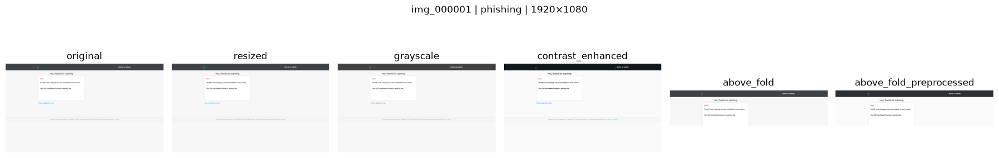

Creating model: ('PP-OCRv5_server_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\PP-OCRv5_server_det`.
Creating model: ('en_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\en_PP-OCRv5_mobile_rec`.


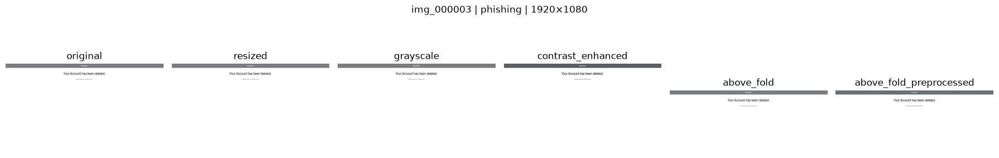

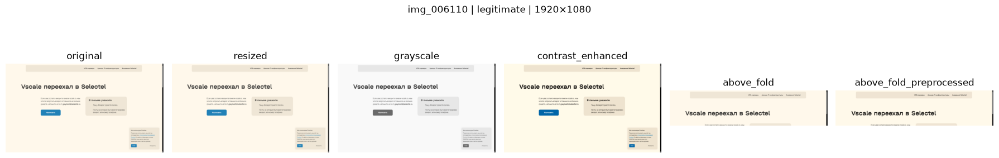

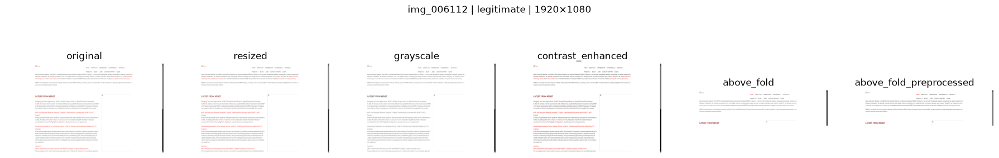

,image_id,label,variant,detected_lines,average_confidence,processing_seconds,text_for_review
0,img_000001,phishing,original,7,0.987160,256.501777,"Back to our website\nHey, thanks for scanning\..."
1,img_000001,phishing,resized,7,0.985428,42.628107,"← Back to our website\nHey, thanks for scannin..."
2,img_000001,phishing,grayscale,7,0.983505,64.882016,"← Back to our website\nHey, thanks for scannin..."
3,img_000001,phishing,contrast_enhanced,8,0.906018,249.053732,"Back to our website\n+\nHey, thanks for scanni..."
4,img_000001,phishing,above_fold,6,0.901602,41.483121,"Ⅱ\nBack to our website\nHey, thanks for scanni..."
5,img_000001,phishing,above_fold_preprocessed,5,0.992541,27.143673,"Back to our website\nHey, thanks for scanning\..."
6,img_000003,phishing,original,3,0.986074,71.455769,Information\nYour Account has been deleted.\nP...
7,img_000003,phishing,resized,3,0.988813,37.400184,Information\nYour Account has been deleted.\nP...
8,img_000003,phishing,grayscale,3,0.993162,64.324058,Information\nYour Account has been deleted.\nP...
9,img_000003,phishing,contrast_enhanced,3,0.989112,59.697249,Information\nYour Account has been deleted.\nP...


In [5]:
from src.branch_b_model import OCRConfig, OCRPipeline
from src.branch_b_model.config import LANGUAGE_MODELS
from src.branch_b_model.image_preprocessing import load_rgb, make_variants, crop_above_fold
from src.branch_b_model.ocr_engine import package_versions, predict_image

print("OCR runtime versions:",package_versions())

config=OCRConfig(output_dir=OCR_OUTPUT_DIR,default_language=OCR_DEFAULT_LANGUAGE,ocr_version=OCR_MODEL_VERSION,
 confidence_threshold=OCR_CONFIDENCE_THRESHOLD,above_fold_ratio=ABOVE_FOLD_RATIO,crop_mode=OCR_CROP_MODE,
 use_preprocessing=OCR_USE_PREPROCESSING,use_grayscale=OCR_USE_GRAYSCALE,use_denoising=OCR_USE_DENOISING,
 threshold_value=OCR_THRESHOLD_VALUE,resize_max_side=OCR_MAX_SIDE,resume=OCR_RESUME,
 retry_failed=OCR_RETRY_FAILED,cpu_threads=OCR_CPU_THREADS)
pipeline=OCRPipeline(config)
sample=pd.concat([valid_df[valid_df.label.str.lower()==label].head(SAMPLE_IMAGES_PER_CLASS) for label in ["phishing","legitimate"]]).drop_duplicates("image_id").head(4)
variant_rows=[]
for _,row in sample.iterrows():
    source=load_rgb(row.resolved_path)
    variants=make_variants(source,ABOVE_FOLD_RATIO,OCR_MAX_SIDE)
    fig,axes=plt.subplots(1,len(variants),figsize=(18,3.5))
    for ax,(name,image) in zip(axes,variants.items()): ax.imshow(image)
    ax.set_title(name)
    ax.axis("off")
    fig.suptitle(f"{row.image_id} | {row.label} | {source.width}×{source.height}") 
    plt.tight_layout(); plt.show()
    for name,image in variants.items():
        start=time.perf_counter(); detections=predict_image(pipeline.engine(OCR_DEFAULT_LANGUAGE),image); elapsed=time.perf_counter()-start
        kept=[d for d in detections if d["confidence"] is not None and d["confidence"]>=OCR_CONFIDENCE_THRESHOLD]
        variant_rows.append({"image_id":row.image_id,"label":row.label,"variant":name,"detected_lines":len(kept),
          "average_confidence":np.mean([d["confidence"] for d in kept]) if kept else np.nan,
          "processing_seconds":elapsed,"text_for_review":"\n".join(d["text"] for d in kept)})
variant_comparison_df=pd.DataFrame(variant_rows)

display(variant_comparison_df)


## Above-the-Fold Extraction

The crop takes a configurable fraction of each image’s own height (initially 40%); full-image OCR remains available for comparison. Source dimensions and crop geometry are recorded. A crop may reduce runtime but may miss lower-page text, so it is not assumed to be better.


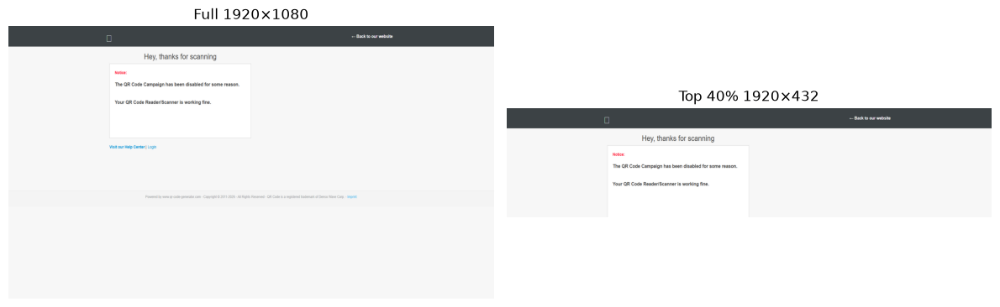

{'original_width': 1920, 'original_height': 1080, 'crop_x': 0, 'crop_y': 0, 'crop_width': 1920, 'crop_height': 432, 'crop_ratio': 0.4}


In [6]:
if len(sample):
    demo=load_rgb(sample.iloc[0].resolved_path); 
    crop,metadata=crop_above_fold(demo,ABOVE_FOLD_RATIO)
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    axes[0].imshow(demo)
    axes[0].set_title(f"Full {demo.width}×{demo.height}") 
    axes[0].axis("off")
    axes[1].imshow(crop)
    axes[1].set_title(f"Top {ABOVE_FOLD_RATIO:.0%} {crop.width}×{crop.height}") 
    axes[1].axis("off")

    plt.tight_layout()
    plt.show(); print(metadata)


## PaddleOCR Initialization, Compatibility & Multilingual Evaluation


In [7]:
LANGUAGE_SAMPLE_IMAGE_IDS={language:[] for language in LANGUAGE_MODELS}
language_rows=[]
for language,selector in LANGUAGE_MODELS.items():
    chosen=valid_df[valid_df.image_id.astype(str).isin(map(str,LANGUAGE_SAMPLE_IMAGE_IDS.get(language,[])))]
    if not len(chosen):
        language_rows.append({"language":language,"ocr_model":f"{OCR_MODEL_VERSION}/{selector}","tested_images":0,
          "successful_detections":0,"average_confidence":np.nan,"average_processing_seconds":np.nan,
          "observed_problems":"No manually identified examples configured","evaluation_status":"not_evaluated_no_examples"}); continue
    scores=[]; times=[]; detected=0; problems=[]
    for _,row in chosen.iterrows():
        start=time.perf_counter()
        try:
            screenshot=load_rgb(row.resolved_path)
            lines=predict_image(pipeline.engine(selector),screenshot); times.append(time.perf_counter()-start)
            kept=[d for d in lines if d["confidence"] is not None and d["confidence"]>=OCR_CONFIDENCE_THRESHOLD]
            plt.figure(figsize=(8,4)); plt.imshow(screenshot); plt.title(f"{language} | {row.image_id}"); plt.axis("off"); plt.show()
            print({"language":language,"image_id":row.image_id,"detected_text":[d["text"] for d in kept],
                   "confidence_scores":[d["confidence"] for d in kept],"bounding_boxes":[d["bounding_box"] for d in kept]})
            if kept: detected+=1; scores.extend(d["confidence"] for d in kept)
            else: problems.append(f"{row.image_id}: no lines over threshold")
        except Exception as exc: times.append(time.perf_counter()-start); problems.append(f"{row.image_id}: {type(exc).__name__}: {exc}")
    language_rows.append({"language":language,"ocr_model":f"{OCR_MODEL_VERSION}/{selector}","tested_images":len(chosen),
      "successful_detections":detected,"average_confidence":float(np.mean(scores)) if scores else np.nan,
      "average_processing_seconds":float(np.mean(times)) if times else np.nan,
      "observed_problems":"; ".join(problems) if problems else "No runtime error; manually inspect text",
      "evaluation_status":"tested_manual_quality_review_required"})
language_evaluation_df=pd.DataFrame(language_rows) 
display(language_evaluation_df)
language_evaluation_df.to_csv(OCR_OUTPUT_DIR/"language_evaluation.csv",index=False,encoding="utf-8-sig")


,language,ocr_model,tested_images,successful_detections,average_confidence,average_processing_seconds,observed_problems,evaluation_status
0,English,PP-OCRv5/en,0,0,NaN,NaN,No manually identified examples configured,not_evaluated_no_examples
1,Arabic,PP-OCRv5/ar,0,0,NaN,NaN,No manually identified examples configured,not_evaluated_no_examples
2,Chinese (Simplified),PP-OCRv5/ch,0,0,NaN,NaN,No manually identified examples configured,not_evaluated_no_examples
3,Japanese,PP-OCRv5/japan,0,0,NaN,NaN,No manually identified examples configured,not_evaluated_no_examples
4,Russian,PP-OCRv5/ru,0,0,NaN,NaN,No manually identified examples configured,not_evaluated_no_examples
5,Korean,PP-OCRv5/korean,0,0,NaN,NaN,No manually identified examples configured,not_evaluated_no_examples
6,German,PP-OCRv5/de,0,0,NaN,NaN,No manually identified examples configured,not_evaluated_no_examples
7,French,PP-OCRv5/fr,0,0,NaN,NaN,No manually identified examples configured,not_evaluated_no_examples
8,Indonesian,PP-OCRv5/id,0,0,NaN,NaN,No manually identified examples configured,not_evaluated_no_examples
9,Norwegian,PP-OCRv5/no,0,0,NaN,NaN,No manually identified examples configured,not_evaluated_no_examples


## Load Language Candidates & Create Image Language Mapping

In [ ]:
language_candidates_df = pd.read_csv(
    REPORTS_DIR / "language_candidates_to_review.csv"
)

LANGUAGE_NAME_TO_CODE = {
    "English": "en",
    "Arabic": "ar",
    "Chinese": "ch",
    "Japanese": "japan",
    "Russian": "ru",
    "Korean": "korean",
    "German": "de",
    "French": "fr",
    "Indonesian": "id",
    "Norwegian": "no",
    "Romanian": "ro",
    "Turkish": "tr",
    "Spanish": "es",
    "Thai": "th"
}

language_candidates_df["detected_language"] = (
    language_candidates_df["detected_language"]
    .astype("string")
    .str.strip()
)

IMAGE_LANGUAGE_BY_ID = dict(
    zip(
        language_candidates_df["image_id"].astype(str),
        language_candidates_df["detected_language"].map(
            LANGUAGE_NAME_TO_CODE
        )
    )
)

assert len(IMAGE_LANGUAGE_BY_ID) == 48
assert all(pd.notna(v) for v in IMAGE_LANGUAGE_BY_ID.values())

print("Mapping restored:", len(IMAGE_LANGUAGE_BY_ID))

Mapping restored: 48


In [61]:
# Recreate candidate images with language information
candidate_run_df = valid_df[
    valid_df["image_id"].astype(str).isin(IMAGE_LANGUAGE_BY_ID.keys())
].copy()

# Add PaddleOCR language codes
candidate_run_df["ocr_language"] = (
    candidate_run_df["image_id"]
    .astype(str)
    .map(IMAGE_LANGUAGE_BY_ID)
)

# Add detected language names
language_info = language_candidates_df[
    ["image_id", "detected_language"]
].copy()

language_info["image_id"] = language_info["image_id"].astype(str)
candidate_run_df["image_id"] = candidate_run_df["image_id"].astype(str)

candidate_run_df = candidate_run_df.merge(
    language_info,
    on="image_id",
    how="left",
    validate="one_to_one"
)

# Verify
print("Candidate images:", len(candidate_run_df))
print("Unique IDs:", candidate_run_df["image_id"].nunique())
print("Missing language names:", candidate_run_df["detected_language"].isna().sum())
print("Missing OCR language codes:", candidate_run_df["ocr_language"].isna().sum())

print("\nLanguage distribution:")
display(candidate_run_df["detected_language"].value_counts())

display(
    candidate_run_df[
        ["image_id", "label", "detected_language", "ocr_language"]
    ].head(10)
)

Candidate images: 48
Unique IDs: 48
Missing language names: 0
Missing OCR language codes: 0

Language distribution:


detected_language
English       37
French         2
Arabic         1
Spanish        1
Indonesian     1
Turkish        1
Thai           1
Russian        1
Romanian       1
Norwegian      1
German         1
Name: count, dtype: Int64

,image_id,label,detected_language,ocr_language
0,img_000642,phishing,English,en
1,img_001203,phishing,Arabic,ar
2,img_001688,phishing,English,en
3,img_001810,phishing,English,en
4,img_001981,phishing,English,en
5,img_002134,phishing,Spanish,es
6,img_002178,phishing,English,en
7,img_002551,phishing,English,en
8,img_002878,phishing,English,en
9,img_003131,phishing,English,en


## Prepare Multilingual OCR Test Set

In [35]:
candidate_ids = set(IMAGE_LANGUAGE_BY_ID.keys())

candidate_run_df = valid_df[
    valid_df["image_id"].astype(str).isin(candidate_ids)
].copy()

missing_ids = candidate_ids - set(
    candidate_run_df["image_id"].astype(str)
)

print("Candidate images:", len(candidate_ids))
print("Images found in manifest:", len(candidate_run_df))
print("Missing image IDs:", len(missing_ids))

if missing_ids:
    print("Missing IDs:", sorted(missing_ids))

if len(candidate_run_df) != len(candidate_ids):
    raise ValueError(
        "Some candidate images could not be matched "
        "with the cleaned manifest."
    )

print("\nImages per OCR language:")
display(
    language_candidates_df["detected_language"]
    .value_counts()
    .rename_axis("language")
    .reset_index(name="image_count")
)


Candidate images: 48
Images found in manifest: 48
Missing image IDs: 0

Images per OCR language:


,language,image_count
0,English,37
1,French,2
2,Indonesian,1
3,Arabic,1
4,Norwegian,1
5,Romanian,1
6,Turkish,1
7,German,1
8,Spanish,1
9,Thai,1


In [36]:
LANGUAGE_TEST_OUTPUT_DIR = (
    OCR_OUTPUT_DIR / "language_candidates"
)

language_config = OCRConfig(
    output_dir=LANGUAGE_TEST_OUTPUT_DIR,
    default_language=OCR_DEFAULT_LANGUAGE,
    ocr_version=OCR_MODEL_VERSION,
    confidence_threshold=OCR_CONFIDENCE_THRESHOLD,
    above_fold_ratio=ABOVE_FOLD_RATIO,
    crop_mode=OCR_CROP_MODE,
    use_preprocessing=OCR_USE_PREPROCESSING,
    use_grayscale=OCR_USE_GRAYSCALE,
    use_denoising=OCR_USE_DENOISING,
    threshold_value=OCR_THRESHOLD_VALUE,
    resize_max_side=OCR_MAX_SIDE,
    resume=True,
    retry_failed=True,
    cpu_threads=OCR_CPU_THREADS,
)

language_pipeline = OCRPipeline(language_config)

## OCR on Sample Images & Smoke Test

In [37]:
from src.branch_b_model.ocr_engine import create_ocr_engine

test_engine = create_ocr_engine(
    language="th",
    ocr_version=OCR_MODEL_VERSION,
    cpu_threads=OCR_CPU_THREADS
)

print("Thai OCR engine loaded successfully!")

Creating model: ('PP-OCRv5_server_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\PP-OCRv5_server_det`.
Creating model: ('th_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\th_PP-OCRv5_mobile_rec`.


Thai OCR engine loaded successfully!


Thai candidate images: 1
หีเด้ง เว็บคลิปหลุด คลิปโปี XXX หนังโปี หีๆ ควยๆ เบิ้มๆเด้งๆ คลิปหลุด Onlyfanร | Confidence: 0.9658218026161194
Mlive | Confidence: 0.9996946454048157
THlive | Confidence: 0.9090876579284668
คลิปหลุดนักศึกษา | Confidence: 0.9998396635055542
หนังโปีไทย | Confidence: 0.9535331726074219
ห้องเชือด | Confidence: 0.9961095452308655
ค้นหา... | Confidence: 0.884340763092041
Q | Confidence: 0.6902152895927429
. | Confidence: 0.6437848806381226
 คลิปหลุดมาใหม่ | Confidence: 0.9973056316375732
คลิปหลุดยอดนิยม | Confidence: 0.9962406158447266
thai xxx | Confidence: 0.7500320076942444
xxไทย | Confidence: 0.7751190066337585
ชอยหี | Confidence: 0.9768436551094055
ครางเสียวหี | Confidence: 0.9835276007652283
สาวไทย | Confidence: 0.9251043200492859
เย็ดสด | Confidence: 0.9280601143836975
นมใหญ่ | Confidence: 0.9968578219413757
VK | Confidence: 0.9371986389160156
ขย่มควย | Confidence: 0.9769111275672913
เย็ด | Confidence: 0.9662854671478271
เย็ดยับ | Confidence: 0.96293127536773

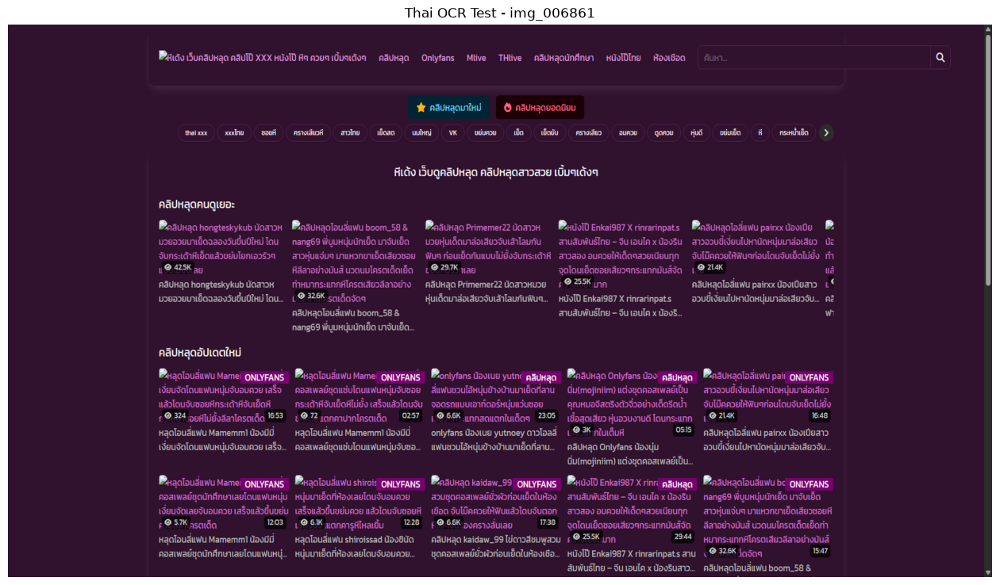

In [38]:
thai_candidates = candidate_run_df[
    candidate_run_df["image_id"].astype(str).map(IMAGE_LANGUAGE_BY_ID) == "th"
]

print("Thai candidate images:", len(thai_candidates))

thai_row = thai_candidates.iloc[0]
thai_image = load_rgb(thai_row["resolved_path"])

thai_detections = predict_image(test_engine, thai_image)

for detection in thai_detections:
    print(
        detection["text"],
        "| Confidence:",
        detection["confidence"]
    )

plt.figure(figsize=(16, 10))
plt.imshow(thai_image)
plt.axis("off")
plt.title(f"Thai OCR Test - {thai_row['image_id']}")
plt.show()

In [39]:
import gc
del test_engine
gc.collect()

spanish_engine = create_ocr_engine(
    language="es",
    ocr_version=OCR_MODEL_VERSION,
    cpu_threads=OCR_CPU_THREADS
)

print("Spanish OCR engine loaded successfully!")

Creating model: ('PP-OCRv5_server_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\PP-OCRv5_server_det`.
Creating model: ('latin_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\latin_PP-OCRv5_mobile_rec`.


Spanish OCR engine loaded successfully!


Spanish candidate images: 1
STEFANIA COPERTIN | Confidence: 0.9992819428443909
Galicia | Confidence: 0.9996334314346313
Online Banking | Confidence: 0.993608832359314
1 | Confidence: 0.16767844557762146
Sincronización de Cuentas | Confidence: 0.9798133373260498
Tu email | Confidence: 0.9999329447746277
Clave de correo electrónico | Confidence: 0.9879458546638489
FINALIZAR | Confidence: 0.9946479797363281
Operar con Online Banking implica aceptar los términos y condiciones en los que se ofrece elser | Confidence: 0.9937983751296997
Información sobre seguridad | Confidence: 0.9958641529083252


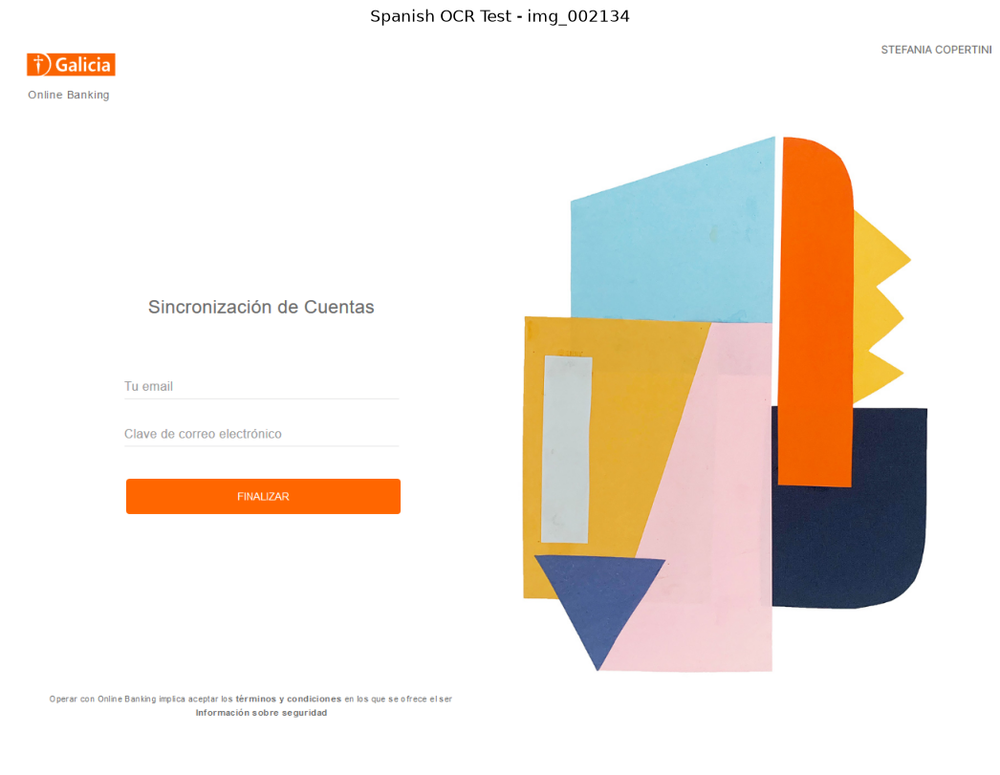

In [40]:
spanish_candidates = candidate_run_df[
    candidate_run_df["image_id"].astype(str).map(IMAGE_LANGUAGE_BY_ID) == "es"
]

print("Spanish candidate images:", len(spanish_candidates))

if not spanish_candidates.empty:
    spanish_row = spanish_candidates.iloc[0]
    spanish_image = load_rgb(spanish_row["resolved_path"])

    spanish_detections = predict_image(
        spanish_engine,
        spanish_image
    )

    for detection in spanish_detections:
        print(
            detection["text"],
            "| Confidence:",
            detection["confidence"]
        )
else:
    print("No Spanish candidate image found.")

plt.figure(figsize=(16, 10))
plt.imshow(spanish_image)
plt.axis("off")
plt.title(f"Spanish OCR Test - {spanish_row['image_id']}")
plt.show()

In [41]:
del spanish_engine
gc.collect()

french_engine = create_ocr_engine(
    language="fr",
    ocr_version=OCR_MODEL_VERSION,
    cpu_threads=OCR_CPU_THREADS
)

print("French OCR engine loaded successfully!")

Creating model: ('PP-OCRv5_server_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\PP-OCRv5_server_det`.
Creating model: ('latin_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\latin_PP-OCRv5_mobile_rec`.


French OCR engine loaded successfully!


French candidate images: 2
RNO 33,40 € -1,18 % | Confidence: 0.9631127715110779
FR | Confidence: 0.9995762705802917
Accessibilité | Confidence: 0.9986223578453064
OFF | Confidence: 0.9997128844261169
Renault | Confidence: 0.9988413453102112
Group | Confidence: 0.8570429086685181
Groupe | Confidence: 0.9998939037322998
Marques | Confidence: 0.9997849464416504
Responsabilité | Confidence: 0.9979957938194275
Magazine | Confidence: 0.9998573660850525
Reveal Renault Filante | Confidence: 0.9946981072425842
H-20 | Confidence: 0.9990947842597961
Carrières | Confidence: 0.9996069669723511
Investisseurs | Confidence: 0.9996933341026306
Presse | Confidence: 0.9998331069946289
C | Confidence: 0.24631094932556152
Les cookies, ça roule | Confidence: 0.9868574738502502
Notre site et ses partenaires utilisent des cookies pour mesurer l'audience et la performance du site. Les | Confidence: 0.9909000992774963
cookies nous permettent également de vous montrer des contenus personnalisés, publicitaires et

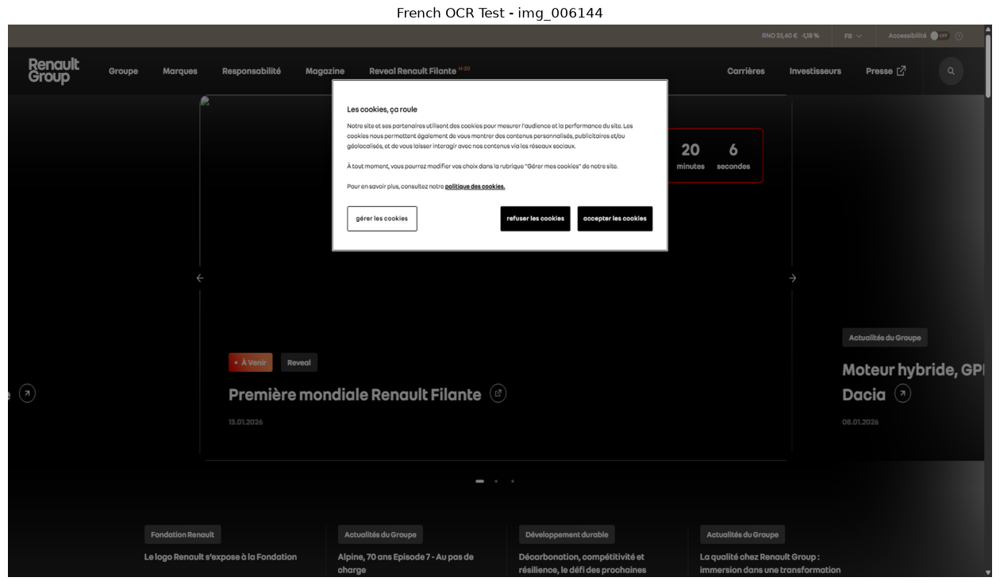

In [42]:
french_candidates = candidate_run_df[
    candidate_run_df["image_id"].astype(str).map(IMAGE_LANGUAGE_BY_ID) == "fr"
]

print("French candidate images:", len(french_candidates))

if not french_candidates.empty:
    french_row = french_candidates.iloc[0]
    french_image = load_rgb(french_row["resolved_path"])

    french_detections = predict_image(
        french_engine,
        french_image
    )

    for detection in french_detections:
        print(
            detection["text"],
            "| Confidence:",
            detection["confidence"]
        )

plt.figure(figsize=(16, 10))
plt.imshow(french_image)
plt.axis("off")
plt.title(f"French OCR Test - {french_row['image_id']}")
plt.show()

Image ID: img_018965
Extracted text:

SIMOP | Confidence: 0.980476975440979
Rechercher un produit. … | Confidence: 0.9522870182991028
Q | Confidence: 0.5170471668243408
ENREGISTRER MON PRODUIT | Confidence: 0.9995250701904297
EQUIPEMENTS POUR L'ENVIRONNEMENT | Confidence: 0.9981756210327148
Accueil | Confidence: 0.9998812675476074
A propos | Confidence: 0.9928481578826904
Traitement des eaux | Confidence: 0.9922192096710205
Industrie | Confidence: 0.9998669028282166
Actualités | Confidence: 0.9998986124992371
Contact | Confidence: 0.999870240688324
Redonnons le meilleur à la terre | Confidence: 0.9659073352813721
Traitement | Confidence: 0.997991681098938
des | Confidence: 0.9970080256462097
eaux pluviales | Confidence: 0.9945934414863586
Séparateurs d'hydrocarbures | Confidence: 0.9799354076385498
Décanteurs particulaires | Confidence: 0.9996721148490906
Equipements de bassins | Confidence: 0.9881927371025085
Aquamop | Confidence: 0.999470591545105
Voir les produits | Confidence: 0.95

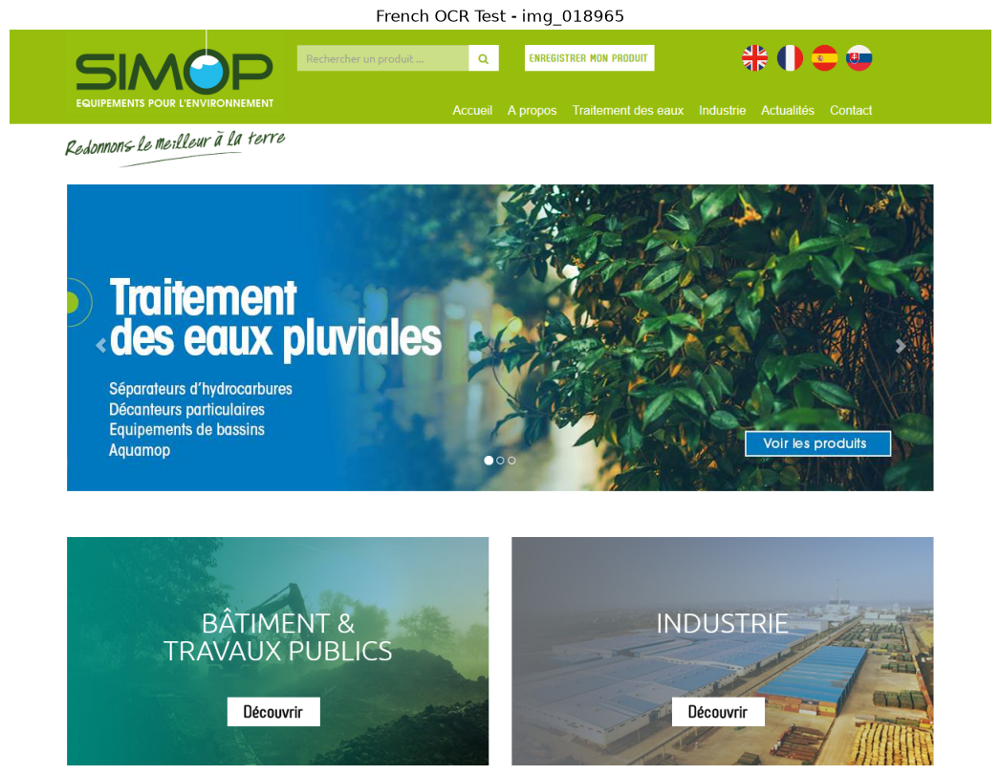

In [43]:
french_row_2 = french_candidates.iloc[1]

french_image_2 = load_rgb(
    french_row_2["resolved_path"]
)

french_detections_2 = predict_image(
    french_engine,
    french_image_2
)

print("Image ID:", french_row_2["image_id"])
print("Extracted text:\n")

for detection in french_detections_2:
    print(
        detection["text"],
        "| Confidence:",
        detection["confidence"]
    )

plt.figure(figsize=(16, 10))
plt.imshow(french_image_2)
plt.axis("off")
plt.title(f"French OCR Test - {french_row_2['image_id']}")
plt.show()

In [44]:
del french_engine
gc.collect()

indonesian_engine = create_ocr_engine(
    language="id",
    ocr_version=OCR_MODEL_VERSION,
    cpu_threads=OCR_CPU_THREADS
)

print("Indonesian OCR engine loaded successfully!")

Creating model: ('PP-OCRv5_server_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\PP-OCRv5_server_det`.
Creating model: ('latin_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\latin_PP-OCRv5_mobile_rec`.


Indonesian OCR engine loaded successfully!


Indonesian candidate images: 1
LOGIN FACEBOOK DI BAWAH INI UNTUK MENGHINDARI NONAKTIFKAN FACEBOOK ATAU | Confidence: 0.9957098364830017
PEMBLOKIRAN | Confidence: 0.9998539090156555
FACEBOOK | Confidence: 0.9991474151611328
" Indicates reguired field | Confidence: 0.9505554437637329
NAMA FACEBOOK | Confidence: 0.9984296560287476
* | Confidence: 0.8831110000610352
EMAIL ATAU NOMOR TELEPON | Confidence: 0.9515078067779541
* | Confidence: 0.4223690330982208
acE | Confidence: 0.8513038158416748
00 | Confidence: 0.7809473872184753
.:: | Confidence: 0.7470383048057556
PASSWORD FACEBOOK | Confidence: 0.9702932834625244
* | Confidence: 0.7336587309837341
. | Confidence: 0.4321673810482025
Bu site deneyiminizi kişiselleştirmek, site kullanimıni analiz etmekve kişiye özel tanitımlar sunabilmek için çerezler kullanir, www.youronlinechoices.eu | Confidence: 0.9792458415031433
Bana daha sonra hatirlat | Confidence: 0.9995014071464539
Kabul ediyorum | Confidence: 0.9995683431625366


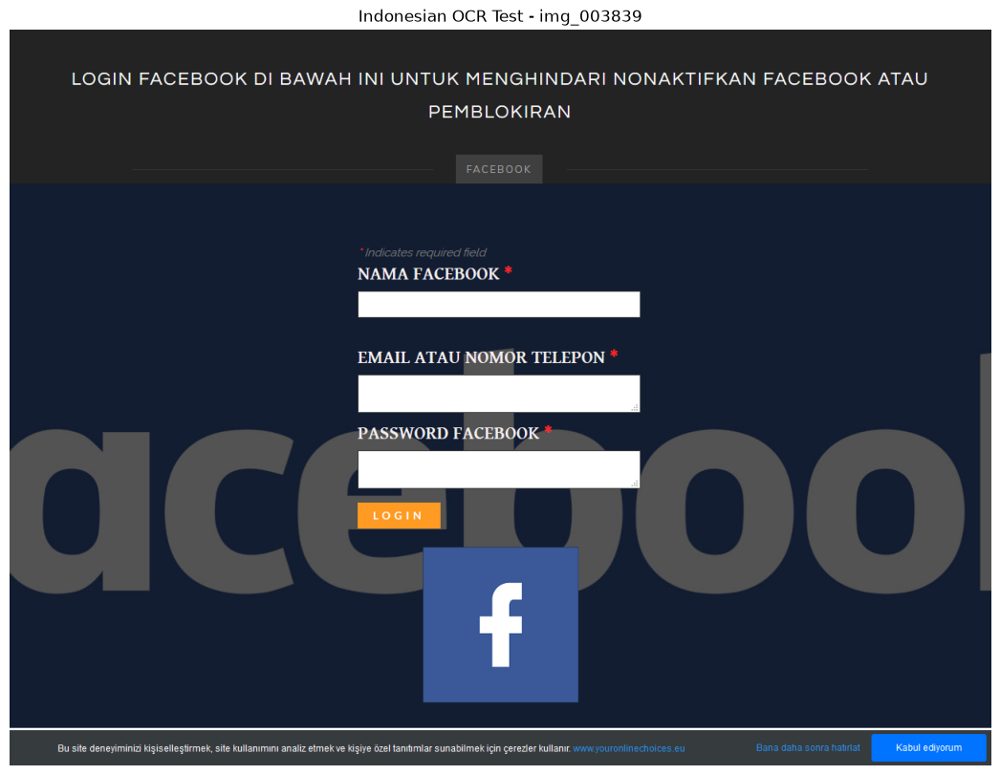

In [45]:
indonesian_candidates = candidate_run_df[
    candidate_run_df["image_id"].astype(str).map(IMAGE_LANGUAGE_BY_ID) == "id"
]

print("Indonesian candidate images:", len(indonesian_candidates))

if not indonesian_candidates.empty:
    indonesian_row = indonesian_candidates.iloc[0]
    indonesian_image = load_rgb(indonesian_row["resolved_path"])

    indonesian_detections = predict_image(
        indonesian_engine,
        indonesian_image
    )

    for detection in indonesian_detections:
        print(
            detection["text"],
            "| Confidence:",
            detection["confidence"]
        )
else:
    print("No Indonesian candidate image found.")

plt.figure(figsize=(16, 10))
plt.imshow(indonesian_image)
plt.axis("off")
plt.title(f"Indonesian OCR Test - {indonesian_row['image_id']}")
plt.show()

In [46]:
del indonesian_engine
gc.collect()

norwegian_engine = create_ocr_engine(
    language="no",
    ocr_version=OCR_MODEL_VERSION,
    cpu_threads=OCR_CPU_THREADS
)

print("Norwegian OCR engine loaded successfully!")

Creating model: ('PP-OCRv5_server_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\PP-OCRv5_server_det`.
Creating model: ('latin_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\latin_PP-OCRv5_mobile_rec`.


Norwegian OCR engine loaded successfully!


Norwegian candidate images: 1
Sykepleien | Confidence: 0.9999798536300659
Nyheter Fag Forskning Meninger | Confidence: 0.9752822518348694
Blogg | Confidence: 0.999935507774353
Tema_ Student_ Korona_ Stillinger | Confidence: 0.9267091751098633
Q | Confidence: 0.5582661628723145
, Søk | Confidence: 0.9116172790527344
Sykepleien jobb | Confidence: 0.9997118711471558
Autorisert sykepleier | Confidence: 0.9999690055847168
Nøkkelord | Confidence: 0.9997328519821167
For 3 dager siden | Confidence: 0.9800854921340942
Trondheim | Confidence: 0.9999291300773621
•Trondhjems Hospital | Confidence: 0.9823958277702332
TRONDHJEMS | Confidence: 0.99977046251297
HOSPITAL | Confidence: 0.9998738765716553
Sted | Confidence: 0.999964714050293
Til deg som trives i eldreomsorgen | Confidence: 0.9985995292663574
Om stillingen | Confidence: 0.9763955473899841
Sektor | Confidence: 0.9999592304229736
Diabetessykepleier 80 % stilling | Confidence: 0.9942025542259216
Kategori | Confidence: 0.9998396635055542
For 

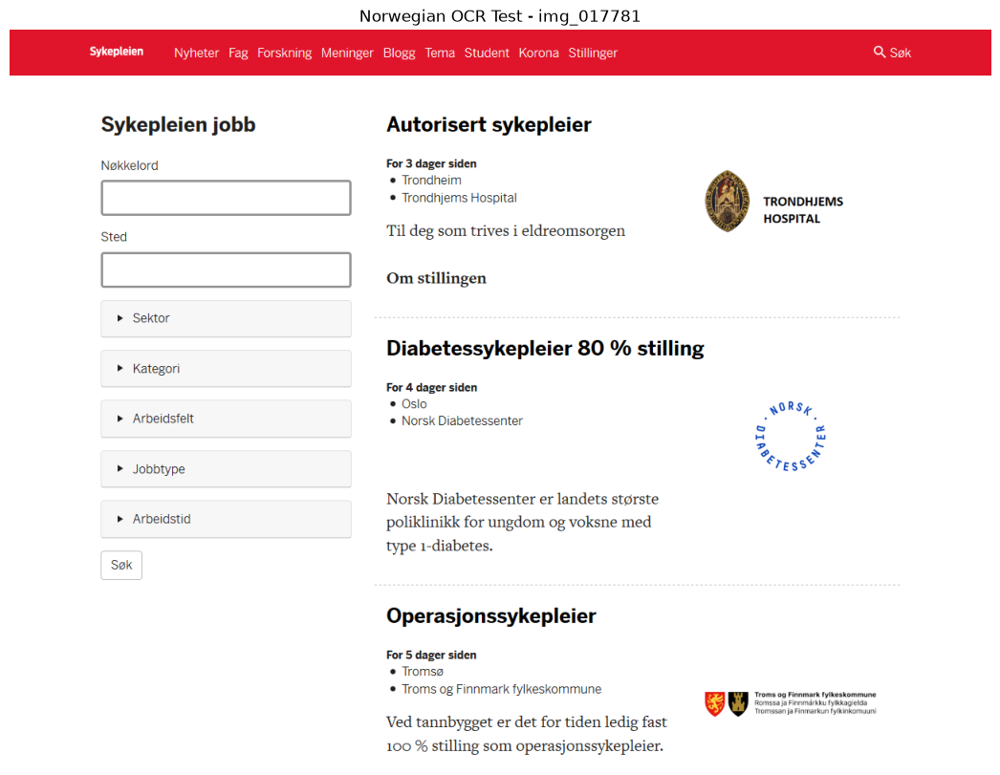

In [47]:
norwegian_candidates = candidate_run_df[
    candidate_run_df["image_id"].astype(str).map(IMAGE_LANGUAGE_BY_ID) == "no"
]

print("Norwegian candidate images:", len(norwegian_candidates))

if not norwegian_candidates.empty:
    norwegian_row = norwegian_candidates.iloc[0]
    norwegian_image = load_rgb(norwegian_row["resolved_path"])

    norwegian_detections = predict_image(
        norwegian_engine,
        norwegian_image
    )

    for detection in norwegian_detections:
        print(
            detection["text"],
            "| Confidence:",
            detection["confidence"]
        )
else:
    print("No Norwegian candidate image found.")

plt.figure(figsize=(16, 10))
plt.imshow(norwegian_image)
plt.axis("off")
plt.title(f"Norwegian OCR Test - {norwegian_row['image_id']}")
plt.show()

In [48]:
del norwegian_engine
gc.collect()

romanian_engine = create_ocr_engine(
    language="ro",
    ocr_version=OCR_MODEL_VERSION,
    cpu_threads=OCR_CPU_THREADS
)

print("Romanian OCR engine loaded successfully!")

Creating model: ('PP-OCRv5_server_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\PP-OCRv5_server_det`.
Creating model: ('latin_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\latin_PP-OCRv5_mobile_rec`.


Romanian OCR engine loaded successfully!


Romanian candidate images: 1
Nouă ne pasă ca datele tale personale să rămână confidențiale | Confidence: 0.9767091870307922
Atât noi, cât si partenerii noștri prelucrăm datele pentru a oferi | Confidence: 0.9704425930976868
Noi si partenerii nostri 618 stocăm si/sau accesăm informații pe dispozitivul dvs., precum identificatorii cookie unici pentru prelucrarea datelor cu | Confidence: 0.9862324595451355
Stocarea și/sau accesarea informaților de pe un dispozitiv. Măsurarea performanței reclamelor. Utilizarea profilurilor pentru selectarea | Confidence: 0.9744556546211243
caracter personal. Puteți accepta sau gestiona alegerile dvs. făcând clic mai jos sau în orice moment, pe pagina cu politica de confidentialitate. Aceste | Confidence: 0.9868707656860352
conținutului personalizat. Dezvoltarea și îmbunătățirea serviciilor. Crearea profilurilor de conținut personalizat. Utilizarea profilurilor pentru | Confidence: 0.9846868515014648
alegeri vor fi raportate partenerilor nostri si nu vă vo

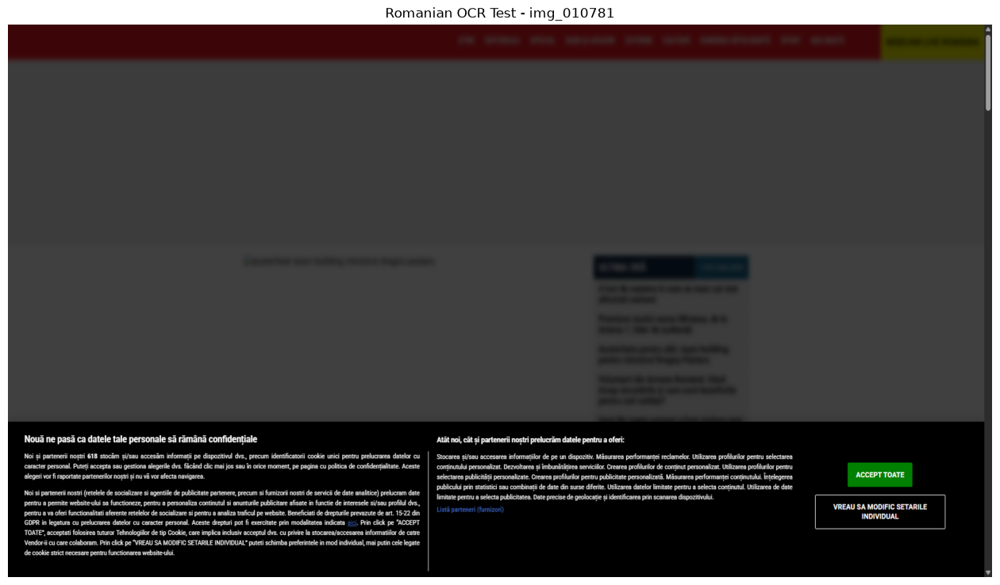

In [49]:
romanian_candidates = candidate_run_df[
    candidate_run_df["image_id"].astype(str).map(IMAGE_LANGUAGE_BY_ID) == "ro"
]

print("Romanian candidate images:", len(romanian_candidates))

if not romanian_candidates.empty:
    romanian_row = romanian_candidates.iloc[0]
    romanian_image = load_rgb(romanian_row["resolved_path"])

    romanian_detections = predict_image(
        romanian_engine,
        romanian_image
    )

    for detection in romanian_detections:
        print(
            detection["text"],
            "| Confidence:",
            detection["confidence"]
        )
else:
    print("No Romanian candidate image found.")

plt.figure(figsize=(16, 10))
plt.imshow(romanian_image)
plt.axis("off")
plt.title(f"Romanian OCR Test - {romanian_row['image_id']}")
plt.show()

In [50]:
del romanian_engine
gc.collect()

turkish_engine = create_ocr_engine(
    language="tr",
    ocr_version=OCR_MODEL_VERSION,
    cpu_threads=OCR_CPU_THREADS
)

print("Turkish OCR engine loaded successfully!")

Creating model: ('PP-OCRv5_server_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\PP-OCRv5_server_det`.
Creating model: ('latin_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\latin_PP-OCRv5_mobile_rec`.


Turkish OCR engine loaded successfully!


Turkish candidate images: 1
Linkedin | Confidence: 0.9992896914482117
Hemen katıl | Confidence: 0.9657703638076782
Oturum aç | Confidence: 0.990132749080658
Oturumu kapattınız | Confidence: 0.979248583316803
X | Confidence: 0.49884337186813354
Tam sürüm deneyimi için oturum açın | Confidence: 0.9909116625785828
Profesyonel | Confidence: 0.9998176693916321
E-posta veya telefon | Confidence: 0.9933579564094543
topluluğunuza hoş | Confidence: 0.9961893558502197
Şifre | Confidence: 0.961129367351532
Göster | Confidence: 0.9996625781059265
Şifrenizi mi | Confidence: 0.9844524264335632
Oturum | Confidence: 0.9989395141601562
geldiniz! | Confidence: 0.9998503923416138
unuttunuz? | Confidence: 0.9998081922531128
Qİş, kişi ve daha fazlasını bulun | Confidence: 0.9717231392860413
S | Confidence: 0.5172195434570312
Sizin için uygun olan | Confidence: 0.9798627495765686
ÖNERİLEN ARAMALAR | Confidence: 0.9860982298851013
Mühendislik | Confidence: 0.9999599456787109
İş Geliştirme | Confidence: 0.982

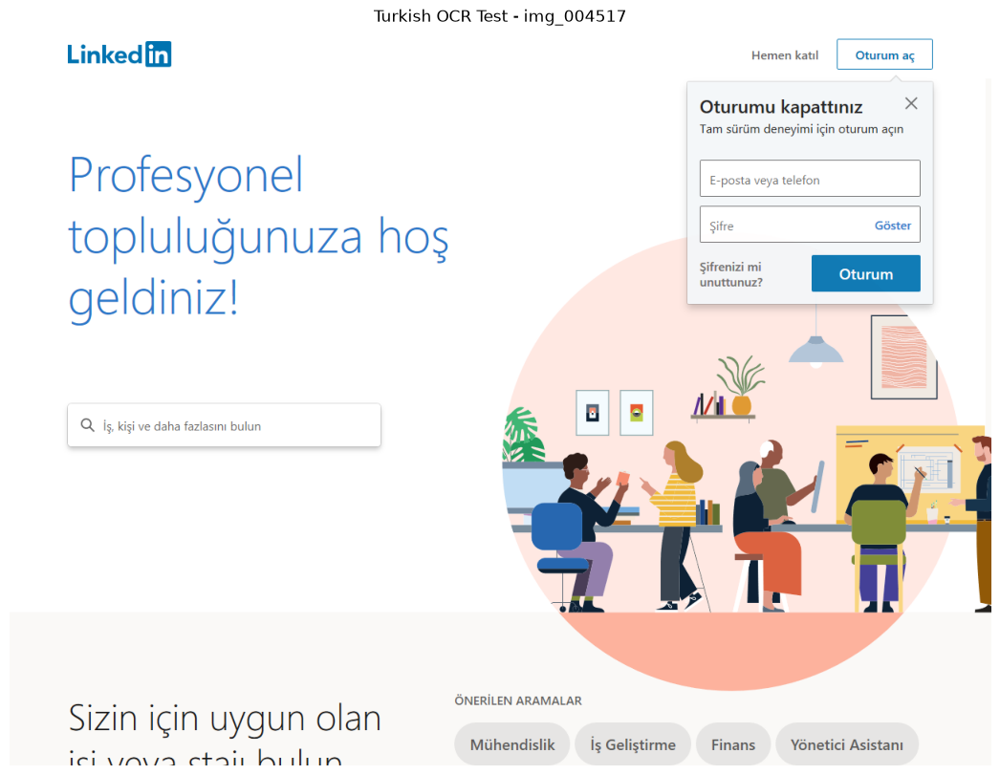

In [51]:
turkish_candidates = candidate_run_df[
    candidate_run_df["image_id"].astype(str).map(IMAGE_LANGUAGE_BY_ID) == "tr"
]

print("Turkish candidate images:", len(turkish_candidates))

if not turkish_candidates.empty:
    turkish_row = turkish_candidates.iloc[0]
    turkish_image = load_rgb(turkish_row["resolved_path"])

    turkish_detections = predict_image(
        turkish_engine,
        turkish_image
    )

    for detection in turkish_detections:
        print(
            detection["text"],
            "| Confidence:",
            detection["confidence"]
        )
else:
    print("No Turkish candidate image found.")

plt.figure(figsize=(16, 10))
plt.imshow(turkish_image)
plt.axis("off")
plt.title(f"Turkish OCR Test - {turkish_row['image_id']}")
plt.show()

In [52]:
del turkish_engine
gc.collect()

german_engine = create_ocr_engine(
    language="de",
    ocr_version=OCR_MODEL_VERSION,
    cpu_threads=OCR_CPU_THREADS
)

print("German OCR engine loaded successfully!")

Creating model: ('PP-OCRv5_server_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\PP-OCRv5_server_det`.
Creating model: ('latin_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\latin_PP-OCRv5_mobile_rec`.


German OCR engine loaded successfully!


German candidate images: 1
Jagdpraxis | Confidence: 0.8725419044494629
Das Online-Magazin für News & Ausrüstung | Confidence: 0.9956885576248169
Startseite | Confidence: 0.9999634027481079
Ausrüstung | Confidence: 0.9998106956481934
V | Confidence: 0.3377338945865631
Produkttests | Confidence: 0.9995241761207581
DAS Thema | Confidence: 0.9994027018547058
V | Confidence: 0.6321824193000793
Service | Confidence: 0.9981746077537537
NEWSLETTER | Confidence: 0.9999143481254578
4 Jetzt zum Jagdpraxis-Newsletter anmelden! | Confidence: 0.9911732077598572
HÄUFIG GELESEN | Confidence: 0.9993707537651062
Kommentar: | Confidence: 0.999751091003418
Kitze jetzt erlegen | Confidence: 0.9990742206573486
11.September 2020 -11:45 | Confidence: 0.9884634017944336
Erstellt in: DAS Thema | Confidence: 0.9901193976402283
Kommentar: Erst retten, dann | Confidence: 0.9977606534957886
töten? | Confidence: 0.9995546936988831
DAS THEMA | Confidence: 0.9804398417472839
NEWS | Confidence: 0.9994495511054993
NEWS 

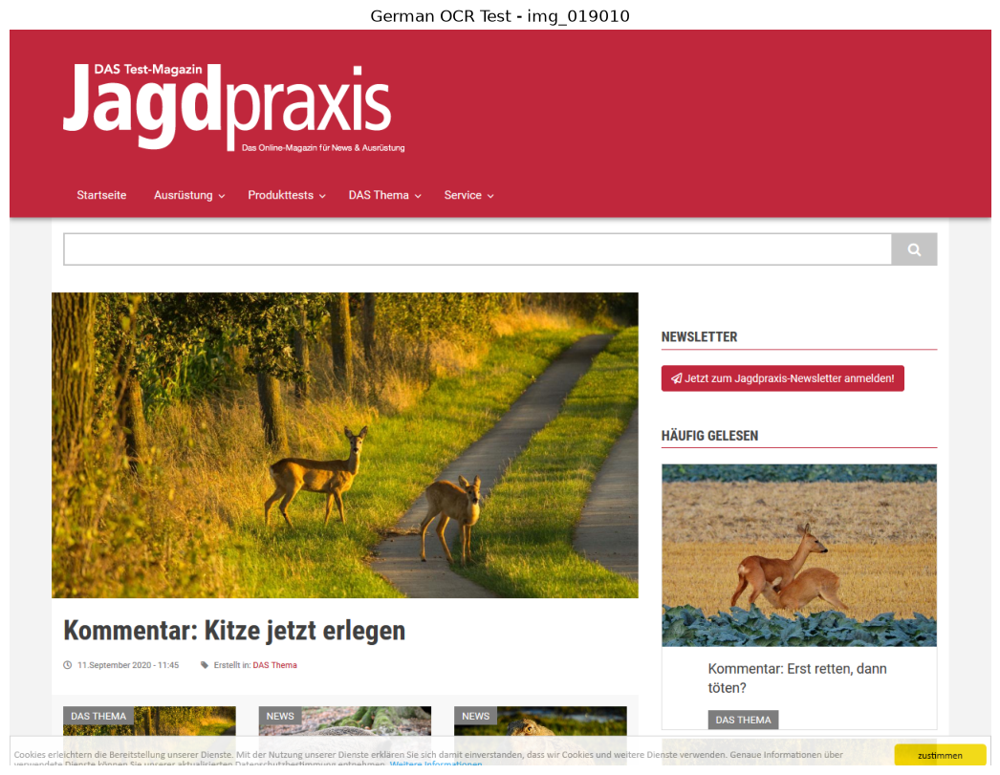

In [53]:
german_candidates = candidate_run_df[
    candidate_run_df["image_id"].astype(str).map(IMAGE_LANGUAGE_BY_ID) == "de"
]

print("German candidate images:", len(german_candidates))

if not german_candidates.empty:
    german_row = german_candidates.iloc[0]
    german_image = load_rgb(german_row["resolved_path"])

    german_detections = predict_image(
        german_engine,
        german_image
    )

    for detection in german_detections:
        print(
            detection["text"],
            "| Confidence:",
            detection["confidence"]
        )
else:
    print("No German candidate image found.")

plt.figure(figsize=(16, 10))
plt.imshow(german_image)
plt.axis("off")
plt.title(f"German OCR Test - {german_row['image_id']}")
plt.show()

In [54]:
del german_engine
gc.collect()


arabic_engine = create_ocr_engine(
    language="ar",
    ocr_version=OCR_MODEL_VERSION,
    cpu_threads=OCR_CPU_THREADS
)

print("Arabic OCR engine loaded successfully!")

Creating model: ('PP-OCRv5_server_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\PP-OCRv5_server_det`.


Creating model: ('arabic_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\arabic_PP-OCRv5_mobile_rec`.


Arabic OCR engine loaded successfully!


Arabic candidate images: 1
اعيد العملالي | Confidence: 0.6984014511108398
تواصل معنا | Confidence: 0.9496145248413086
المدونة | Confidence: 0.9981832504272461
عن الدمرداش هوم سكان | Confidence: 0.9543362855911255
الخدمات | Confidence: 0.9073328971862793
الرئيسية | Confidence: 0.933883786201477
فحوصات الأشعة بالمنزل | Confidence: 0.9891184568405151
P | Confidence: 0.9598186612129211
متخصصون في خدمات الأشعة | Confidence: 0.9980288147926331
المنزلية | Confidence: 0.9952316880226135
احصل على نتائج دقيقة وسريعة في منزلك | Confidence: 0.9551693797111511
واتساب | Confidence: 0.9935157895088196
اتصل بنا | Confidence: 0.9368739724159241
ما الذي نفعله؟ | Confidence: 0.9626617431640625
دمرداش هوم سكان مركز أشعة منزلية متنقلة مكون من فريق | Confidence: 0.9547814130783081
طبي مدرب ومُتخصص في عمل فحوصات الأشعة في المنزل | Confidence: 0.9232962727546692
بإستخدام أحدث أجهزة الأشعة الطبية | Confidence: 0.9722896814346313
ه | Confidence: 0.16462083160877228


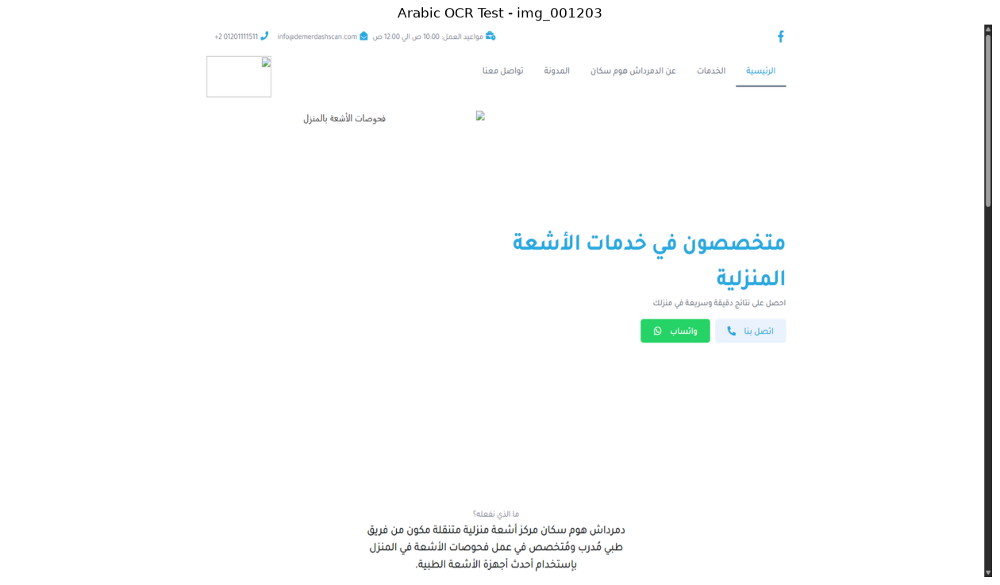

In [55]:
arabic_candidates = candidate_run_df[
    candidate_run_df["image_id"].astype(str).map(IMAGE_LANGUAGE_BY_ID) == "ar"
]

print("Arabic candidate images:", len(arabic_candidates))

if not arabic_candidates.empty:
    arabic_row = arabic_candidates.iloc[0]
    arabic_image = load_rgb(arabic_row["resolved_path"])

    arabic_detections = predict_image(
        arabic_engine,
        arabic_image
    )

    for detection in arabic_detections:
        print(
            detection["text"],
            "| Confidence:",
            detection["confidence"]
        )
else:
    print("No Arabic candidate image found.")

plt.figure(figsize=(16, 10))
plt.imshow(arabic_image)
plt.axis("off")
plt.title(f"Arabic OCR Test - {arabic_row['image_id']}")
plt.show()

In [56]:
del arabic_engine
gc.collect()

russian_engine = create_ocr_engine(
    language="ru",
    ocr_version=OCR_MODEL_VERSION,
    cpu_threads=OCR_CPU_THREADS
)

print("Russian OCR engine loaded successfully!")

Creating model: ('PP-OCRv5_server_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\PP-OCRv5_server_det`.
Creating model: ('eslav_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\smata\.paddlex\official_models\eslav_PP-OCRv5_mobile_rec`.


Russian OCR engine loaded successfully!


Russian candidate images: 1
Футбол | Confidence: 0.9849218726158142
Хоккей | Confidence: 0.9926370978355408
Бокс/ММА | Confidence: 0.9706788063049316
Фигурное катание | Confidence: 0.9915703535079956
Лыжи | Confidence: 0.9082089066505432
Баскетбол | Confidence: 0.973831832408905
Стиль жизни | Confidence: 0.9615562558174133
CyberPRO | Confidence: 0.9650218486785889
Ставки | Confidence: 0.9877567291259766
Еще | Confidence: 0.9910008311271667
Все новости | Confidence: 0.9805319309234619
Газета | Confidence: 0.9938201308250427
Статьи | Confidence: 0.9877579808235168
Матч-центр | Confidence: 0.9497498273849487
Игры | Confidence: 0.9384276866912842
Зарплаты КХЛ | Confidence: 0.9754971861839294
Фото | Confidence: 0.9789578318595886
Видео | Confidence: 0.9829530715942383
Live | Confidence: 0.9978023171424866
Рейтинг букмекеров | Confidence: 0.9694265723228455
Sport-express | Confidence: 0.9972744584083557
Уведомления | Confidence: 0.9943002462387085
Хоккей | Confidence: 0.9970821738243103
2-й 

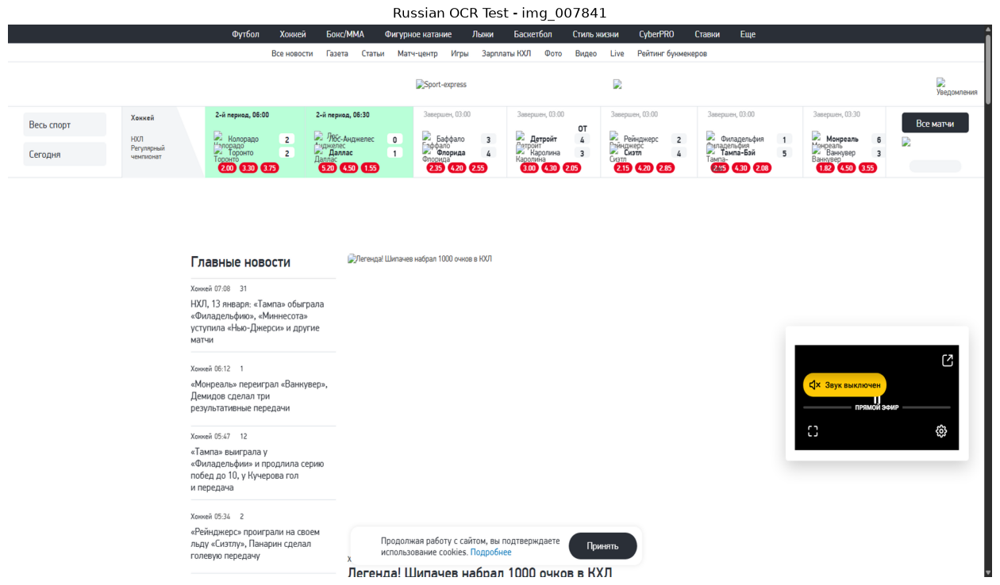

In [57]:
russian_candidates = candidate_run_df[
    candidate_run_df["image_id"].astype(str).map(IMAGE_LANGUAGE_BY_ID) == "ru"
]

print("Russian candidate images:", len(russian_candidates))

if not russian_candidates.empty:
    russian_row = russian_candidates.iloc[0]
    russian_image = load_rgb(russian_row["resolved_path"])

    russian_detections = predict_image(
        russian_engine,
        russian_image
    )

    for detection in russian_detections:
        print(
            detection["text"],
            "| Confidence:",
            detection["confidence"]
        )
else:
    print("No Russian candidate image found.")

plt.figure(figsize=(16, 10))
plt.imshow(russian_image)
plt.axis("off")
plt.title(f"Russian OCR Test - {russian_row['image_id']}")
plt.show()

## Multilingual OCR Pilot Run

In [62]:
if "russian_engine" in globals():
    del russian_engine

gc.collect()

english_sample = (
    candidate_run_df[
        candidate_run_df["detected_language"] == "English"
    ].head(4)
)

arabic_sample = (
    candidate_run_df[
        candidate_run_df["detected_language"] == "Arabic"
    ].head(1)
)

pilot_df = pd.concat(
    [english_sample, arabic_sample],
    ignore_index=True
)

print("Pilot sample:", len(pilot_df))
print("\nLanguage distribution:")
print(pilot_df["detected_language"].value_counts())

display(
    pilot_df[
        ["image_id", "label", "detected_language", "ocr_language"]
    ]
)

Pilot sample: 5

Language distribution:
detected_language
English    4
Arabic     1
Name: count, dtype: Int64


,image_id,label,detected_language,ocr_language
0,img_000642,phishing,English,en
1,img_001688,phishing,English,en
2,img_001810,phishing,English,en
3,img_001981,phishing,English,en
4,img_001203,phishing,Arabic,ar


In [63]:
pilot_results = language_pipeline.run(
    manifest=pilot_df,
    language_by_image_id=IMAGE_LANGUAGE_BY_ID,
    force=False,
    progress=True
)

OCR:   0%|          | 0/5 [00:00<?, ?it/s]

In [64]:
from pathlib import Path

print("Pilot results type:", type(pilot_results))

if isinstance(pilot_results, pd.DataFrame):
    print("Results shape:", pilot_results.shape)
    print("\nColumns:")
    print(pilot_results.columns.tolist())

    display(pilot_results.head())

print("\nOutput directory:")
print(LANGUAGE_TEST_OUTPUT_DIR)

print("\nSaved files:")
for file_path in sorted(LANGUAGE_TEST_OUTPUT_DIR.rglob("*")):
    if file_path.is_file():
        print(file_path.relative_to(LANGUAGE_TEST_OUTPUT_DIR))

Pilot results type: <class 'pandas.DataFrame'>
Results shape: (48, 30)

Columns:
['image_id', 'path', 'label', 'raw_text', 'filtered_text', 'cleaned_text', 'raw_detections', 'filtered_detections', 'detected_text_lines', 'confidence_scores', 'bounding_boxes', 'matched_keywords', 'keyword_counts', 'keyword_count', 'image_width', 'image_height', 'crop_mode', 'crop_metadata', 'preprocessing_applied', 'contrast_sharpen_applied', 'ocr_model_language', 'ocr_version', 'confidence_threshold', 'resize_max_side', 'grayscale_applied', 'denoising_applied', 'threshold_value', 'processing_time_seconds', 'ocr_status', 'error_message']


,image_id,path,label,raw_text,filtered_text,cleaned_text,raw_detections,filtered_detections,detected_text_lines,confidence_scores,...,ocr_model_language,ocr_version,confidence_threshold,resize_max_side,grayscale_applied,denoising_applied,threshold_value,processing_time_seconds,ocr_status,error_message
0,img_000642,D:\DEPI Graduation Project\computer_vision_mil...,phishing,bitly loge\nPspam warning illustration\nWarnin...,bitly loge\nPspam warning illustration\nWarnin...,bitly loge\nPspam warning illustration\nWarnin...,"[{'text': 'bitly loge', 'confidence': 0.827385...","[{'text': 'bitly loge', 'confidence': 0.827385...",19,"[0.827386, 0.95752, 0.997306, 0.987437, 0.9999...",...,en,PP-OCRv5,0.4,1600,False,False,None,63.701821,success,None
1,img_001203,D:\DEPI Graduation Project\computer_vision_mil...,phishing,اعيد العملصالي\nتواصل معنا\nالمدونة\nعن الدمرد...,اعيد العملصالي\nتواصل معنا\nالمدونة\nعن الدمرد...,اعيد العملصالي\nتواصل معنا\nالمدونة\nعن الدمرد...,"[{'text': 'اعيد العملصالي', 'confidence': 0.57...","[{'text': 'اعيد العملصالي', 'confidence': 0.57...",18,"[0.573986, 0.996323, 0.998542, 0.925001, 0.842...",...,ar,PP-OCRv5,0.4,1600,False,False,None,36.313826,success,None
2,img_001688,D:\DEPI Graduation Project\computer_vision_mil...,phishing,D\n404 PAGE NOT FOUND\n©2016-2026 UME.la All r...,404 PAGE NOT FOUND\n©2016-2026 UME.la All righ...,404 PAGE NOT FOUND\n©2016-2026 UME.la All righ...,"[{'text': 'D', 'confidence': 0.322029054164886...","[{'text': '404 PAGE NOT FOUND', 'confidence': ...",4,"[0.995274, 0.963757, 0.974249, 0.999174]",...,en,PP-OCRv5,0.4,1600,False,False,None,32.245751,success,None
3,img_001810,D:\DEPI Graduation Project\computer_vision_mil...,phishing,account log in\nLog in\nYou Need to Log In to ...,account log in\nLog in\nYou Need to Log In to ...,account log in\nLog in\nYou Need to Log In to ...,"[{'text': 'account log in', 'confidence': 0.96...","[{'text': 'account log in', 'confidence': 0.96...",7,"[0.96536, 0.999938, 0.975889, 0.974556, 0.9999...",...,en,PP-OCRv5,0.4,1600,False,False,None,29.584255,success,None
4,img_001981,D:\DEPI Graduation Project\computer_vision_mil...,phishing,mbna\nHome\nContact Us\nmbna\nCredit Cards\nSe...,mbna\nHome\nContact Us\nmbna\nCredit Cards\nSe...,mbna\nHome\nContact Us\nmbna\nCredit Cards\nSe...,"[{'text': 'mbna', 'confidence': 0.999929428100...","[{'text': 'mbna', 'confidence': 0.999929428100...",54,"[0.999929, 0.999953, 0.999364, 0.999832, 0.999...",...,en,PP-OCRv5,0.4,1600,False,False,None,43.003755,success,None



Output directory:
D:\DEPI Graduation Project\computer_vision_milstone\reports\ocr\language_candidates

Saved files:
checkpoints\img_000642.json
checkpoints\img_001203.json
checkpoints\img_001688.json
checkpoints\img_001810.json
checkpoints\img_001981.json
checkpoints\img_002134.json
checkpoints\img_002178.json
checkpoints\img_002551.json
checkpoints\img_002878.json
checkpoints\img_003131.json
checkpoints\img_003308.json
checkpoints\img_003456.json
checkpoints\img_003594.json
checkpoints\img_003645.json
checkpoints\img_003839.json
checkpoints\img_003914.json
checkpoints\img_004267.json
checkpoints\img_004517.json
checkpoints\img_004632.json
checkpoints\img_004734.json
checkpoints\img_005363.json
checkpoints\img_005654.json
checkpoints\img_005674.json
checkpoints\img_006106.json
checkpoints\img_006144.json
checkpoints\img_006861.json
checkpoints\img_007841.json
checkpoints\img_008111.json
checkpoints\img_008190.json
checkpoints\img_009818.json
checkpoints\img_010781.json
checkpoints\img

In [65]:
print("OCR Status:")
print(pilot_results["ocr_status"].value_counts(dropna=False))

print("\nLanguage routing:")
display(
    pilot_results.groupby("ocr_model_language").agg(
        images=("image_id", "count"),
        successful=("ocr_status", lambda x: (x == "success").sum()),
        avg_processing_time=("processing_time_seconds", "mean"),
        total_text_lines=("detected_text_lines", "sum")
    ).round(2)
)

print("\nErrors:")
display(
    pilot_results[
        pilot_results["ocr_status"] != "success"
    ][["image_id", "ocr_model_language", "error_message"]]
)

print("\nExtracted text preview:")
for _, row in pilot_results.iterrows():
    print(f"\nImage: {row['image_id']}")
    print(f"Language: {row['ocr_model_language']}")
    print(f"Text lines: {row['detected_text_lines']}")
    print(str(row["cleaned_text"])[:300])

OCR Status:
ocr_status
success    48
Name: count, dtype: int64

Language routing:


,images,successful,avg_processing_time,total_text_lines
ocr_model_language,,,,
ar,1,1,36.31,18
de,1,1,35.07,23
en,37,37,38.60,1180
es,1,1,28.86,9
fr,2,2,40.12,75
id,1,1,35.08,17
no,1,1,33.44,40
ro,1,1,52.02,21
ru,1,1,47.87,124



Errors:


,image_id,ocr_model_language,error_message



Extracted text preview:

Image: img_000642
Language: en
Text lines: 19
bitly loge
Pspam warning illustration
flagged by Bitly's systems
as
potentially harmful.
We recommend you close your browser window and notify
the person who sent you the link.
Why was this link flagged?
Bitly displays this warning when a link has been flagged as suspect. 

Image: img_001203
Language: ar
Text lines: 18
اعيد العملصالي
تواصل معنا
المدونة
عن الدمرداش هوم سكان
الخدمات
الرنيسية
فحوصات الأشعة بالمنزل
P
متخصصون في خدمات الأشعة
المنزلية
احصل على نتائج دقيقة وسريعة في منزلك
c
واتساب
اتصل بنا
ما الذي نفعله؟
دمرداش هوم سكان مركز أشعة منزلية متنقلة مكون من فريق
طبي مُدرب ومُتخصص في عمل فحوصات الأشعة في المنزل

Image: img_001688
Language: en
Text lines: 4
404 PAGE NOT FOUND
©2016-2026 UME.la All rights reserved
Support & Help | Privacy Policy | Contacts
Made in the UK

Image: img_001810
Language: en
Text lines: 7
account log in
Log in
You Need to Log In to View This Information
Email / Handle
Password
Forgot pa

In [66]:
print("Resume:", language_pipeline.config.resume)
print("Output:", language_pipeline.config.output_dir)
print("Candidate images:", len(candidate_run_df))
print("\nImages per language:")
print(candidate_run_df["ocr_language"].value_counts())

Resume: True
Output: D:\DEPI Graduation Project\computer_vision_milstone\reports\ocr\language_candidates
Candidate images: 48

Images per language:
ocr_language
en    37
fr     2
ar     1
es     1
id     1
tr     1
th     1
ru     1
ro     1
no     1
de     1
Name: count, dtype: int64


In [67]:
import gc
import time

language_pipeline.engines.clear()
gc.collect()

language_run_summary = []
full_ocr_results = None

languages = candidate_run_df["ocr_language"].dropna().unique()

print("Languages to process:", len(languages))
print("Total candidate images:", len(candidate_run_df))

for lang in languages:

    language_group = candidate_run_df[
        candidate_run_df["ocr_language"] == lang
    ].copy()

    print("\n" + "=" * 50)
    print(f"Processing language: {lang}")
    print(f"Images: {len(language_group)}")
    print("=" * 50)

    start_time = time.perf_counter()

    full_ocr_results = language_pipeline.run(
        manifest=language_group,
        language_by_image_id=IMAGE_LANGUAGE_BY_ID,
        force=False,
        progress=True
    )

    elapsed = time.perf_counter() - start_time

    language_pipeline.engines.clear()
    gc.collect()

    language_run_summary.append({
        "language": lang,
        "images": len(language_group),
        "elapsed_seconds": round(elapsed, 2)
    })

    print(f"Completed {lang} in {elapsed:.2f} seconds")

print("\nAll language groups processed.")

display(pd.DataFrame(language_run_summary))

Languages to process: 11
Total candidate images: 48

Processing language: en
Images: 37


OCR:   0%|          | 0/37 [00:00<?, ?it/s]

Completed en in 0.14 seconds

Processing language: ar
Images: 1


OCR:   0%|          | 0/1 [00:00<?, ?it/s]

Completed ar in 0.13 seconds

Processing language: es
Images: 1


OCR:   0%|          | 0/1 [00:00<?, ?it/s]

... (14 outputs left out)

Completed no in 0.16 seconds

Processing language: de
Images: 1


OCR:   0%|          | 0/1 [00:00<?, ?it/s]

Completed de in 0.13 seconds

All language groups processed.


,language,images,elapsed_seconds
0,en,37,0.14
1,ar,1,0.13
2,es,1,0.12
3,id,1,0.15
4,tr,1,0.13
5,fr,2,0.16
6,th,1,0.15
7,ru,1,0.16
8,ro,1,0.14
9,no,1,0.16


In [68]:
print("Total result rows:", len(full_ocr_results))
print("Unique images:", full_ocr_results["image_id"].nunique())

print("\nOCR Status:")
print(full_ocr_results["ocr_status"].value_counts(dropna=False))

print("\nLanguage distribution:")
display(
    full_ocr_results.groupby("ocr_model_language").agg(
        images=("image_id", "nunique"),
        successful=("ocr_status", lambda x: (x == "success").sum()),
        failed=("ocr_status", lambda x: (x != "success").sum()),
        avg_time=("processing_time_seconds", "mean")
    ).round(2)
)

processed_ids = set(full_ocr_results["image_id"].astype(str))
expected_ids = set(candidate_run_df["image_id"].astype(str))

print("\nMissing images:", len(expected_ids - processed_ids))
print("Unexpected images:", len(processed_ids - expected_ids))

Total result rows: 48
Unique images: 48

OCR Status:
ocr_status
success    48
Name: count, dtype: int64

Language distribution:


,images,successful,failed,avg_time
ocr_model_language,,,,
ar,1,1,0,36.31
de,1,1,0,35.07
en,37,37,0,38.60
es,1,1,0,28.86
fr,2,2,0,40.12
id,1,1,0,35.08
no,1,1,0,33.44
ro,1,1,0,52.02
ru,1,1,0,47.87



Missing images: 0
Unexpected images: 0


In [69]:
from pathlib import Path
import pandas as pd

pilot_report_dir = REPORTS_DIR / "multilingual_ocr_pilot"
pilot_report_dir.mkdir(parents=True, exist_ok=True)

# Save full OCR results
full_ocr_results.to_csv(
    pilot_report_dir / "multilingual_ocr_results.csv",
    index=False,
    encoding="utf-8-sig"
)

# Save language performance summary
language_summary = (
    full_ocr_results
    .groupby("ocr_model_language")
    .agg(
        images=("image_id", "nunique"),
        successful=("ocr_status", lambda x: (x == "success").sum()),
        failed=("ocr_status", lambda x: (x != "success").sum()),
        avg_time_seconds=("processing_time_seconds", "mean")
    )
    .reset_index()
    .round(2)
)

language_summary.to_csv(
    pilot_report_dir / "language_performance_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Pilot reports saved successfully:")
print(pilot_report_dir)

Pilot reports saved successfully:
D:\DEPI Graduation Project\computer_vision_milstone\reports\multilingual_ocr_pilot


In [70]:
# Select all 48 pilot images
review_df = full_ocr_results[
    [
        "image_id",
        "path",
        "label",
        "ocr_model_language",
        "raw_text",
        "cleaned_text",
        "confidence_scores",
        "ocr_status"
    ]
].copy()

# Add manual review columns
review_df["review_status"] = "pending"
review_df["text_quality"] = ""
review_df["review_notes"] = ""

# Save review file
review_path = (
    REPORTS_DIR
    / "multilingual_ocr_pilot"
    / "manual_ocr_review.csv"
)

review_df.to_csv(
    review_path,
    index=False,
    encoding="utf-8-sig"
)

print("Review file created:", review_path)
print("Images to review:", len(review_df))

display(
    review_df[
        ["image_id", "label", "ocr_model_language", "ocr_status"]
    ].head(10)
)

Review file created: D:\DEPI Graduation Project\computer_vision_milstone\reports\multilingual_ocr_pilot\manual_ocr_review.csv
Images to review: 48


,image_id,label,ocr_model_language,ocr_status
0,img_000642,phishing,en,success
1,img_001203,phishing,ar,success
2,img_001688,phishing,en,success
3,img_001810,phishing,en,success
4,img_001981,phishing,en,success
5,img_002134,phishing,es,success
6,img_002178,phishing,en,success
7,img_002551,phishing,en,success
8,img_002878,phishing,en,success
9,img_003131,phishing,en,success


## OCR Quality

In [71]:
smoke_test_results = (
    full_ocr_results
    .groupby("label", group_keys=False)
    .head(2)
    .reset_index(drop=True)
)

print("Selected samples:")
print(smoke_test_results["label"].value_counts())

display(
    smoke_test_results[
        ["image_id", "label", "ocr_model_language", "ocr_status"]
    ]
)

Selected samples:
label
phishing      2
legitimate    2
Name: count, dtype: int64


,image_id,label,ocr_model_language,ocr_status
0,img_000642,phishing,en,success
1,img_001203,phishing,ar,success
2,img_006144,legitimate,fr,success
3,img_006861,legitimate,th,success


In [72]:
import cv2

def display_ocr_sample(row):

    image = cv2.imread(str(row["path"]))

    if image is None:
        print("Could not load:", row["path"])
        return

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width = image.shape[:2]
    crop_height = int(height * ABOVE_FOLD_RATIO)

    top_crop = image[:crop_height, :]

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    axes[0].imshow(image)
    axes[0].set_title(f"Original | {row['label']}")
    axes[0].axis("off")

    axes[1].imshow(top_crop)
    axes[1].set_title("Top Crop (40%)")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    print("Image ID:", row["image_id"])
    print("Language:", row["ocr_model_language"])
    print("Status:", row["ocr_status"])
    print("Processing Time:",
          round(row["processing_time_seconds"], 2), "seconds")

    print("\nExtracted Text:")
    print(row["raw_text"])

    print("\nConfidence Scores:")
    print(row["confidence_scores"])

    print("\nBounding Boxes:")
    print(row["bounding_boxes"])

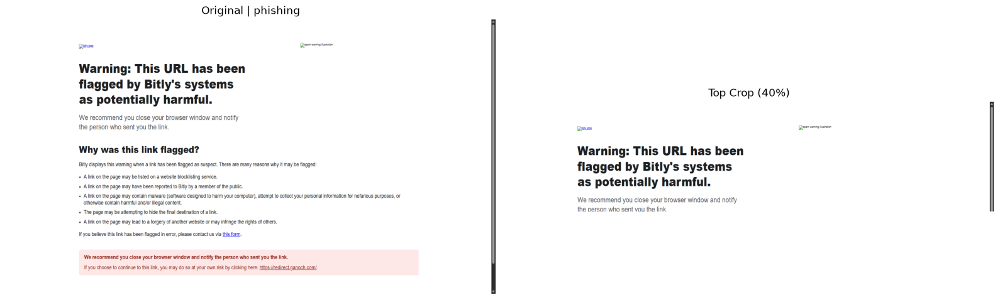

Image ID: img_000642
Language: en
Status: success
Processing Time: 63.7 seconds

Extracted Text:
bitly loge
Pspam warning illustration
flagged by Bitly's systems
as
potentially harmful.
−
We recommend you close your browser window and notify
the person who sent you the link.
Why was this link flagged?
Bitly displays this warning when a link has been flagged as suspect. There are many reasons why it may be flagged:
A link on the page may be listed on a website blocklisting service.
A link on the page may have been reported to Bitly by a member of the public.
•A link on the page may contain malware (software designed to harm your computer), attempt to collect your personal information for nefarious purposes, or
otherwise contain harmful and/or illegal content.
•The page may be attempting to hide the final destination of a link.
A link on the page may lead to a forgery of another website or may infringe the rights of others.
If you believe this link has been flagged in error, please conta

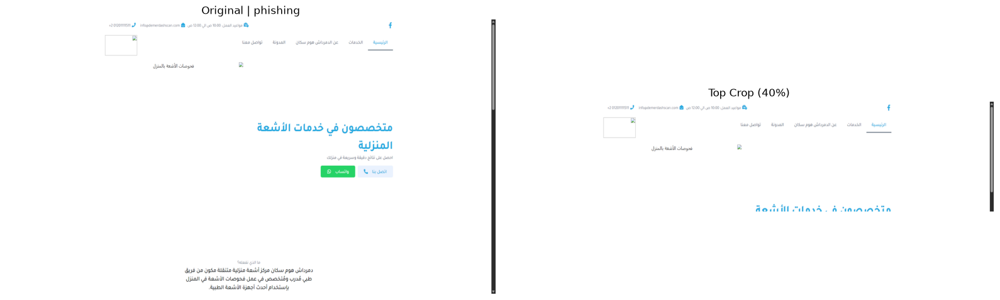

Image ID: img_001203
Language: ar
Status: success
Processing Time: 36.31 seconds

Extracted Text:
اعيد العملصالي
تواصل معنا
المدونة
عن الدمرداش هوم سكان
الخدمات
الرنيسية
فحوصات الأشعة بالمنزل
P
متخصصون في خدمات الأشعة
المنزلية
احصل على نتائج دقيقة وسريعة في منزلك
c
واتساب
U
اتصل بنا
ما الذي نفعله؟
دمرداش هوم سكان مركز أشعة منزلية متنقلة مكون من فريق
طبي مُدرب ومُتخصص في عمل فحوصات الأشعة في المنزل
بإستخدام أحدث أجهزة الأشعة الطبية

Confidence Scores:
[0.5739861726760864, 0.996322751045227, 0.9985424280166626, 0.925000786781311, 0.8422712683677673, 0.8852964639663696, 0.9797300696372986, 0.8828759789466858, 0.9724050760269165, 0.9949346780776978, 0.938222348690033, 0.6144280433654785, 0.9909424781799316, 0.988581657409668, 0.9126005172729492, 0.9751158952713013, 0.9173709750175476, 0.9736260175704956]

Bounding Boxes:
[[[333, 7], [793, 8], [793, 29], [333, 28]], [[769, 64], [842, 64], [842, 85], [769, 85]], [[867, 64], [920, 64], [920, 85], [867, 85]], [[943, 65], [1088, 65], [1088, 85]

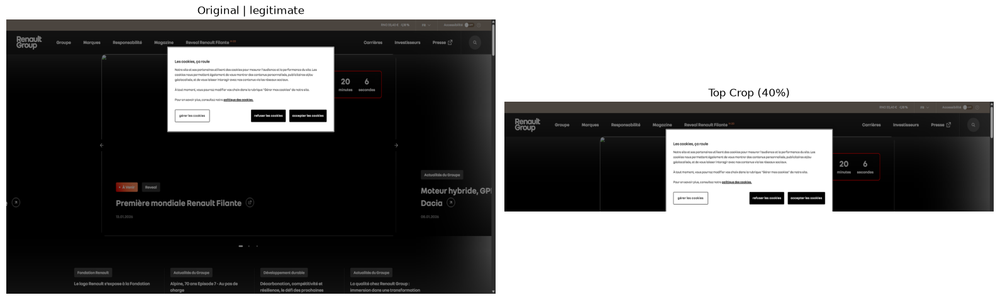

Image ID: img_006144
Language: fr
Status: success
Processing Time: 51.14 seconds

Extracted Text:
RNO 33,40 € -1,18 %
FR 
Accessibilité
OFF
Renault
Group
Groupe
Marques
Responsabilité
Magazine
Reveal Renault Filante
H-20
Carrières
Investisseurs
Presse
Les cookies, ca roule
Notre site et ses partenaires utilisent des cookies pour mesurer l'audience et la performance du site. Les
cookies nous permettent également de vous montrer des contenus personnalisés, publicitaires et/ou
géolocalisós, et de vous laisser interagir avec nos contenus via les réseaux sociaux.
20
6
À tout moment, vous pourrez modifier vos choix dans la rubrique "Gérer mes cookies" de notre sito.
minutes
secondes
Pour en savoir plus, consultez notre politique des cookies.
gérer les cookies
refuser les cookies
accepter les cookies
Actualités du Groupe
• À Venir
Reveal
Moteur hybride, GPI
7
Première mondiale Renault Filante
C
Dacia
7
13.01.2026
08.01.2026
Fondation Renault
Actualités du Groupe
Développement durable
Actualit

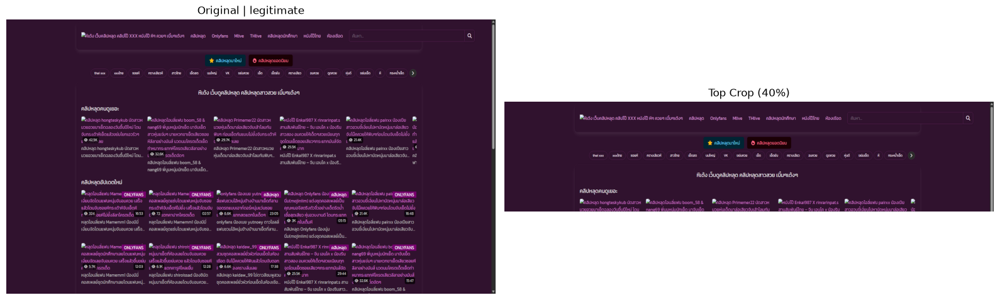

Image ID: img_006861
Language: th
Status: success
Processing Time: 146.45 seconds

Extracted Text:
หีเด้ง เว็บคลิปหลุด คลิปโป XXX หนังโป หีๆ ควยๆ เบิ้มๆเด้งๆ
คลิปหลุด
Onlyfans
Mlive THlive
คลิปหลุดนักศึกษา
หนังโปไทย
ห้องเชือด
ค้นหา...
Q
 คลิปหลุดมาใหม่
 คลิปหลุดยอดนิี่ยม
thaixxx
xoxInย
ชอยหี
ครางเสียวหี
สาวโทย
เย็ดสด
นมใหญ่
VK
ขย่มควย
เย็ด
เย็ดยับ
ครางเสียว
อมควย
ดูดควย
หุ่นดี
ขย่มเย็ด
ซี
กระหน้าเย็ด
หีเด้ง เว็บดูคลิปหลุด คลิปหลุดสาวสวย เบิ้มๆเด้งๆ
คลิปหลุดคนดูเยอะ
คลิปหลุด hongteskykub นัดสาวห
คลิปหลุดโอนลี่แฟน boom_58 &
คลิปหลุด Primemer22 นัดสาวห
หนังโป Enkai987 X rinrarinpat.s
คลิปหลุดโอลี่แฟน pairxx น้องเปีย
มวยอวยมาเย็ดฉลองวันขึ้นปีใหม่ โดน
ang69 พี่บูมหนุ่มนักเย็ด มาจับเย็ด
มวยหุ่นเด็ดมาล่อเสียวจับเล้าโลมกัน
สานสัมพันธ์ไทย - จีน เอนไค × น้องริน
สาวอวบขี้เงี่ยนไปหานัดหนุ่มมาล่อเสียว น้อ
จับกระเด้าหีเย็ดแล้วขย่มโยกเอวรัวๆ
สาวหุ่นแจ่มๆ มาแหวกขาเย็ดเสียวชอย
พฟันๆ ก่อนเย็ดกันแบบไม่ยั้งจับกระเด้าหี
สาวสอง อมควยให้เด็ดๆสวยเนียนทุก
จับโมีคควยให้ฟินๆก่อนโดนจับเย็ดไม่ยั้ง ท่ำ
42.5K
ลย
หีล

In [73]:
for _, row in smoke_test_results.iterrows():
    display_ocr_sample(row)

In [74]:
manual_reviews = {
    "img_000642": {
        "text_quality": "Good",
        "review_notes": "Clear extraction of the Bitly warning, main paragraphs, and destination URL."
    },
    "img_001203": {
        "text_quality": "Good",
        "review_notes": "Arabic headings and main service description extracted. Minor character errors and noise."
    },
    "img_006144": {
        "text_quality": "Good",
        "review_notes": "French navigation, cookie consent text, buttons, and news headings extracted."
    },
    "img_006861": {
        "text_quality": "Partial",
        "review_notes": "Many Thai text regions detected, but dense small text contains recognition errors."
    }
}

for image_id, review in manual_reviews.items():

    mask = review_df["image_id"] == image_id

    review_df.loc[mask, "text_quality"] = review["text_quality"]
    review_df.loc[mask, "review_notes"] = review["review_notes"]
    review_df.loc[mask, "review_status"] = "reviewed"

review_df.to_csv(
    review_path,
    index=False,
    encoding="utf-8-sig"
)

print("Manual review updated.")

Manual review updated.


## Text Cleaning

In [75]:

import re
import unicodedata

def clean_ocr_text(text):
    if pd.isna(text):
        return ""

    # Normalize Unicode characters
    text = unicodedata.normalize("NFKC", str(text))

    # Remove invisible characters
    text = text.replace("\u200b", "").replace("\ufeff", "")

    # Remove Arabic diacritics and tatweel
    text = re.sub(r"[\u064B-\u065F\u0670\u0640]", "", text)

    # Normalize letter casing
    text = text.casefold()

    # Remove unwanted symbols while preserving multilingual text,
    # URLs, emails, and useful punctuation
    text = re.sub(
        r"[^\w\s:/?&=.%#@+\-'’]",
        " ",
        text,
        flags=re.UNICODE
    )

    # Normalize spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

processed_results = full_ocr_results.copy()

processed_results["processed_text"] = (
    processed_results["raw_text"].apply(clean_ocr_text)
)

print("Total images:", len(processed_results))
print("Missing raw texts:", processed_results["raw_text"].isna().sum())
print("Empty processed texts:", (processed_results["processed_text"] == "").sum())

print("\nProcessed text preview:")

preview_columns = [
    "image_id",
    "label",
    "ocr_model_language",
    "raw_text",
    "processed_text"
]

display(
    processed_results[preview_columns].head(6)
)


Total images: 48
Missing raw texts: 0
Empty processed texts: 0

Processed text preview:


,image_id,label,ocr_model_language,raw_text,processed_text
0,img_000642,phishing,en,bitly loge\nPspam warning illustration\nWarnin...,bitly loge pspam warning illustration warning:...
1,img_001203,phishing,ar,اعيد العملصالي\nتواصل معنا\nالمدونة\nعن الدمرد...,اعيد العملصالي تواصل معنا المدونة عن الدمرداش ...
2,img_001688,phishing,en,D\n404 PAGE NOT FOUND\n©2016-2026 UME.la All r...,d 404 page not found 2016-2026 ume.la all righ...
3,img_001810,phishing,en,account log in\nLog in\nYou Need to Log In to ...,account log in log in you need to log in to vi...
4,img_001981,phishing,en,mbna\nHome\nContact Us\nmbna\nCredit Cards\nSe...,mbna home contact us mbna credit cards service...
5,img_002134,phishing,es,STEFANIA COPERTIN\nGalicia\nOnline Banking\n1\...,stefania copertin galicia online banking 1 sin...


In [67]:
processed_results["processed_text"] = (
    processed_results["raw_text"].apply(clean_ocr_text)
)

print("Updated processed text samples:\n")

for _, row in processed_results[
    processed_results["ocr_model_language"] == "ar"
].iterrows():

    print("Image ID:", row["image_id"])
    print("Before:", row["raw_text"][:250])
    print("After:", row["processed_text"][:250])
    print("-" * 60)

Updated processed text samples:

Image ID: img_001203
Before: اعيد العملصالي
تواصل معنا
المدونة
عن الدمرداش هوم سكان
الخدمات
الرنيسية
فحوصات الأشعة بالمنزل
P
متخصصون في خدمات الأشعة
المنزلية
احصل على نتائج دقيقة وسريعة في منزلك
c
واتساب
U
اتصل بنا
ما الذي نفعله؟
دمرداش هوم سكان مركز أشعة منزلية متنقلة مكون من ف
After: اعيد العملصالي تواصل معنا المدونة عن الدمرداش هوم سكان الخدمات الرنيسية فحوصات الأشعة بالمنزل p متخصصون في خدمات الأشعة المنزلية احصل على نتائج دقيقة وسريعة في منزلك c واتساب u اتصل بنا ما الذي نفعله دمرداش هوم سكان مركز أشعة منزلية متنقلة مكون من فر
------------------------------------------------------------


## Keyword Extraction

In [76]:
import re

def find_keywords_non_overlapping(text, keywords):
    if not isinstance(text, str) or not text:
        return []

    candidates = []

    for keyword in keywords:
        keyword = keyword.strip()

        if not keyword:
            continue

        pattern = re.compile(
            r"(?<![\w])" + re.escape(keyword) + r"(?![\w])",
            flags=re.IGNORECASE | re.UNICODE
        )

        for match in pattern.finditer(text):
            candidates.append({
                "keyword": keyword,
                "matched_text": match.group(0),
                "start": match.start(),
                "end": match.end()
            })

    # Earliest match first; longest phrase wins at the same position
    candidates.sort(
        key=lambda item: (
            item["start"],
            -(item["end"] - item["start"])
        )
    )

    accepted = []
    last_end = -1

    for match in candidates:
        if match["start"] >= last_end:
            accepted.append(match)
            last_end = match["end"]

    return accepted

In [79]:
MULTILINGUAL_KEYWORDS = {
    "en": {
        "authentication": [
            "login", "log in", "sign in", "sign-in",
            "access", "online banking"
        ],
        "credentials": [
            "password", "username", "email", "email address",
            "otp", "verification code", "security code"
        ],
        "account_security": [
            "account", "verify", "verification",
            "confirm", "update", "identity",
            "suspended", "locked", "security"
        ],
        "financial": [
            "bank", "banking", "credit card",
            "debit card", "card", "payment", "billing"
        ],
        "urgency": [
            "urgent", "immediately", "expires",
            "suspicious", "warning", "flagged",
            "potentially harmful"
        ]
    },

    "es": {
        "authentication": [
            "iniciar sesión", "iniciar", "sesión",
            "acceso", "online banking"
        ],
        "credentials": [
            "clave", "claves", "contraseña",
            "usuario", "correo electrónico", "email"
        ],
        "account_security": [
            "cuenta", "cuentas", "verificar",
            "verificación", "confirmar",
            "actualizar", "sincronización", "seguridad"
        ],
        "financial": [
            "banco", "banca", "bancaria",
            "tarjeta", "pago", "pagos",
            "crédito", "débito"
        ],
        "urgency": [
            "urgente", "inmediatamente",
            "suspendida", "suspendido",
            "bloqueada", "bloqueado", "alerta"
        ]
    }
}

print("Supported languages:", list(MULTILINGUAL_KEYWORDS.keys()))

for language, categories in MULTILINGUAL_KEYWORDS.items():
    print(f"\n{language.upper()}:")
    for category, terms in categories.items():
        print(f"  {category}: {len(terms)} keywords")

total_terms = sum(
    len(terms)
    for categories in MULTILINGUAL_KEYWORDS.values()
    for terms in categories.values()
)

print(f"\nTotal keyword entries: {total_terms}")

Supported languages: ['en', 'es']

EN:
  authentication: 6 keywords
  credentials: 7 keywords
  account_security: 9 keywords
  financial: 7 keywords
  urgency: 7 keywords

ES:
  authentication: 5 keywords
  credentials: 6 keywords
  account_security: 8 keywords
  financial: 8 keywords
  urgency: 7 keywords

Total keyword entries: 70


## Multilingual Keyword Matching

In [86]:
import re
from collections import Counter


def find_multilingual_keywords(text, language, keyword_dictionary):
    """
    Find multilingual keyword matches.
    Longer overlapping phrases are prioritized.
    """

    if not isinstance(text, str) or not text.strip():
        return []

    language = str(language).strip().lower()

    if language not in keyword_dictionary:
        return []

    candidates = []

    for category, keywords in keyword_dictionary[language].items():

        for keyword in keywords:

            pattern = (
                r"(?<![\w])"
                + re.escape(keyword)
                + r"(?![\w])"
            )

            for match in re.finditer(
                pattern,
                text,
                flags=re.IGNORECASE | re.UNICODE
            ):
                candidates.append({
                    "keyword": keyword,
                    "category": category,
                    "matched_text": match.group(),
                    "start": match.start(),
                    "end": match.end()
                })

    candidates.sort(
        key=lambda x: (x["start"], -(x["end"] - x["start"]))
    )

    accepted_matches = []
    last_end = -1

    for candidate in candidates:

        if candidate["start"] >= last_end:
            accepted_matches.append(candidate)
            last_end = candidate["end"]

    return accepted_matches


def summarize_keyword_matches(matches):

    category_counts = Counter(
        match["category"] for match in matches
    )

    keyword_counts = Counter(
        match["keyword"] for match in matches
    )

    return {
        "total_matches": len(matches),
        "category_counts": dict(category_counts),
        "keyword_counts": dict(keyword_counts)
    }

In [87]:
spanish_matches = find_multilingual_keywords(
    text=spanish_row["processed_text"],
    language="es",
    keyword_dictionary=MULTILINGUAL_KEYWORDS
)

spanish_summary = summarize_keyword_matches(spanish_matches)

print("Matched keywords:")

for match in spanish_matches:
    print(
        f"{match['matched_text']:<25} "
        f"| Category: {match['category']}"
    )

print("\nSummary:")
print(spanish_summary)

Matched keywords:
online banking            | Category: authentication
sincronización            | Category: account_security
cuentas                   | Category: account_security
email                     | Category: credentials
clave                     | Category: credentials
correo electrónico        | Category: credentials
online banking            | Category: authentication
seguridad                 | Category: account_security

Summary:
{'total_matches': 8, 'category_counts': {'authentication': 2, 'account_security': 3, 'credentials': 3}, 'keyword_counts': {'online banking': 2, 'sincronización': 1, 'cuentas': 1, 'email': 1, 'clave': 1, 'correo electrónico': 1, 'seguridad': 1}}


In [88]:
english_row = processed_results[
    processed_results["image_id"] == "img_001981"
].iloc[0]

english_matches = find_multilingual_keywords(
    text=english_row["processed_text"],
    language="en",
    keyword_dictionary=MULTILINGUAL_KEYWORDS
)

english_summary = summarize_keyword_matches(english_matches)

print("Image:", english_row["image_id"])
print("Label:", english_row["label"])

print("\nMatched keywords:")

for match in english_matches:
    print(
        f"{match['matched_text']:<25} "
        f"| Category: {match['category']}"
    )

print("\nSummary:")
print(english_summary)

Image: img_001981
Label: phishing

Matched keywords:
card                      | Category: financial
account                   | Category: account_security
suspended                 | Category: account_security
bank                      | Category: financial
card                      | Category: financial
security                  | Category: account_security
credit card               | Category: financial
credit card               | Category: financial
account                   | Category: account_security
login                     | Category: authentication
card                      | Category: financial
security                  | Category: account_security

Summary:
{'total_matches': 12, 'category_counts': {'financial': 6, 'account_security': 5, 'authentication': 1}, 'keyword_counts': {'card': 3, 'account': 2, 'suspended': 1, 'bank': 1, 'security': 2, 'credit card': 2, 'login': 1}}


In [89]:
multilingual_results = processed_results[
    processed_results["ocr_model_language"].isin(
        MULTILINGUAL_KEYWORDS.keys()
    )
].copy()


def analyze_image_keywords(row):

    matches = find_multilingual_keywords(
        text=row["processed_text"],
        language=row["ocr_model_language"],
        keyword_dictionary=MULTILINGUAL_KEYWORDS
    )

    summary = summarize_keyword_matches(matches)

    return pd.Series({
        "multilingual_matches": matches,
        "multilingual_keyword_count": summary["total_matches"],
        "category_counts": summary["category_counts"],
        "keyword_counts_multilingual": summary["keyword_counts"]
    })


analysis_columns = multilingual_results.apply(
    analyze_image_keywords,
    axis=1
)

multilingual_results = pd.concat(
    [multilingual_results, analysis_columns],
    axis=1
)

# Create numerical features for each category
categories = [
    "authentication",
    "credentials",
    "account_security",
    "financial",
    "urgency"
]

for category in categories:

    multilingual_results[f"ocr_{category}_count"] = (
        multilingual_results["category_counts"]
        .apply(lambda counts: counts.get(category, 0))
    )

    multilingual_results[f"ocr_has_{category}"] = (
        multilingual_results[f"ocr_{category}_count"] > 0
    ).astype(int)


print("Supported images processed:", len(multilingual_results))
print("Total images:", len(processed_results))
print(
    "Images not yet supported:",
    len(processed_results) - len(multilingual_results)
)

print("\nResults by language and label:")

display(
    multilingual_results.groupby(
        ["ocr_model_language", "label"]
    )["multilingual_keyword_count"]
    .agg(["count", "mean", "median", "max"])
)

print("\nCategory totals:")

display(
    multilingual_results[
        [f"ocr_{category}_count" for category in categories]
    ].sum()
)

Supported images processed: 38
Total images: 48
Images not yet supported: 10

Results by language and label:


count      mean  median  max
ocr_model_language label                                   
en                 legitimate     17  1.235294     0.0    7
                   phishing       20  7.500000     7.5   13
es                 phishing        1  8.000000     8.0    8


Category totals:


ocr_authentication_count      38
ocr_credentials_count         54
ocr_account_security_count    51
ocr_financial_count           26
ocr_urgency_count             10
dtype: int64

In [90]:
category_columns = [
    f"ocr_{category}_count"
    for category in categories
]

category_comparison = (
    multilingual_results[
        multilingual_results["ocr_model_language"] == "en"
    ]
    .groupby("label")[category_columns]
    .agg(["mean", "median", "sum"])
)

display(category_comparison)

ocr_authentication_count            ocr_credentials_count         \
                               mean median sum                  mean median   
label                                                                         
legitimate                 0.352941    0.0   6              0.294118    0.0   
phishing                   1.500000    1.0  30              2.300000    1.5   

               ocr_account_security_count            ocr_financial_count  \
           sum                       mean median sum                mean   
label                                                                      
legitimate   5                   0.352941    0.0   6            0.235294   
phishing    46                   2.100000    2.0  42            1.100000   

                      ocr_urgency_count             
           median sum              mean median sum  
label                                               
legitimate    0.0   4               0.0    0.0   0  
phishing      0.0  22               0.5    0.0  10

In [91]:
category_presence = (
    multilingual_results[
        multilingual_results["ocr_model_language"] == "en"
    ]
    .groupby("label")[
        [f"ocr_has_{category}" for category in categories]
    ]
    .mean() * 100
)

display(category_presence.round(2))

,ocr_has_authentication,ocr_has_credentials,ocr_has_account_security,ocr_has_financial,ocr_has_urgency
label,,,,,
legitimate,35.29,11.76,17.65,5.88,0.0
phishing,65.00,65.00,70.00,30.00,10.0


## Feature Summary

In [92]:
feature_columns = [
    "image_id",
    "label",
    "ocr_model_language",
    "multilingual_keyword_count",
]

for category in categories:
    feature_columns.extend([
        f"ocr_{category}_count",
        f"ocr_has_{category}"
    ])

keyword_feature_summary = (
    multilingual_results[feature_columns]
    .copy()
    .sort_values(["label", "image_id"])
    .reset_index(drop=True)
)

display(keyword_feature_summary.head(10))

print("\nFeature table shape:", keyword_feature_summary.shape)
print("\nMissing values:")
print(keyword_feature_summary.isna().sum())

,image_id,label,ocr_model_language,multilingual_keyword_count,ocr_authentication_count,ocr_has_authentication,ocr_credentials_count,ocr_has_credentials,ocr_account_security_count,ocr_has_account_security,ocr_financial_count,ocr_has_financial,ocr_urgency_count,ocr_has_urgency
0,img_008111,legitimate,en,0,0,0,0,0,0,0,0,0,0,0
1,img_008190,legitimate,en,2,1,1,1,1,0,0,0,0,0,0
2,img_009818,legitimate,en,0,0,0,0,0,0,0,0,0,0,0
3,img_011305,legitimate,en,1,1,1,0,0,0,0,0,0,0,0
4,img_011598,legitimate,en,4,1,1,0,0,3,1,0,0,0,0
5,img_013276,legitimate,en,0,0,0,0,0,0,0,0,0,0,0
6,img_013515,legitimate,en,5,0,0,0,0,1,1,4,1,0,0
7,img_013833,legitimate,en,0,0,0,0,0,0,0,0,0,0,0
8,img_014261,legitimate,en,7,1,1,4,1,2,1,0,0,0,0
9,img_015640,legitimate,en,0,0,0,0,0,0,0,0,0,0,0



Feature table shape: (38, 14)

Missing values:
image_id                      0
label                         0
ocr_model_language            0
multilingual_keyword_count    0
ocr_authentication_count      0
ocr_has_authentication        0
ocr_credentials_count         0
ocr_has_credentials           0
ocr_account_security_count    0
ocr_has_account_security      0
ocr_financial_count           0
ocr_has_financial             0
ocr_urgency_count             0
ocr_has_urgency               0
dtype: int64


In [89]:
from pathlib import Path

feature_output_dir = (
    REPORTS_DIR / "multilingual_ocr_pilot"
)

feature_output_dir.mkdir(
    parents=True,
    exist_ok=True
)

feature_output_path = (
    feature_output_dir / "multilingual_keyword_features.csv"
)

keyword_feature_summary.to_csv(
    feature_output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved successfully:", feature_output_path)
print("File exists:", feature_output_path.exists())
print("Saved rows:", len(keyword_feature_summary))
print("Saved columns:", len(keyword_feature_summary.columns))

Saved successfully: D:\DEPI Graduation Project\computer_vision_milstone\reports\multilingual_ocr_pilot\multilingual_keyword_features.csv
File exists: True
Saved rows: 38
Saved columns: 14


In [93]:
# Search for the existing OCR feature file
ocr_feature_files = list(
    PROJECT_ROOT.rglob("ocr_features.csv")
)

print("Found files:", len(ocr_feature_files))

for i, file_path in enumerate(ocr_feature_files, start=1):
    print(f"\n{i}. {file_path}")

    temp_df = pd.read_csv(file_path)

    print("Shape:", temp_df.shape)
    print("Columns:")
    for column in temp_df.columns:
        print(" -", column)

Found files: 2

1. D:\DEPI Graduation Project\computer_vision_milstone\reports\ocr\ocr_features.csv
Shape: (8, 15)
Columns:
 - image_id
 - label
 - ocr_text_length
 - ocr_word_count
 - ocr_line_count
 - ocr_mean_confidence
 - ocr_keyword_count
 - ocr_processing_time_seconds
 - ocr_status
 - ocr_has_login
 - ocr_has_password
 - ocr_has_verify
 - ocr_has_account
 - ocr_has_bank
 - ocr_has_card

2. D:\DEPI Graduation Project\computer_vision_milstone\reports\ocr\language_candidates\ocr_features.csv
Shape: (48, 15)
Columns:
 - image_id
 - label
 - ocr_text_length
 - ocr_word_count
 - ocr_line_count
 - ocr_mean_confidence
 - ocr_keyword_count
 - ocr_processing_time_seconds
 - ocr_status
 - ocr_has_login
 - ocr_has_password
 - ocr_has_verify
 - ocr_has_account
 - ocr_has_bank
 - ocr_has_card


In [94]:
ocr_features_path = (
    REPORTS_DIR / "ocr" / "language_candidates" / "ocr_features.csv"
)

ocr_features = pd.read_csv(ocr_features_path)

print("OCR features shape:", ocr_features.shape)
print("Multilingual features shape:", keyword_feature_summary.shape)

print("\nDuplicate image IDs:")
print("OCR features:", ocr_features["image_id"].duplicated().sum())
print(
    "Multilingual features:",
    keyword_feature_summary["image_id"].duplicated().sum()
)

ocr_ids = set(ocr_features["image_id"].astype(str))
multilingual_ids = set(
    keyword_feature_summary["image_id"].astype(str)
)

print("\nImage ID comparison:")
print("Images in both files:", len(ocr_ids & multilingual_ids))
print("Only in OCR features:", len(ocr_ids - multilingual_ids))
print("Only in multilingual features:", len(multilingual_ids - ocr_ids))

label_check = ocr_features[
    ["image_id", "label"]
].merge(
    keyword_feature_summary[["image_id", "label"]],
    on="image_id",
    how="inner",
    suffixes=("_ocr", "_multilingual"),
    validate="one_to_one"
)

label_mismatches = label_check[
    label_check["label_ocr"] != label_check["label_multilingual"]
]

print("\nLabel mismatches:", len(label_mismatches))

old_features = set(ocr_features.columns)
new_features = set(keyword_feature_summary.columns)

print("\nShared column names:")
print(sorted(old_features & new_features))

print("\nOld-only columns:")
print(sorted(old_features - new_features))

print("\nNew-only columns:")
print(sorted(new_features - old_features))

OCR features shape: (48, 15)
Multilingual features shape: (38, 14)

Duplicate image IDs:
OCR features: 0
Multilingual features: 0

Image ID comparison:
Images in both files: 38
Only in OCR features: 10
Only in multilingual features: 0

Label mismatches: 0

Shared column names:
['image_id', 'label']

Old-only columns:
['ocr_has_account', 'ocr_has_bank', 'ocr_has_card', 'ocr_has_login', 'ocr_has_password', 'ocr_has_verify', 'ocr_keyword_count', 'ocr_line_count', 'ocr_mean_confidence', 'ocr_processing_time_seconds', 'ocr_status', 'ocr_text_length', 'ocr_word_count']

New-only columns:
['multilingual_keyword_count', 'ocr_account_security_count', 'ocr_authentication_count', 'ocr_credentials_count', 'ocr_financial_count', 'ocr_has_account_security', 'ocr_has_authentication', 'ocr_has_credentials', 'ocr_has_financial', 'ocr_has_urgency', 'ocr_model_language', 'ocr_urgency_count']


In [95]:
# Merge multilingual features into the original 48-image OCR table

merged_ocr_features = ocr_features.merge(
    keyword_feature_summary.drop(columns=["label"]),
    on="image_id",
    how="left",
    validate="one_to_one"
)

print("Merged shape:", merged_ocr_features.shape)

print(
    "Unique images:",
    merged_ocr_features["image_id"].nunique()
)

print(
    "Supported-language images:",
    merged_ocr_features["ocr_model_language"].notna().sum()
)

print(
    "Unsupported-language images:",
    merged_ocr_features["ocr_model_language"].isna().sum()
)

print("\nLabel distribution:")
display(merged_ocr_features["label"].value_counts())

print("\nMissing values in multilingual features:")
display(
    merged_ocr_features[
        [
            "ocr_model_language",
            "multilingual_keyword_count",
            "ocr_authentication_count",
            "ocr_credentials_count",
            "ocr_account_security_count",
            "ocr_financial_count",
            "ocr_urgency_count"
        ]
    ].isna().sum()
)

Merged shape: (48, 27)
Unique images: 48
Supported-language images: 38
Unsupported-language images: 10

Label distribution:


label
phishing      24
legitimate    24
Name: count, dtype: int64


Missing values in multilingual features:


ocr_model_language            10
multilingual_keyword_count    10
ocr_authentication_count      10
ocr_credentials_count         10
ocr_account_security_count    10
ocr_financial_count           10
ocr_urgency_count             10
dtype: int64

In [96]:
print("Merged columns:", len(merged_ocr_features.columns))

print("\nAll columns:")
for column in merged_ocr_features.columns:
    print("-", column)

print("\nMissing values:")
display(
    merged_ocr_features.isna().sum()[
        merged_ocr_features.isna().sum() > 0
    ]
)

print("\nLabel distribution:")
display(merged_ocr_features["label"].value_counts())

print("\nLanguage distribution:")
display(
    merged_ocr_features["ocr_model_language"]
    .fillna("unsupported")
    .value_counts()
)

Merged columns: 27

All columns:
- image_id
- label
- ocr_text_length
- ocr_word_count
- ocr_line_count
- ocr_mean_confidence
- ocr_keyword_count
- ocr_processing_time_seconds
- ocr_status
- ocr_has_login
- ocr_has_password
- ocr_has_verify
- ocr_has_account
- ocr_has_bank
- ocr_has_card
- ocr_model_language
- multilingual_keyword_count
- ocr_authentication_count
- ocr_has_authentication
- ocr_credentials_count
- ocr_has_credentials
- ocr_account_security_count
- ocr_has_account_security
- ocr_financial_count
- ocr_has_financial
- ocr_urgency_count
- ocr_has_urgency

Missing values:


ocr_model_language            10
multilingual_keyword_count    10
ocr_authentication_count      10
ocr_has_authentication        10
ocr_credentials_count         10
ocr_has_credentials           10
ocr_account_security_count    10
ocr_has_account_security      10
ocr_financial_count           10
ocr_has_financial             10
ocr_urgency_count             10
ocr_has_urgency               10
dtype: int64


Label distribution:


label
phishing      24
legitimate    24
Name: count, dtype: int64


Language distribution:


ocr_model_language
en             37
unsupported    10
es              1
Name: count, dtype: int64

In [97]:
merged_output_path = (
    REPORTS_DIR
    / "multilingual_ocr_pilot"
    / "merged_ocr_features.csv"
)

merged_ocr_features.to_csv(
    merged_output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved:", merged_output_path)
print("File exists:", merged_output_path.exists())
print("Shape:", merged_ocr_features.shape)

verified_df = pd.read_csv(merged_output_path)

print("\nSaved file verification:")
print("Shape:", verified_df.shape)
print("Unique images:", verified_df["image_id"].nunique())
print("Labels preserved:", verified_df["label"].value_counts().to_dict())

Saved: D:\DEPI Graduation Project\computer_vision_milstone\reports\multilingual_ocr_pilot\merged_ocr_features.csv
File exists: True
Shape: (48, 27)

Saved file verification:
Shape: (48, 27)
Unique images: 48
Labels preserved: {'phishing': 24, 'legitimate': 24}


In [101]:
french_rows = processed_results[
    processed_results["ocr_model_language"] == "fr"
]

print("French images:", len(french_rows))

for _, row in french_rows.iterrows():

    print("\n" + "=" * 70)
    print("Image ID:", row["image_id"])
    print("Label:", row["label"])
    print("OCR Status:", row["ocr_status"])

    print("\nProcessed text:")
    print(row["processed_text"])

French images: 2

Image ID: img_006144
Label: legitimate
OCR Status: success

Processed text:
rno 33 40 -1 18 % fr accessibilité off renault group groupe marques responsabilité magazine reveal renault filante h-20 carrières investisseurs presse les cookies ca roule notre site et ses partenaires utilisent des cookies pour mesurer l'audience et la performance du site. les cookies nous permettent également de vous montrer des contenus personnalisés publicitaires et/ou géolocalisós et de vous laisser interagir avec nos contenus via les réseaux sociaux. 20 6 à tout moment vous pourrez modifier vos choix dans la rubrique gérer mes cookies de notre sito. minutes secondes pour en savoir plus consultez notre politique des cookies. gérer les cookies refuser les cookies accepter les cookies actualités du groupe à venir reveal moteur hybride gpi 7 première mondiale renault filante c dacia 7 13.01.2026 08.01.2026 fondation renault actualités du groupe développement durable actualités du groupe le l

In [102]:
MULTILINGUAL_KEYWORDS["fr"] = {

    "authentication": [
        "connexion",
        "se connecter",
        "connectez-vous",
        "identifiant",
        "accès",
        "mon compte",
        "ouvrir une session"
    ],

    "credentials": [
        "mot de passe",
        "nom d'utilisateur",
        "adresse e-mail",
        "adresse email",
        "code de vérification",
        "code de sécurité",
        "votre mot de passe",
        "vos identifiants"
    ],

    "account_security": [
        "compte",
        "vérifier",
        "vérification",
        "confirmer",
        "confirmation",
        "sécurité",
        "mise à jour",
        "bloqué",
        "bloquée",
        "suspendu",
        "suspendue",
        "protéger votre compte"
    ],

    "financial": [
        "banque",
        "bancaire",
        "carte",
        "carte bancaire",
        "carte de crédit",
        "carte de débit",
        "paiement",
        "facturation"
    ],

    "urgency": [
        "urgent",
        "immédiatement",
        "expiré",
        "expiration",
        "alerte",
        "avertissement",
        "sans délai"
    ]
}

print("Updated French dictionary")

for category, terms in MULTILINGUAL_KEYWORDS["fr"].items():
    print(f"{category}: {len(terms)} terms")

Updated French dictionary
authentication: 7 terms
credentials: 8 terms
account_security: 12 terms
financial: 8 terms
urgency: 7 terms


In [103]:
for _, row in french_rows.iterrows():

    matches = find_multilingual_keywords(
        text=row["processed_text"],
        language="fr",
        keyword_dictionary=MULTILINGUAL_KEYWORDS
    )

    print("\nImage:", row["image_id"])
    print("Label:", row["label"])
    print("Matches:", len(matches))

    for match in matches:
        print(
            f"{match['matched_text']:<25} "
            f"| {match['category']}"
        )


Image: img_006144
Label: legitimate
Matches: 0

Image: img_018965
Label: legitimate
Matches: 0


In [104]:
french_terms_to_check = [
    "cookies",
    "gérer les cookies",
    "refuser les cookies",
    "accepter les cookies",
    "politique des cookies",
    "contenus personnalisés",
    "responsabilité",
    "investisseurs",
    "presse",
    "contact",
    "rechercher",
    "enregistrer",
    "produit",
    "actualités",
    "modifier vos choix"
]

for _, row in french_rows.iterrows():

    text = row["processed_text"]

    print("\nImage:", row["image_id"])

    for term in french_terms_to_check:

        pattern = (
            r"(?<![\w])"
            + re.escape(term)
            + r"(?![\w])"
        )

        count = len(
            re.findall(pattern, text, flags=re.IGNORECASE)
        )

        if count:
            print(f"{term:<30} Found: {count}")


Image: img_006144
cookies                        Found: 8
gérer les cookies              Found: 1
refuser les cookies            Found: 1
accepter les cookies           Found: 1
politique des cookies          Found: 1
contenus personnalisés         Found: 1
responsabilité                 Found: 1
investisseurs                  Found: 1
presse                         Found: 1
actualités                     Found: 3
modifier vos choix             Found: 1

Image: img_018965
contact                        Found: 1
rechercher                     Found: 1
enregistrer                    Found: 1
produit                        Found: 2
actualités                     Found: 1


In [101]:
german_rows = processed_results[
    processed_results["ocr_model_language"] == "de"
]

for _, row in german_rows.iterrows():
    print("Image:", row["image_id"])
    print("Label:", row["label"])
    print("\nProcessed OCR text:\n")
    print(row["processed_text"])
    print("\n" + "=" * 80)

Image: img_019010
Label: legitimate

Processed OCR text:

jagdpraxis das online-magazin für news & ausrüstung startseite ausrüstung v produkttests das thema v service newsletter 4 jetzt zum jagdpraxis-newsletter anmelden häufig gelesen kommentar: kitze jetzt erlegen 11.september 2020 -11:45 erstellt in: das thema kommentar: erst retten dann töten? das thema news news das thema cookies erleichtern die bereitstellung unserer dienste.mit der nutzung unserer dienste erklären sie sich damit einverstanden dass wir cookies und weitere dienste verwenden. genaue informationen über zustimmen



In [105]:
MULTILINGUAL_KEYWORDS["de"] = {

    "authentication": [
        "login",
        "einloggen",
        "sich anmelden",
        "anmeldung",
        "zugang",
        "zugriff auf ihr konto"
    ],

    "credentials": [
        "passwort",
        "kennwort",
        "benutzername",
        "zugangsdaten",
        "sicherheitscode",
        "bestätigungscode",
        "pin"
    ],

    "account_security": [
        "konto",
        "konto verifizieren",
        "verifizieren",
        "verifizierung",
        "bestätigen",
        "bestätigung",
        "aktualisieren",
        "gesperrt",
        "sicherheit",
        "identität",
        "identitätsprüfung"
    ],

    "financial": [
        "bank",
        "banking",
        "bankkonto",
        "kreditkarte",
        "debitkarte",
        "zahlung",
        "zahlungen",
        "rechnung"
    ],

    "urgency": [
        "dringend",
        "sofort",
        "unverzüglich",
        "warnung",
        "ablauf",
        "abgelaufen",
        "letzte chance"
    ]
}

print("German dictionary created")

for category, terms in MULTILINGUAL_KEYWORDS["de"].items():
    print(f"{category}: {len(terms)} terms")

German dictionary created
authentication: 6 terms
credentials: 7 terms
account_security: 11 terms
financial: 8 terms
urgency: 7 terms


In [104]:
for _, row in german_rows.iterrows():

    matches = find_multilingual_keywords(
        text=row["processed_text"],
        language="de",
        keyword_dictionary=MULTILINGUAL_KEYWORDS
    )

    print("\nImage:", row["image_id"])
    print("Label:", row["label"])
    print("Matches:", len(matches))

    for match in matches:
        print(
            f"{match['matched_text']:<25} "
            f"| {match['category']}"
        )


Image: img_019010
Label: legitimate
Matches: 0


In [106]:
spanish_rows = processed_results[
    processed_results["ocr_model_language"] == "es"
]

for _, row in spanish_rows.iterrows():
    print("Image:", row["image_id"])
    print("Label:", row["label"])
    print("\nProcessed OCR text:\n")
    print(row["processed_text"])
    print("\n" + "=" * 80)

Image: img_002134
Label: phishing

Processed OCR text:

stefania copertin galicia online banking 1 sincronización de cuentas tu email clave de correo electrónico finalizar operar con online banking implica aceptar los términos y condiciones en los que se ofrece elser información sobre seguridad



In [107]:
MULTILINGUAL_KEYWORDS["es"] = {

    "authentication": [
        "iniciar sesión",
        "iniciar",
        "sesión",
        "acceso",
        "online banking",
        "acceder",
        "identificarse"
    ],

    "credentials": [
        "clave",
        "claves",
        "contraseña",
        "contraseñas",
        "usuario",
        "nombre de usuario",
        "correo electrónico",
        "dirección de correo electrónico",
        "email",
        "código de verificación",
        "código de seguridad"
    ],

    "account_security": [
        "cuenta",
        "cuentas",
        "verificar",
        "verificación",
        "confirmar",
        "confirmación",
        "actualizar",
        "sincronización",
        "seguridad",
        "bloqueada",
        "bloqueado",
        "suspendida",
        "suspendido",
        "identidad"
    ],

    "financial": [
        "banco",
        "banca",
        "bancaria",
        "bancario",
        "tarjeta",
        "tarjeta de crédito",
        "tarjeta de débito",
        "pago",
        "pagos",
        "facturación"
    ],

    "urgency": [
        "urgente",
        "inmediatamente",
        "ahora mismo",
        "suspendida",
        "suspendido",
        "bloqueada",
        "bloqueado",
        "alerta",
        "advertencia",
        "expirado",
        "caducado"
    ]
}

print("Updated Spanish dictionary")

for category, terms in MULTILINGUAL_KEYWORDS["es"].items():
    print(f"{category}: {len(terms)} terms")

Updated Spanish dictionary
authentication: 7 terms
credentials: 11 terms
account_security: 14 terms
financial: 10 terms
urgency: 11 terms


In [108]:
for _, row in spanish_rows.iterrows():

    matches = find_multilingual_keywords(
        text=row["processed_text"],
        language="es",
        keyword_dictionary=MULTILINGUAL_KEYWORDS
    )

    print("\nImage:", row["image_id"])
    print("Label:", row["label"])
    print("Matches:", len(matches))

    for match in matches:
        print(
            f"{match['matched_text']:<25} "
            f"| {match['category']}"
        )


Image: img_002134
Label: phishing
Matches: 8
online banking            | authentication
sincronización            | account_security
cuentas                   | account_security
email                     | credentials
clave                     | credentials
correo electrónico        | credentials
online banking            | authentication
seguridad                 | account_security


In [109]:
arabic_rows = processed_results[
    processed_results["ocr_model_language"] == "ar"
]

for _, row in arabic_rows.iterrows():
    print("Image:", row["image_id"])
    print("Label:", row["label"])
    print("\nProcessed OCR text:\n")
    print(row["processed_text"])
    print("\n" + "=" * 80)

Image: img_001203
Label: phishing

Processed OCR text:

اعيد العملصالي تواصل معنا المدونة عن الدمرداش هوم سكان الخدمات الرنيسية فحوصات الأشعة بالمنزل p متخصصون في خدمات الأشعة المنزلية احصل على نتائج دقيقة وسريعة في منزلك c واتساب u اتصل بنا ما الذي نفعله دمرداش هوم سكان مركز أشعة منزلية متنقلة مكون من فريق طبي مدرب ومتخصص في عمل فحوصات الأشعة في المنزل بإستخدام أحدث أجهزة الأشعة الطبية



In [110]:
MULTILINGUAL_KEYWORDS["ar"] = {

    "authentication": [
        "تسجيل الدخول",
        "تسجيل دخول",
        "تسجيل",
        "دخول",
        "تسجيل الدخول إلى حسابك",
        "تسجيل الدخول لحسابك",
        "تسجيل الدخول للحساب",
        "اسم المستخدم"
    ],

    "credentials": [
        "كلمة المرور",
        "كلمه المرور",
        "كلمة السر",
        "الرقم السري",
        "رمز التحقق",
        "رمز التأكيد",
        "رمز الأمان",
        "رمز التحقق otp",
        "بيانات الدخول",
        "اسم المستخدم",
        "البريد الإلكتروني"
    ],

    "account_security": [
        "الحساب",
        "حسابك",
        "حساب المستخدم",
        "التحقق",
        "تأكيد الهوية",
        "تأكيد الحساب",
        "تحديث البيانات",
        "تحديث الحساب",
        "تم تعليق الحساب",
        "حساب موقوف",
        "الأمان",
        "الحماية",
        "نشاط مشبوه"
    ],

    "financial": [
        "بنك",
        "البنك",
        "حساب بنكي",
        "حساب مصرفي",
        "بطاقة بنكية",
        "بطاقة ائتمان",
        "بطاقة خصم",
        "الدفع",
        "المدفوعات",
        "الفاتورة"
    ],

    "urgency": [
        "عاجل",
        "فورا",
        "فوراً",
        "على الفور",
        "بشكل عاجل",
        "تحذير",
        "تنبيه أمني",
        "انتهت الصلاحية",
        "سيتم إيقاف حسابك",
        "إجراء فوري"
    ]
}

print("Arabic dictionary created")

for category, terms in MULTILINGUAL_KEYWORDS["ar"].items():
    print(f"{category}: {len(terms)} terms")

Arabic dictionary created
authentication: 8 terms
credentials: 11 terms
account_security: 13 terms
financial: 10 terms
urgency: 10 terms


In [111]:
for _, row in arabic_rows.iterrows():

    matches = find_multilingual_keywords(
        text=row["processed_text"],
        language="ar",
        keyword_dictionary=MULTILINGUAL_KEYWORDS
    )

    print("\nImage:", row["image_id"])
    print("Label:", row["label"])
    print("Matches:", len(matches))

    for match in matches:
        print(
            f"{match['matched_text']:<25} "
            f"| {match['category']}"
        )
    


Image: img_001203
Label: phishing
Matches: 0


In [112]:
indonesian_rows = processed_results[
    processed_results["ocr_model_language"] == "id"
]

for _, row in indonesian_rows.iterrows():
    print("Image:", row["image_id"])
    print("Label:", row["label"])
    print("\nProcessed OCR text:\n")
    print(row["processed_text"])
    print("\n" + "=" * 80)

Image: img_003839
Label: phishing

Processed OCR text:

login facebook di bawah ini untuk menghindari nonaktifkan facebook atau pemblokiran facebook indicates reguired field nama facebook email atau nomor telepon ace 00 .:: password facebook . bu site deneyiminizi kişiselleştirmek site kullanimıni analiz etmekve kişiye özel tanitımlar sunabilmek için çerezler kullanir www.youronlinechoices.eu bana daha sonra hatirlat kabul ediyorum



In [113]:
MULTILINGUAL_KEYWORDS["id"] = {

    "authentication": [
        "login",
        "log masuk",
        "masuk",
        "masuk ke akun",
        "masuk akun",
        "akses akun",
        "masuk facebook"
    ],

    "credentials": [
        "password",
        "kata sandi",
        "kata laluan",
        "nama pengguna",
        "nama",
        "email",
        "alamat email",
        "nomor telepon",
        "kode verifikasi",
        "kode keamanan",
        "otp"
    ],

    "account_security": [
        "akun",
        "akun anda",
        "verifikasi",
        "memverifikasi",
        "konfirmasi",
        "memperbarui",
        "nonaktifkan",
        "pemblokiran",
        "diblokir",
        "keamanan",
        "identitas",
        "aktivitas mencurigakan"
    ],

    "financial": [
        "bank",
        "perbankan",
        "rekening bank",
        "kartu kredit",
        "kartu debit",
        "pembayaran",
        "tagihan",
        "transaksi"
    ],

    "urgency": [
        "segera",
        "mendesak",
        "sekarang juga",
        "peringatan",
        "akan dinonaktifkan",
        "kedaluwarsa",
        "batas waktu",
        "pemblokiran akun"
    ]
}

print("Indonesian dictionary created")

for category, terms in MULTILINGUAL_KEYWORDS["id"].items():
    print(f"{category}: {len(terms)} terms")

Indonesian dictionary created
authentication: 7 terms
credentials: 11 terms
account_security: 12 terms
financial: 8 terms
urgency: 8 terms


In [114]:
for _, row in indonesian_rows.iterrows():

    matches = find_multilingual_keywords(
        text=row["processed_text"],
        language="id",
        keyword_dictionary=MULTILINGUAL_KEYWORDS
    )

    print("\nImage:", row["image_id"])
    print("Label:", row["label"])
    print("Matches:", len(matches))

    for match in matches:
        print(
            f"{match['matched_text']:<25} "
            f"| {match['category']}"
        )

    print("\nCategory summary:")
    print(summarize_keyword_matches(matches))


Image: img_003839
Label: phishing
Matches: 7
login                     | authentication
nonaktifkan               | account_security
pemblokiran               | account_security
nama                      | credentials
email                     | credentials
nomor telepon             | credentials
password                  | credentials

Category summary:
{'total_matches': 7, 'category_counts': {'authentication': 1, 'account_security': 2, 'credentials': 4}, 'keyword_counts': {'login': 1, 'nonaktifkan': 1, 'pemblokiran': 1, 'nama': 1, 'email': 1, 'nomor telepon': 1, 'password': 1}}


In [114]:
turkish_rows = processed_results[
    processed_results["ocr_model_language"] == "tr"
]

for _, row in turkish_rows.iterrows():
    print("Image:", row["image_id"])
    print("Label:", row["label"])
    print("\nProcessed OCR text:\n")
    print(row["processed_text"])
    print("\n" + "=" * 80)

Image: img_004517
Label: phishing

Processed OCR text:

linkedin hemen katıl oturum aç oturumu kapattınız x tam sürüm deneyimi için oturum açın profesyonel e-posta veya telefon topluluğunuza hoş şifre göster şifrenizi mi oturum geldiniz unuttunuz? qi ş kişi ve daha fazlasını bulun s sizin için uygun olan öneri len aramalar mühendislik i ş geliştirme finans yönetici asistanı ici vova ctai bi



In [115]:
MULTILINGUAL_KEYWORDS["tr"] = {

    "authentication": [
        "oturum aç",
        "oturum açın",
        "giriş yap",
        "giriş yapın",
        "hesabınıza giriş yapın",
        "hesaba erişim",
        "katıl"
    ],

    "credentials": [
        "şifre",
        "şifreniz",
        "şifrenizi",
        "parola",
        "parolanız",
        "kullanıcı adı",
        "e-posta",
        "profesyonel e-posta",
        "telefon",
        "telefon numarası",
        "doğrulama kodu",
        "güvenlik kodu",
        "otp"
    ],

    "account_security": [
        "hesap",
        "hesabınız",
        "hesap doğrulama",
        "doğrula",
        "doğrulama",
        "onayla",
        "güncelle",
        "güncelleme",
        "devre dışı",
        "engellendi",
        "askıya alındı",
        "güvenlik",
        "kimlik",
        "şüpheli etkinlik"
    ],

    "financial": [
        "banka",
        "bankacılık",
        "banka hesabı",
        "kredi kartı",
        "banka kartı",
        "ödeme",
        "fatura",
        "işlem"
    ],

    "urgency": [
        "acil",
        "hemen",
        "derhal",
        "uyarı",
        "süresi doldu",
        "son fırsat",
        "hesabınız kapatılacak",
        "hemen doğrulayın"
    ]
}

print("Turkish dictionary created")

for category, terms in MULTILINGUAL_KEYWORDS["tr"].items():
    print(f"{category}: {len(terms)} terms")

Turkish dictionary created
authentication: 7 terms
credentials: 13 terms
account_security: 14 terms
financial: 8 terms
urgency: 8 terms


In [116]:
for _, row in turkish_rows.iterrows():

    matches = find_multilingual_keywords(
        text=row["processed_text"],
        language="tr",
        keyword_dictionary=MULTILINGUAL_KEYWORDS
    )

    print("\nImage:", row["image_id"])
    print("Label:", row["label"])
    print("Matches:", len(matches))

    for match in matches:
        print(
            f"{match['matched_text']:<25} "
            f"| {match['category']}"
        )

    print("\nCategory summary:")
    print(summarize_keyword_matches(matches))

NameError: name 'turkish_rows' is not defined

In [117]:
for _, row in turkish_rows.iterrows():

    matches = find_multilingual_keywords(
        text=row["processed_text"],
        language="tr",
        keyword_dictionary=MULTILINGUAL_KEYWORDS
    )

    print("Image:", row["image_id"])

    for match in matches:
        print(
            f"{match['start']:>4}-{match['end']:<4} "
            f"| {match['matched_text']:<25} "
            f"| {match['category']}"
        )

Image: img_004517
   9-14   | hemen                     | urgency
  15-20   | katıl                     | authentication
  21-30   | oturum aç                 | authentication
  76-87   | oturum açın               | authentication
  88-107  | profesyonel e-posta       | credentials
 113-120  | telefon                   | credentials
 139-144  | şifre                     | credentials
 152-161  | şifrenizi                 | credentials


In [117]:
thai_rows = processed_results[
    processed_results["ocr_model_language"] == "th"
]

for _, row in thai_rows.iterrows():
    print("Image:", row["image_id"])
    print("Label:", row["label"])
    print("\nProcessed OCR text:\n")
    print(row["processed_text"])
    print("\n" + "=" * 80)

Image: img_006861
Label: legitimate

Processed OCR text:

ห เด ง เว บคล ปหล ด คล ปโป xxx หน งโป ห ๆ ควยๆ เบ มๆเด งๆ คล ปหล ด onlyfans mlive thlive คล ปหล ดน กศ กษา หน งโปไทย ห องเช อด ค นหา... q คล ปหล ดมาใหม คล ปหล ดยอดน ยม thaixxx xoxinย ชอยห ครางเส ยวห สาวโทย เย ดสด นมใหญ vk ขย มควย เย ด เย ดย บ ครางเส ยว อมควย ด ดควย ห นด ขย มเย ด ซ กระหน าเย ด ห เด ง เว บด คล ปหล ด คล ปหล ดสาวสวย เบ มๆเด งๆ คล ปหล ดคนด เยอะ คล ปหล ด hongteskykub น ดสาวห คล ปหล ดโอนล แฟน boom_58 & คล ปหล ด primemer22 น ดสาวห หน งโป enkai987 x rinrarinpat.s คล ปหล ดโอล แฟน pairxx น องเป ย มวยอวยมาเย ดฉลองว นข นป ใหม โดน ang69 พ บ มหน มน กเย ด มาจ บเย ด มวยห นเด ดมาล อเส ยวจ บเล าโลมก น สานส มพ นธ ไทย - จ น เอนไค น องร น สาวอวบข เง ยนไปหาน ดหน มมาล อเส ยว น อ จ บกระเด าห เย ดแล วขย มโยกเอวร วๆ สาวห นแจ มๆ มาแหวกขาเย ดเส ยวชอย พฟ นๆ ก อนเย ดก นแบบไม ย งจ บกระเด าห สาวสอง อมควยให เด ดๆสวยเน ยนท ก จ บโม คควยให ฟ นๆก อนโดนจ บเย ดไม ย ง ท า 42.5k ลย ห ล ลาอย างม นส นวดนมโครตเด ดเย ด 229.7k เเลย จ ดโดนเย ดชอยเส ยวๆกระแทกม 

In [118]:
MULTILINGUAL_KEYWORDS["th"] = {

    "authentication": [
        "เข้าสู่ระบบ",
        "ลงชื่อเข้าใช้",
        "เข้าสู่บัญชี",
        "ล็อกอิน",
        "เข้าสู่ระบบบัญชี"
    ],

    "credentials": [
        "รหัสผ่าน",
        "ชื่อผู้ใช้",
        "อีเมล",
        "หมายเลขโทรศัพท์",
        "รหัสยืนยัน",
        "รหัสความปลอดภัย",
        "รหัส otp"
    ],

    "account_security": [
        "บัญชี",
        "บัญชีของคุณ",
        "ยืนยันตัวตน",
        "ยืนยันบัญชี",
        "ตรวจสอบบัญชี",
        "อัปเดตข้อมูล",
        "บัญชีถูกระงับ",
        "ความปลอดภัย",
        "กิจกรรมที่น่าสงสัย"
    ],

    "financial": [
        "ธนาคาร",
        "บัญชีธนาคาร",
        "บัตรเครดิต",
        "บัตรเดบิต",
        "การชำระเงิน",
        "ธุรกรรม",
        "ใบแจ้งหนี้"
    ],

    "urgency": [
        "ด่วน",
        "ทันที",
        "คำเตือน",
        "หมดอายุ",
        "ระงับบัญชี",
        "ยืนยันโดยด่วน"
    ]
}

print("Thai dictionary created")

for category, terms in MULTILINGUAL_KEYWORDS["th"].items():
    print(f"{category}: {len(terms)} terms")

Thai dictionary created
authentication: 5 terms
credentials: 7 terms
account_security: 9 terms
financial: 7 terms
urgency: 6 terms


In [119]:
for _, row in thai_rows.iterrows():

    matches = find_multilingual_keywords(
        text=row["processed_text"],
        language="th",
        keyword_dictionary=MULTILINGUAL_KEYWORDS
    )

    print("\nImage:", row["image_id"])
    print("Label:", row["label"])
    print("Matches:", len(matches))

    for match in matches:
        print(
            f"{match['matched_text']:<25} "
            f"| {match['category']}"
        )

    print("\nCategory summary:")
    print(summarize_keyword_matches(matches))


Image: img_006861
Label: legitimate
Matches: 0

Category summary:
{'total_matches': 0, 'category_counts': {}, 'keyword_counts': {}}


In [120]:
russian_rows = processed_results[
    processed_results["ocr_model_language"] == "ru"
]

for _, row in russian_rows.iterrows():
    print("Image:", row["image_id"])
    print("Label:", row["label"])
    print("\nProcessed OCR text:\n")
    print(row["processed_text"])
    print("\n" + "=" * 80)

Image: img_007841
Label: legitimate

Processed OCR text:

футбол хоккей бокс/мма фигурное катание лыжи баскетбол стиль жизни cyberpro ставки еще все новости газета статьи матч-центр игры зарплаты кхл фото видео live рейтинг букмекеров sport-express уведомления хоккей 2-й период 06:00 2-й период 06:30 завершен 03:00 завершен 03:00 завершен 03:00 завершен 03:00 завершен 03:30 весь спорт все матчи ot hxл колорадо 2 лбє-анджелес баффало 3 детройт 4 рейнджерс 2 филадельфия 1 монреаль кэлорадо ауджелес райнджерс уладельфия 6 сегодня регулярный торонто 2 даллас 1 гффало флорида етроит каролина онреаль чемпионат 4 3 сиэтл 4 тампа-бэй 5 ванкувер торонто даллас флорида каролина сиэтл tamna- ванкувер 3 2.000 3.30 3.75 5.20 4.50 1.55 2.35 4.20 2.55 3.00 4.30 2.05 2.15 4.202.85 2.55 4.30 2.08 1.82 4.50 3.55 главные новости легенда шипачев набрал 1000 очков в кхл хоккей 07:08 нхл. 13 января: тампа обыграла филадельфию миннесота уступила нью-джерси и другие матчи хоккей 06:12 1 монреаль переиграл ван

In [121]:
MULTILINGUAL_KEYWORDS["ru"] = {

    "authentication": [
        "войти",
        "вход",
        "войти в аккаунт",
        "авторизация",
        "вход в систему",
        "войти в систему",
        "логин"
    ],

    "credentials": [
        "пароль",
        "пароли",
        "имя пользователя",
        "электронная почта",
        "адрес электронной почты",
        "номер телефона",
        "код подтверждения",
        "код безопасности",
        "одноразовый пароль",
        "otp"
    ],

    "account_security": [
        "аккаунт",
        "учетная запись",
        "подтвердить",
        "подтверждение",
        "проверка личности",
        "обновить данные",
        "заблокирован",
        "приостановлен",
        "безопасность",
        "подозрительная активность",
        "верификация"
    ],

    "financial": [
        "банк",
        "банковский счет",
        "банковская карта",
        "кредитная карта",
        "дебетовая карта",
        "платеж",
        "оплата",
        "счет"
    ],

    "urgency": [
        "срочно",
        "немедленно",
        "предупреждение",
        "истекает срок",
        "срок действия истек",
        "последний шанс",
        "срочное подтверждение"
    ]
}

print("Russian dictionary created")

for category, terms in MULTILINGUAL_KEYWORDS["ru"].items():
    print(f"{category}: {len(terms)} terms")

Russian dictionary created
authentication: 7 terms
credentials: 10 terms
account_security: 11 terms
financial: 8 terms
urgency: 7 terms


In [122]:
for _, row in russian_rows.iterrows():

    matches = find_multilingual_keywords(
        text=row["processed_text"],
        language="ru",
        keyword_dictionary=MULTILINGUAL_KEYWORDS
    )

    print("\nImage:", row["image_id"])
    print("Label:", row["label"])
    print("Matches:", len(matches))

    for match in matches:
        print(
            f"{match['matched_text']:<25} "
            f"| {match['category']}"
        )

    print("\nCategory summary:")
    print(summarize_keyword_matches(matches))


Image: img_007841
Label: legitimate
Matches: 0

Category summary:
{'total_matches': 0, 'category_counts': {}, 'keyword_counts': {}}


In [123]:
romanian_rows = processed_results[
    processed_results["ocr_model_language"] == "ro"
]

for _, row in romanian_rows.iterrows():
    print("Image:", row["image_id"])
    print("Label:", row["label"])
    print("\nProcessed OCR text:\n")
    print(row["processed_text"])
    print("\n" + "=" * 80)

Image: img_010781
Label: legitimate

Processed OCR text:

nouă ne pasă ca datele tale personale să rămână confidențiale atât noi cât si partenerii noștri prelucrăm datele pentru a oferi: noi si parteneri nostri 618 stocăm si/sau accesăm informații pe dispozitivul dvs. precum identificatorii cookie unici pentru prelucrarea datelor cu stocarea și/sau accesarea informaților de pe un dispozitiv. mäsurarea performanței reclamelor. utilizarea profilurilor pentru selectarea caracter personal. puteți accepta sau gestiona alegerile dvs. facând clic mai jos sau in orice moment pe pagina cu politica de confidentialitate. aceste continutului personalizat. dezvoltarea si imbunătățirea serviciilor. crearea profilurilor de conținut personalizat. utilizarea profilurilor pentru alegeri vor fi raportate partenerilor noștri și nu vă vor afecta navigarea. selectarea publicități personalizate. crearea profilurilor pentru publicitate personalizată. māsurarea performanței conținutului. ințelegerea accept toa

In [124]:
MULTILINGUAL_KEYWORDS["ro"] = {

    "authentication": [
        "autentificare",
        "conectare",
        "conectați-vă",
        "logare",
        "intrare în cont",
        "accesați contul",
        "conectare în cont"
    ],

    "credentials": [
        "parolă",
        "parola",
        "parole",
        "nume de utilizator",
        "adresă de e-mail",
        "adresa de email",
        "email",
        "număr de telefon",
        "cod de verificare",
        "cod de securitate",
        "otp"
    ],

    "account_security": [
        "cont",
        "contul dvs",
        "verificare",
        "verificați",
        "confirmare",
        "confirmați",
        "actualizare",
        "actualizați datele",
        "suspendat",
        "blocat",
        "securitate",
        "identitate",
        "activitate suspectă"
    ],

    "financial": [
        "bancă",
        "bancar",
        "cont bancar",
        "card bancar",
        "card de credit",
        "card de debit",
        "plată",
        "factură"
    ],

    "urgency": [
        "urgent",
        "imediat",
        "de urgență",
        "avertisment",
        "expiră",
        "expirat",
        "ultima șansă",
        "acțiune imediată"
    ]
}

print("Romanian dictionary created")

for category, terms in MULTILINGUAL_KEYWORDS["ro"].items():
    print(f"{category}: {len(terms)} terms")

Romanian dictionary created
authentication: 7 terms
credentials: 11 terms
account_security: 13 terms
financial: 8 terms
urgency: 8 terms


In [125]:
for _, row in romanian_rows.iterrows():

    matches = find_multilingual_keywords(
        text=row["processed_text"],
        language="ro",
        keyword_dictionary=MULTILINGUAL_KEYWORDS
    )

    print("\nImage:", row["image_id"])
    print("Label:", row["label"])
    print("Matches:", len(matches))

    for match in matches:
        print(
            f"{match['matched_text']:<25} "
            f"| {match['category']}"
        )

    print("\nCategory summary:")
    print(summarize_keyword_matches(matches))


Image: img_010781
Label: legitimate
Matches: 0

Category summary:
{'total_matches': 0, 'category_counts': {}, 'keyword_counts': {}}


In [126]:
norwegian_rows = processed_results[
    processed_results["ocr_model_language"] == "no"
]

for _, row in norwegian_rows.iterrows():
    print("Image:", row["image_id"])
    print("Label:", row["label"])
    print("\nProcessed OCR text:\n")
    print(row["processed_text"])

Image: img_017781
Label: legitimate

Processed OCR text:

sykepleien nyheter fag forskning meninger blogg tema_ student_ korona_ stillinger q søk sykepleien jobb autorisert sykepleier nøkkelord for 3 dager siden trondheim trondhjems hospital trondhjems hospital sted til deg som trives i eldreomsorgen om stillingen sektor diabetessykepleier 80 % stilling kategori for 4 dager siden oslo arbeidsfelt norsk diabetessenter r t jobbtype norsk diabetessenter er landets største arbeidstid poliklinikk for ungdom og voksne med type i-diabetes. søk operasjonssykepleier for 5 dager siden tromsø troms og finnmark fylkeskommune romssa ja finnmárkku fylkkagielda troms og finnmark fylkeskommune ved tannbygget er det for tiden ledig fast tromssan ja finmarkun fylkinkomuuni 100 % stilling som operasjonssykepleier.


In [127]:
MULTILINGUAL_KEYWORDS["no"] = {

    "authentication": [
        "logg inn",
        "logge inn",
        "innlogging",
        "logg på",
        "logge på",
        "tilgang til konto",
        "pålogging"
    ],

    "credentials": [
        "passord",
        "brukernavn",
        "e-postadresse",
        "epostadresse",
        "e-post",
        "telefonnummer",
        "bekreftelseskode",
        "sikkerhetskode",
        "engangskode",
        "otp"
    ],

    "account_security": [
        "konto",
        "kontoen din",
        "bekreft",
        "bekreftelse",
        "verifiser",
        "verifisering",
        "oppdater",
        "suspendert",
        "blokkert",
        "sikkerhet",
        "identitet",
        "mistenkelig aktivitet"
    ],

    "financial": [
        "bank",
        "bankkonto",
        "bankkort",
        "kredittkort",
        "debetkort",
        "betaling",
        "betalinger",
        "faktura"
    ],

    "urgency": [
        "haster",
        "umiddelbart",
        "straks",
        "advarsel",
        "utløper",
        "utløpt",
        "siste sjanse",
        "øyeblikkelig handling"
    ]
}

print("Norwegian dictionary created")

for category, terms in MULTILINGUAL_KEYWORDS["no"].items():
    print(f"{category}: {len(terms)} terms")
    

Norwegian dictionary created
authentication: 7 terms
credentials: 10 terms
account_security: 12 terms
financial: 8 terms
urgency: 8 terms


In [128]:
for _, row in norwegian_rows.iterrows():

    matches = find_multilingual_keywords(
        text=row["processed_text"],
        language="no",
        keyword_dictionary=MULTILINGUAL_KEYWORDS
    )

    print("\nImage:", row["image_id"])
    print("Label:", row["label"])
    print("Matches:", len(matches))

    for match in matches:
        print(
            f"{match['matched_text']:<25} "
            f"| {match['category']}"
        )

    print("\nCategory summary:")
    print(summarize_keyword_matches(matches))


Image: img_017781
Label: legitimate
Matches: 0

Category summary:
{'total_matches': 0, 'category_counts': {}, 'keyword_counts': {}}


In [129]:
language_coverage = (
    processed_results
    .groupby("ocr_model_language")
    .agg(
        image_count=("image_id", "count"),
        unique_images=("image_id", "nunique")
    )
    .reset_index()
)

language_coverage["dictionary_available"] = (
    language_coverage["ocr_model_language"].isin(
        MULTILINGUAL_KEYWORDS.keys()
    )
)

language_coverage["dictionary_terms"] = (
    language_coverage["ocr_model_language"].map(
        lambda lang: (
            sum(len(terms) for terms in MULTILINGUAL_KEYWORDS[lang].values())
            if lang in MULTILINGUAL_KEYWORDS
            else 0
        )
    )
)

display(language_coverage)

print("Total pilot images:", len(processed_results))
print("Images with supported dictionaries:",
      language_coverage.loc[
          language_coverage["dictionary_available"],
          "image_count"
      ].sum())
print("Languages with dictionaries:",
      language_coverage["dictionary_available"].sum())
print("Languages without dictionaries:",
      (~language_coverage["dictionary_available"]).sum())

,ocr_model_language,image_count,unique_images,dictionary_available,dictionary_terms
0,ar,1,1,True,52
1,de,1,1,True,39
2,en,37,37,True,36
3,es,1,1,True,53
4,fr,2,2,True,42
5,id,1,1,True,46
6,no,1,1,True,45
7,ro,1,1,True,47
8,ru,1,1,True,43
9,th,1,1,True,34


Total pilot images: 48
Images with supported dictionaries: 48
Languages with dictionaries: 11
Languages without dictionaries: 0


In [130]:
MULTILINGUAL_CATEGORIES = [
    "authentication",
    "credentials",
    "account_security",
    "financial",
    "urgency"
]

multilingual_records = []

for _, row in processed_results.iterrows():

    image_id = row["image_id"]
    language = row["ocr_model_language"]

    matches = find_multilingual_keywords(
        text=row["processed_text"],
        language=language,
        keyword_dictionary=MULTILINGUAL_KEYWORDS
    )

    summary = summarize_keyword_matches(matches)

    record = {
        "image_id": image_id,
        "label": row["label"],
        "ocr_model_language": language,
        "multilingual_total_matches": summary["total_matches"],
        "multilingual_matched_keywords": ", ".join(
            match["matched_text"] for match in matches
        ),
        "multilingual_matches_details": matches
    }

    for category in MULTILINGUAL_CATEGORIES:

        count = summary["category_counts"].get(category, 0)

        record[f"multilingual_{category}_count"] = count

        record[f"multilingual_{category}_present"] = int(count > 0)

    multilingual_records.append(record)


multilingual_results = pd.DataFrame(multilingual_records)

print("Multilingual extraction completed.")
print("Shape:", multilingual_results.shape)
print("Unique image IDs:", multilingual_results["image_id"].nunique())
print("Missing image IDs:", multilingual_results["image_id"].isna().sum())

display(multilingual_results.head())

Multilingual extraction completed.
Shape: (48, 16)
Unique image IDs: 48
Missing image IDs: 0


,image_id,label,ocr_model_language,multilingual_total_matches,multilingual_matched_keywords,multilingual_matches_details,multilingual_authentication_count,multilingual_authentication_present,multilingual_credentials_count,multilingual_credentials_present,multilingual_account_security_count,multilingual_account_security_present,multilingual_financial_count,multilingual_financial_present,multilingual_urgency_count,multilingual_urgency_present
0,img_000642,phishing,en,9,"warning, warning, flagged, potentially harmful...","[{'keyword': 'warning', 'category': 'urgency',...",0,0,0,0,0,0,0,0,9,1
1,img_001203,phishing,ar,0,,[],0,0,0,0,0,0,0,0,0,0
2,img_001688,phishing,en,0,,[],0,0,0,0,0,0,0,0,0,0
3,img_001810,phishing,en,8,"account, log in, log in, log in, email, passwo...","[{'keyword': 'account', 'category': 'account_s...",4,1,3,1,1,1,0,0,0,0
4,img_001981,phishing,en,12,"card, account, suspended, bank, card, security...","[{'keyword': 'card', 'category': 'financial', ...",1,1,0,0,5,1,6,1,0,0


In [131]:
print("Total images:", len(multilingual_results))

print("\nImages with / without keyword matches:")
print(
    multilingual_results["multilingual_total_matches"]
    .gt(0)
    .value_counts()
    .rename(index={True: "With matches", False: "Without matches"})
)

print("\nKeyword statistics by label:")
display(
    multilingual_results.groupby("label")[
        ["multilingual_total_matches"]
        + [
            f"multilingual_{category}_count"
            for category in MULTILINGUAL_CATEGORIES
        ]
    ].agg(["count", "mean", "median", "sum"]).round(2)
)

print("\nCategory totals:")
category_totals = {
    category: multilingual_results[
        f"multilingual_{category}_count"
    ].sum()
    for category in MULTILINGUAL_CATEGORIES
}

display(
    pd.DataFrame(
        category_totals.items(),
        columns=["category", "total_matches"]
    )
)

print("\nDuplicate image IDs:",
      multilingual_results["image_id"].duplicated().sum())

print("Missing keyword counts:",
      multilingual_results[
          [f"multilingual_{c}_count" for c in MULTILINGUAL_CATEGORIES]
      ].isna().sum().sum())


Total images: 48

Images with / without keyword matches:
multilingual_total_matches
With matches       28
Without matches    20
Name: count, dtype: int64

Keyword statistics by label:


multilingual_total_matches                    \
                                count  mean median  sum   
label                                                     
legitimate                         24  0.88    0.0   21   
phishing                           24  7.21    7.5  173   

           multilingual_authentication_count                   \
                                       count  mean median sum   
label                                                           
legitimate                                24  0.25    0.0   6   
phishing                                  24  1.50    1.0  36   

           multilingual_credentials_count        ...  \
                                    count  mean  ...   
label                                            ...   
legitimate                             24  0.21  ...   
phishing                               24  2.38  ...   

           multilingual_account_security_count      \
                                        median sum   
label                                                
legitimate                                 0.0   6   
phishing                                   2.0  47   

           multilingual_financial_count                   \
                                  count  mean median sum   
label                                                      
legitimate                           24  0.17    0.0   4   
phishing                             24  0.92    0.0  22   

           multilingual_urgency_count                   
                                count  mean median sum  
label                                                   
legitimate                         24  0.00    0.0   0  
phishing                           24  0.46    0.0  11  

[2 rows x 24 columns]


Category totals:


,category,total_matches
0,authentication,42
1,credentials,62
2,account_security,53
3,financial,26
4,urgency,11



Duplicate image IDs: 0
Missing keyword counts: 0


In [132]:
ocr_features_path = (
    REPORTS_DIR / "ocr" / "language_candidates" / "ocr_features.csv"
)

ocr_features = pd.read_csv(ocr_features_path)

print("Original OCR features shape:", ocr_features.shape)
print("Multilingual results shape:", multilingual_results.shape)

assert ocr_features["image_id"].is_unique
assert multilingual_results["image_id"].is_unique

ocr_ids = set(ocr_features["image_id"])
multilingual_ids = set(multilingual_results["image_id"])

print("IDs only in OCR features:", len(ocr_ids - multilingual_ids))
print("IDs only in multilingual results:", len(multilingual_ids - ocr_ids))

assert ocr_ids == multilingual_ids, "Image IDs do not match!"

# Check labels before merging
label_check = ocr_features[
    ["image_id", "label"]
].merge(
    multilingual_results[["image_id", "label"]],
    on="image_id",
    suffixes=("_ocr", "_multilingual"),
    validate="one_to_one"
)

label_mismatches = label_check[
    label_check["label_ocr"] != label_check["label_multilingual"]
]

print("Label mismatches:", len(label_mismatches))

assert label_mismatches.empty, "Label mismatch detected!"

multilingual_features = multilingual_results.drop(
    columns=[
        "label",
        "multilingual_matches_details"
    ]
)

merged_ocr_features = ocr_features.merge(
    multilingual_features,
    on="image_id",
    how="left",
    validate="one_to_one"
)

print("\nMerge completed.")
print("Merged shape:", merged_ocr_features.shape)
print("Unique image IDs:", merged_ocr_features["image_id"].nunique())
print("Missing image IDs:", merged_ocr_features["image_id"].isna().sum())

display(merged_ocr_features.head())

Original OCR features shape: (48, 15)
Multilingual results shape: (48, 16)
IDs only in OCR features: 0
IDs only in multilingual results: 0
Label mismatches: 0

Merge completed.
Merged shape: (48, 28)
Unique image IDs: 48
Missing image IDs: 0


,image_id,label,ocr_text_length,ocr_word_count,ocr_line_count,ocr_mean_confidence,ocr_keyword_count,ocr_processing_time_seconds,ocr_status,ocr_has_login,...,multilingual_authentication_count,multilingual_authentication_present,multilingual_credentials_count,multilingual_credentials_present,multilingual_account_security_count,multilingual_account_security_present,multilingual_financial_count,multilingual_financial_present,multilingual_urgency_count,multilingual_urgency_present
0,img_000642,phishing,1154,208,19,0.977258,0,63.701821,success,0,...,0,0,0,0,0,0,0,0,9,1
1,img_001203,phishing,334,60,18,0.909014,0,36.313826,success,0,...,0,0,0,0,0,0,0,0,0,0
2,img_001688,phishing,114,20,4,0.983113,0,32.245751,success,0,...,0,0,0,0,0,0,0,0,0,0
3,img_001810,phishing,113,21,7,0.982818,7,29.584255,success,0,...,4,1,3,1,1,1,0,0,0,0
4,img_001981,phishing,1047,174,54,0.977418,17,43.003755,success,1,...,1,1,0,0,5,1,6,1,0,0


In [133]:
multilingual_results_path = (
    pilot_report_dir / "multilingual_keyword_results.csv"
)

merged_features_path = (
    pilot_report_dir / "merged_multilingual_ocr_features.csv"
)

multilingual_results.drop(
    columns=["multilingual_matches_details"]
).to_csv(
    multilingual_results_path,
    index=False,
    encoding="utf-8-sig"
)

merged_ocr_features.to_csv(
    merged_features_path,
    index=False,
    encoding="utf-8-sig"
)

print("Files saved successfully:")
print(multilingual_results_path)
print(merged_features_path)

print("\nFile sizes:")
print(
    "Multilingual results:",
    round(multilingual_results_path.stat().st_size / 1024, 2),
    "KB"
)
print(
    "Merged features:",
    round(merged_features_path.stat().st_size / 1024, 2),
    "KB"
)

Files saved successfully:
D:\DEPI Graduation Project\computer_vision_milstone\reports\multilingual_ocr_pilot\multilingual_keyword_results.csv
D:\DEPI Graduation Project\computer_vision_milstone\reports\multilingual_ocr_pilot\merged_multilingual_ocr_features.csv

File sizes:
Multilingual results: 4.46 KB
Merged features: 7.95 KB


In [134]:
print("Dataset shape:", merged_ocr_features.shape)

print("\nColumns:")
for i, col in enumerate(merged_ocr_features.columns, start=1):
    print(f"{i}. {col} — {merged_ocr_features[col].dtype}")

print("\nMissing values:")
missing_values = merged_ocr_features.isnull().sum()
print(missing_values[missing_values > 0])

print("\nOCR status distribution:")
print(merged_ocr_features["ocr_status"].value_counts())

print("\nLabel distribution:")
print(merged_ocr_features["label"].value_counts())

Dataset shape: (48, 28)

Columns:
1. image_id — str
2. label — str
3. ocr_text_length — int64
4. ocr_word_count — int64
5. ocr_line_count — int64
6. ocr_mean_confidence — float64
7. ocr_keyword_count — int64
8. ocr_processing_time_seconds — float64
9. ocr_status — str
10. ocr_has_login — int64
11. ocr_has_password — int64
12. ocr_has_verify — int64
13. ocr_has_account — int64
14. ocr_has_bank — int64
15. ocr_has_card — int64
16. ocr_model_language — str
17. multilingual_total_matches — int64
18. multilingual_matched_keywords — str
19. multilingual_authentication_count — int64
20. multilingual_authentication_present — int64
21. multilingual_credentials_count — int64
22. multilingual_credentials_present — int64
23. multilingual_account_security_count — int64
24. multilingual_account_security_present — int64
25. multilingual_financial_count — int64
26. multilingual_financial_present — int64
27. multilingual_urgency_count — int64
28. multilingual_urgency_present — int64

Missing values:
Se

In [135]:
# Identify metadata columns
metadata_columns = [
    "image_id",
    "label",
    "ocr_status",
    "ocr_model_language",
    "multilingual_matched_keywords"
]

# Select numeric feature columns
numeric_feature_columns = [
    col for col in merged_ocr_features.columns
    if col not in metadata_columns
]

# Separate features and target
X = merged_ocr_features[numeric_feature_columns].copy()
y = merged_ocr_features["label"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nSelected ML features:")
for col in X.columns:
    print("-", col)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFeature data types:")
print(X.dtypes.value_counts())

Feature matrix shape: (48, 23)
Target shape: (48,)

Selected ML features:
- ocr_text_length
- ocr_word_count
- ocr_line_count
- ocr_mean_confidence
- ocr_keyword_count
- ocr_processing_time_seconds
- ocr_has_login
- ocr_has_password
- ocr_has_verify
- ocr_has_account
- ocr_has_bank
- ocr_has_card
- multilingual_total_matches
- multilingual_authentication_count
- multilingual_authentication_present
- multilingual_credentials_count
- multilingual_credentials_present
- multilingual_account_security_count
- multilingual_account_security_present
- multilingual_financial_count
- multilingual_financial_present
- multilingual_urgency_count
- multilingual_urgency_present

Target distribution:
label
phishing      24
legitimate    24
Name: count, dtype: int64

Feature data types:
int64      21
float64     2
Name: count, dtype: int64


## Check for Redundancy in Features

In [136]:
correlation_matrix = X.corr(method="spearman")

high_corr_pairs = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):

        corr_value = correlation_matrix.iloc[i, j]

        if abs(corr_value) >= 0.80:
            high_corr_pairs.append({
                "Feature 1": correlation_matrix.columns[i],
                "Feature 2": correlation_matrix.columns[j],
                "Correlation": round(corr_value, 3)
            })

high_corr_df = pd.DataFrame(high_corr_pairs)

if high_corr_df.empty:
    print("No highly correlated feature pairs found.")
else:
    high_corr_df = high_corr_df.sort_values(
        by="Correlation",
        key=lambda col: col.abs(),
        ascending=False
    )

    print("Highly correlated feature pairs (|correlation| >= 0.80):")
    display(high_corr_df)

print("\nCorrelation matrix shape:", correlation_matrix.shape)

Highly correlated feature pairs (|correlation| >= 0.80):


,Feature 1,Feature 2,Correlation
7,multilingual_urgency_count,multilingual_urgency_present,1.000
6,multilingual_financial_count,multilingual_financial_present,0.996
0,ocr_text_length,ocr_word_count,0.985
4,multilingual_credentials_count,multilingual_credentials_present,0.966
5,multilingual_account_security_count,multilingual_account_security_present,0.963
3,multilingual_authentication_count,multilingual_authentication_present,0.949
2,ocr_has_password,multilingual_credentials_count,0.826
1,ocr_keyword_count,multilingual_total_matches,0.823



Correlation matrix shape: (23, 23)


In [137]:
# Features to remove due to redundancy
redundant_features = [
    "ocr_text_length",
    "multilingual_authentication_present",
    "multilingual_credentials_present",
    "multilingual_account_security_present",
    "multilingual_financial_present",
    "multilingual_urgency_present"
]

X_reduced = X.drop(columns=redundant_features)

print("Original features:", X.shape[1])
print("Reduced features:", X_reduced.shape[1])

print("\nRemaining features:")
for col in X_reduced.columns:
    print("-", col)

print("\nMissing values:", X_reduced.isnull().sum().sum())

Original features: 23
Reduced features: 17

Remaining features:
- ocr_word_count
- ocr_line_count
- ocr_mean_confidence
- ocr_keyword_count
- ocr_processing_time_seconds
- ocr_has_login
- ocr_has_password
- ocr_has_verify
- ocr_has_account
- ocr_has_bank
- ocr_has_card
- multilingual_total_matches
- multilingual_authentication_count
- multilingual_credentials_count
- multilingual_account_security_count
- multilingual_financial_count
- multilingual_urgency_count

Missing values: 0


In [139]:
X_baseline = X_reduced.drop(
    columns=["ocr_processing_time_seconds"]
).copy()

y_binary = y.map({
    "legitimate": 0,
    "phishing": 1
})

print("Baseline feature shape:", X_baseline.shape)
print("Target shape:", y_binary.shape)

print("\nTarget encoding:")
print(y_binary.value_counts())

print("\nMissing values:", X_baseline.isnull().sum().sum())

print("\nTarget mapping:")
print("legitimate = 0")
print("phishing = 1")

Baseline feature shape: (48, 16)
Target shape: (48,)

Target encoding:
label
1    24
0    24
Name: count, dtype: int64

Missing values: 0

Target mapping:
legitimate = 0
phishing = 1


In [149]:
print("Total images:", len(review_df))

print("\nReview status:")
print(review_df["review_status"].value_counts(dropna=False))

print("\nText quality:")
print(review_df["text_quality"].value_counts(dropna=False))

print("\nPending images:")
print(
    review_df.loc[
        review_df["review_status"] == "pending",
        ["image_id", "label", "ocr_model_language"]
    ].to_string(index=False)
)

Total images: 48

Review status:
review_status
pending     44
reviewed     4
Name: count, dtype: int64

Text quality:
text_quality
           44
Good        3
Partial     1
Name: count, dtype: int64

Pending images:
  image_id      label ocr_model_language
img_001688   phishing                 en
img_001810   phishing                 en
img_001981   phishing                 en
img_002134   phishing                 es
img_002178   phishing                 en
img_002551   phishing                 en
img_002878   phishing                 en
img_003131   phishing                 en
img_003308   phishing                 en
img_003456   phishing                 en
img_003594   phishing                 en
img_003645   phishing                 en
img_003839   phishing                 id
img_003914   phishing                 en
img_004267   phishing                 en
img_004517   phishing                 tr
img_004632   phishing                 en
img_004734   phishing                 en
img_0

Image ID: img_002134
Label: phishing
Language: es
OCR status: success
Mean confidence: N/A


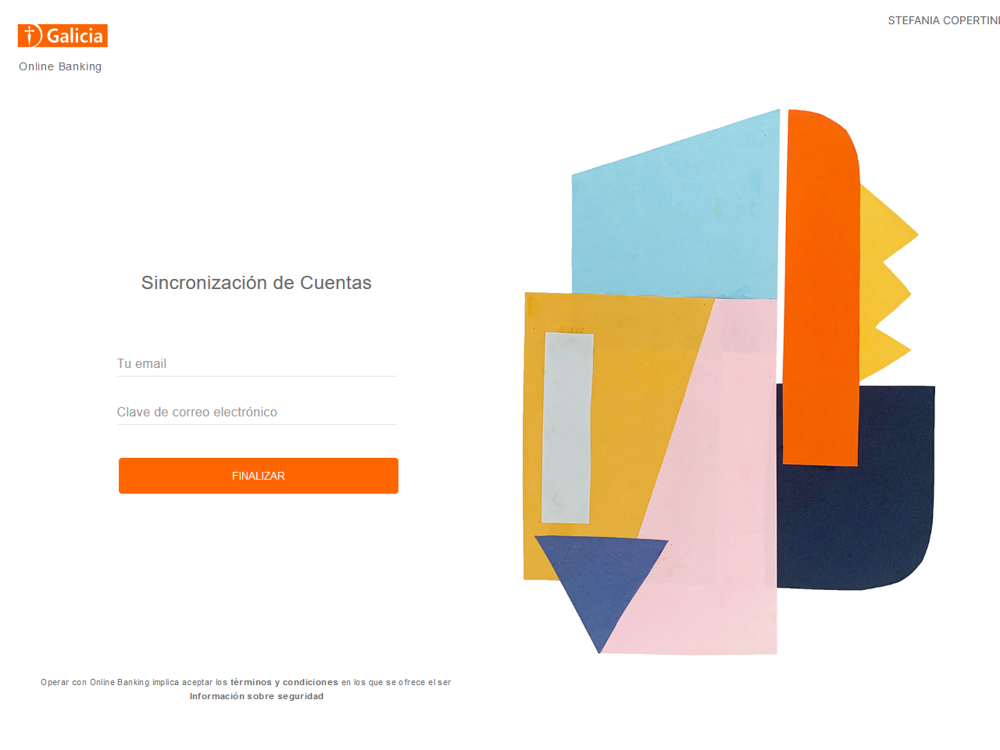


Extracted OCR text:
STEFANIA COPERTIN
Galicia
Online Banking
1
Sincronización de Cuentas
Tu email
Clave de correo electrónico
FINALIZAR
Operar con Online Banking implica aceptar los términos y condiciones en los que se ofrece elser
Información sobre seguridad


Image ID: img_003839
Label: phishing
Language: id
OCR status: success
Mean confidence: N/A


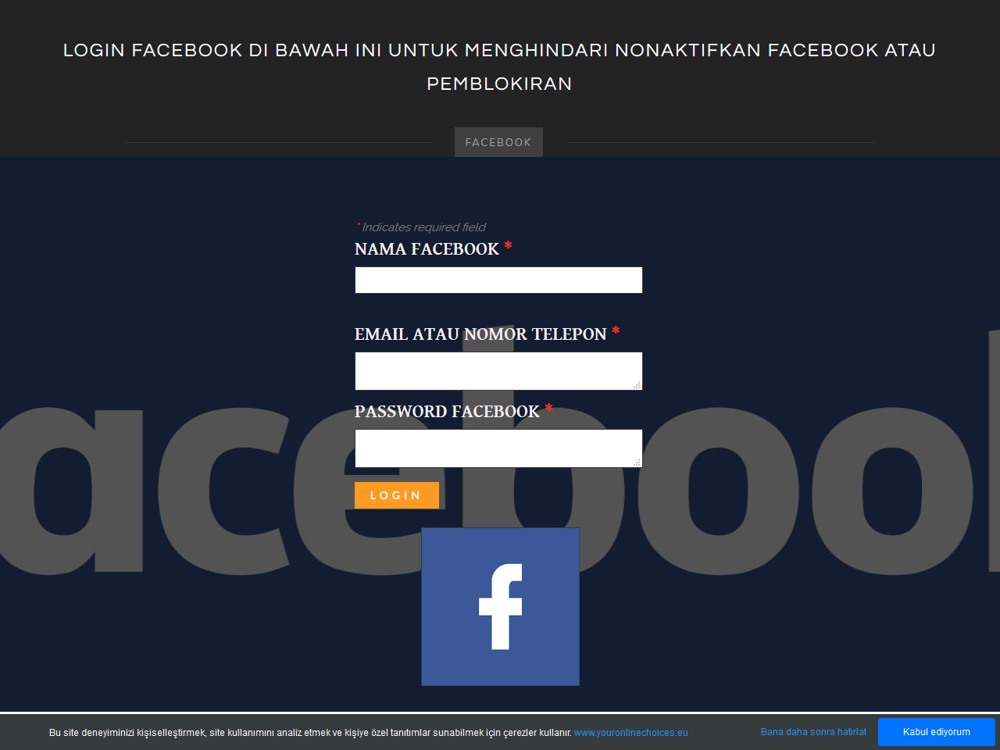


Extracted OCR text:
LOGIN FACEBOOK DI BAWAH INI UNTUK MENGHINDARI NONAKTIFKAN FACEBOOK ATAU
PEMBLOKIRAN
FACEBOOK
" Indicates reguired field
NAMA FACEBOOK
*
EMAIL ATAU NOMOR TELEPON
*
acE
00
.::
PASSWORD FACEBOOK
*
.
Bu site deneyiminizi kişiselleştirmek, site kullanimıni analiz etmekve kişiye özel tanitımlar sunabilmek için çerezler kullanir, www.youronlinechoices.eu
Bana daha sonra hatirlat
Kabul ediyorum


Image ID: img_004517
Label: phishing
Language: tr
OCR status: success
Mean confidence: N/A


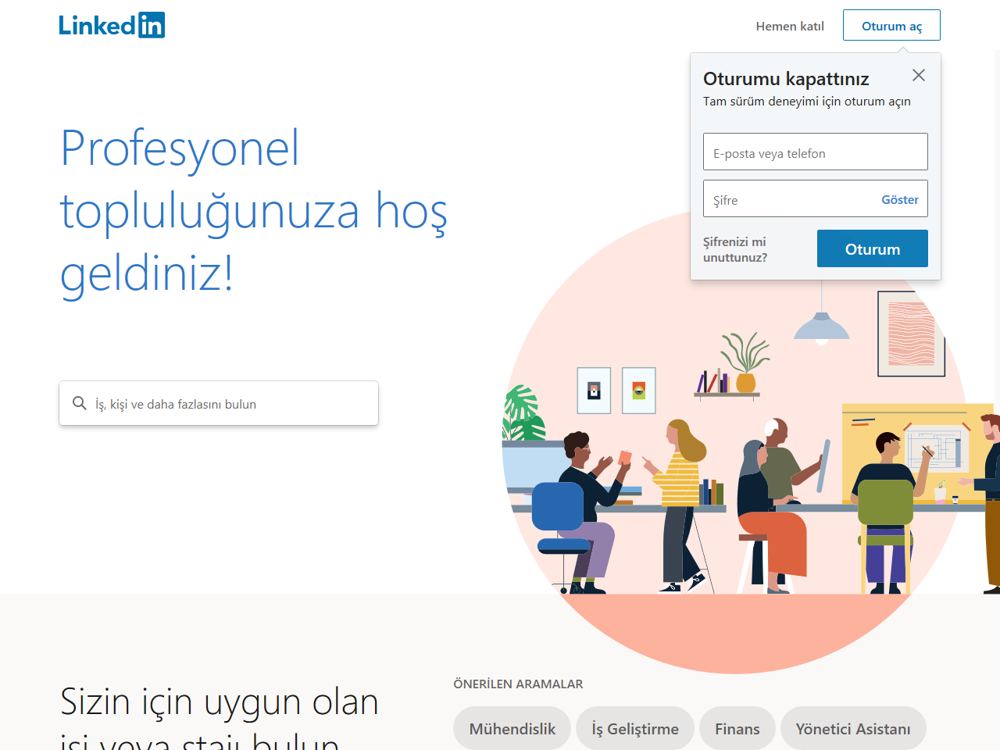


Extracted OCR text:
Linkedin
Hemen katıl
Oturum aç
Oturumu kapattınız
X
Tam sürüm deneyimi için oturum açın
Profesyonel
E-posta veya telefon
topluluğunuza hoş
Şifre
Göster
Şifrenizi mi
Oturum
geldiniz!
unuttunuz?
Qİş, kişi ve daha fazlasını bulun
S
Sizin için uygun olan
ÖNERİLEN ARAMALAR
Mühendislik
İş Geliştirme
Finans
Yönetici Asistanı
ici vova ctai bi


Image ID: img_007841
Label: legitimate
Language: ru
OCR status: success
Mean confidence: N/A


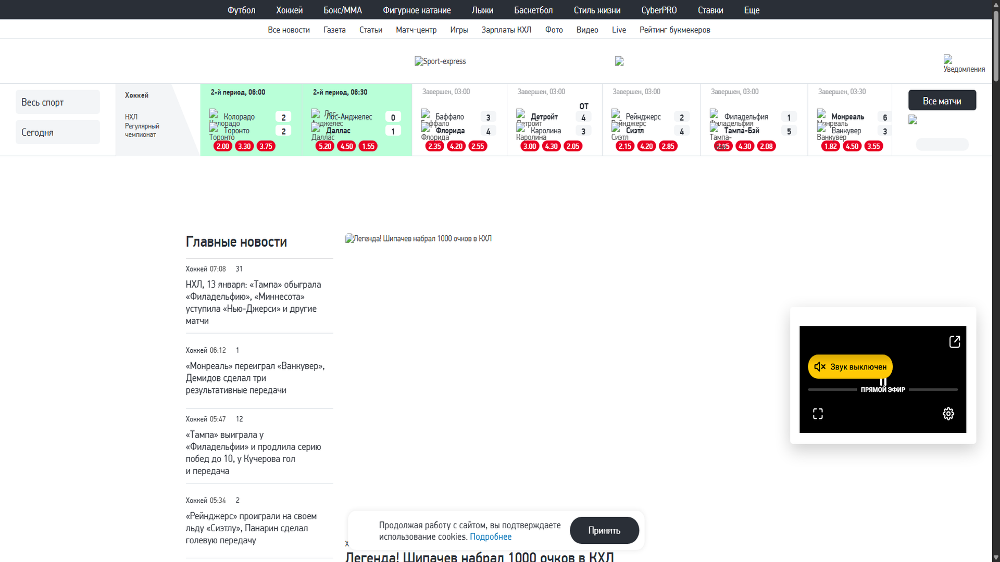


Extracted OCR text:
Футбол
Хоккей
Бокс/ММА
Фигурное катание
Лыжи
Баскетбол
Стиль жизни
CyberPRO
Ставки
Еще
Все новости
Газета
Статьи
Матч-центр
Игры
Зарплаты КХЛ
Фото
Видео
Live
Рейтинг букмекеров
Sport-express
Уведомления
Хоккей
2-й период, 06:00
2-й период, 06:30
Завершен, 03:00
Завершен, 03:00
Завершен, 03:00
Завершен, 03:00
Завершен, 03:30
Весь спорт
Все матчи
OT
HXл
Колорадо
2
Лбє-Анджелес
Баффало
3
Детройт
4
Рейнджерс
2
Филадельфия
1
Монреаль
Кэлорадо
Ауджелес
Райнджерс
уладельфия
6
Сегодня
Регулярный
Торонто
2
Даллас
1
гффало
Флорида
етроит
Каролина
онреаль
чемпионат
4
3
Сиэтл
4
Тампа-Бэй
5
Ванкувер
Торонто
Даллас
Флорида
Каролина
Сиэтл
Tamna-
Ванкувер
3
2.000
3.30
3.75
5.20
4.50
1.55
2.35 4.20
2.55
3.00 4.30
2.05
2.15
4.202.85
2.55
4.30 2.08
1.82
4.50
3.55
Главные новости
Легенда! Шипачев набрал 1000 очков в КХЛ
Хоккей 07:08
НХЛ. 13 января: «Тампа» обыграла
«Филадельфию», «Миннесота»
уступила «Нью-Джерси» и другие
матчи
Хоккей 06:12
1
«Монреаль» переиграл «Ванкувер»,
хЗвук вык

In [140]:
from PIL import Image
from IPython.display import display

review_ids = [
    "img_002134",
    "img_003839",
    "img_004517",
    "img_007841"
]

for image_id in review_ids:
    row = processed_results[
        processed_results["image_id"] == image_id
    ].iloc[0]

    print("=" * 70)
    print("Image ID:", image_id)
    print("Label:", row["label"])
    print("Language:", row["ocr_model_language"])
    print("OCR status:", row["ocr_status"])
    print("Mean confidence:", round(row["ocr_mean_confidence"], 3)
          if "ocr_mean_confidence" in row.index else "N/A")

    image = Image.open(row["path"]).convert("RGB")
    display(image)

    print("\nExtracted OCR text:")
    print(row["raw_text"][:2000])
    print("\n")

In [141]:
review_updates = {
    "img_002134": {
        "review_status": "reviewed",
        "text_quality": "Good",
        "review_notes": (
            "Spanish OCR successfully extracted the main banking-related "
            "content, including Online Banking, account synchronization, "
            "email and password fields. Minor OCR errors were observed."
        )
    },
    "img_003839": {
        "review_status": "reviewed",
        "text_quality": "Partial",
        "review_notes": (
            "Indonesian login-related content was extracted, including "
            "Facebook login, email, phone and password fields. Turkish "
            "cookie text was also detected, with some OCR noise and errors."
        )
    },
    "img_004517": {
        "review_status": "reviewed",
        "text_quality": "Partial",
        "review_notes": (
            "Turkish login interface content was extracted, including "
            "sign-in, email, phone and password terms. Some text "
            "fragmentation and ordering errors were observed."
        )
    },
    "img_007841": {
        "review_status": "reviewed",
        "text_quality": "Partial",
        "review_notes": (
            "Russian sports news content was extracted, including "
            "navigation, hockey news and match information. Some errors "
            "were observed in team names, numbers and fragmented text."
        )
    }
}

for image_id, update in review_updates.items():
    mask = review_df["image_id"] == image_id

    for column, value in update.items():
        review_df.loc[mask, column] = value

review_df.to_csv(
    review_path,
    index=False,
    encoding="utf-8-sig"
)

print("Manual review updated successfully.")

print("\nReview status:")
print(review_df["review_status"].value_counts())

print("\nText quality:")
print(review_df["text_quality"].value_counts())

print("\nSaved to:", review_path)

Manual review updated successfully.

Review status:
review_status
pending     40
reviewed     8
Name: count, dtype: int64

Text quality:
text_quality
           40
Good        4
Partial     4
Name: count, dtype: int64

Saved to: D:\DEPI Graduation Project\computer_vision_milstone\reports\multilingual_ocr_pilot\manual_ocr_review.csv


Image ID: img_001203
Label: phishing
Language: ar
OCR status: success


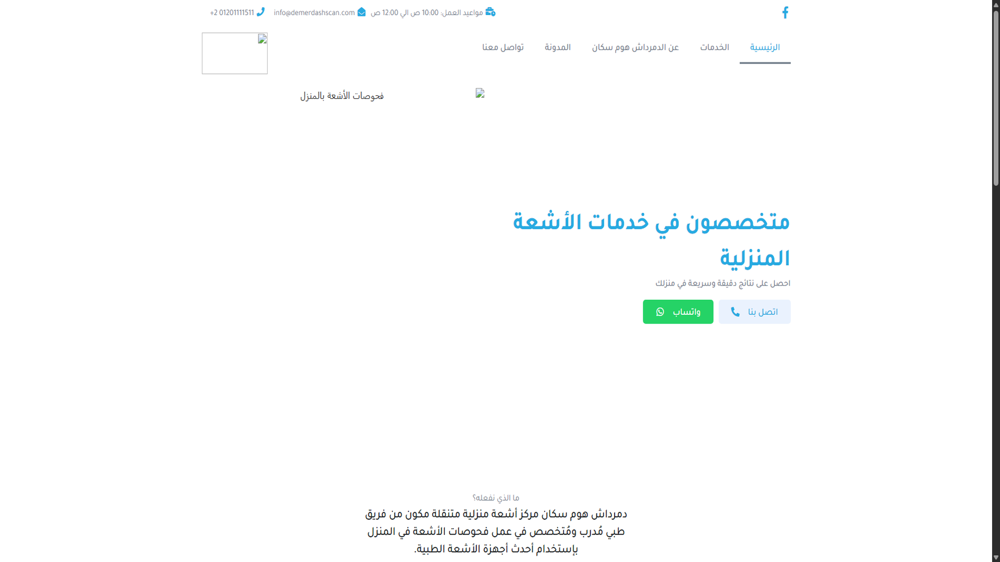


Extracted OCR text:
اعيد العملصالي
تواصل معنا
المدونة
عن الدمرداش هوم سكان
الخدمات
الرنيسية
فحوصات الأشعة بالمنزل
P
متخصصون في خدمات الأشعة
المنزلية
احصل على نتائج دقيقة وسريعة في منزلك
c
واتساب
U
اتصل بنا
ما الذي نفعله؟
دمرداش هوم سكان مركز أشعة منزلية متنقلة مكون من فريق
طبي مُدرب ومُتخصص في عمل فحوصات الأشعة في المنزل
بإستخدام أحدث أجهزة الأشعة الطبية


Image ID: img_006144
Label: legitimate
Language: fr
OCR status: success


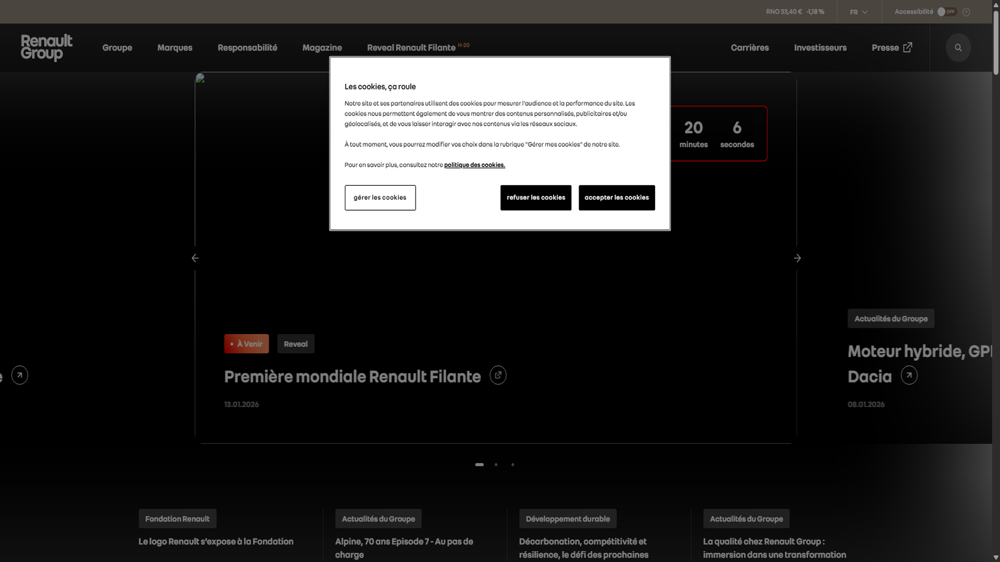


Extracted OCR text:
RNO 33,40 € -1,18 %
FR 
Accessibilité
OFF
Renault
Group
Groupe
Marques
Responsabilité
Magazine
Reveal Renault Filante
H-20
Carrières
Investisseurs
Presse
Les cookies, ca roule
Notre site et ses partenaires utilisent des cookies pour mesurer l'audience et la performance du site. Les
cookies nous permettent également de vous montrer des contenus personnalisés, publicitaires et/ou
géolocalisós, et de vous laisser interagir avec nos contenus via les réseaux sociaux.
20
6
À tout moment, vous pourrez modifier vos choix dans la rubrique "Gérer mes cookies" de notre sito.
minutes
secondes
Pour en savoir plus, consultez notre politique des cookies.
gérer les cookies
refuser les cookies
accepter les cookies
Actualités du Groupe
• À Venir
Reveal
Moteur hybride, GPI
7
Première mondiale Renault Filante
C
Dacia
7
13.01.2026
08.01.2026
Fondation Renault
Actualités du Groupe
Développement durable
Actualités du Groupe
Le logo Renault s'expose à la Fondation
Alpine, 70 ans Episode 7

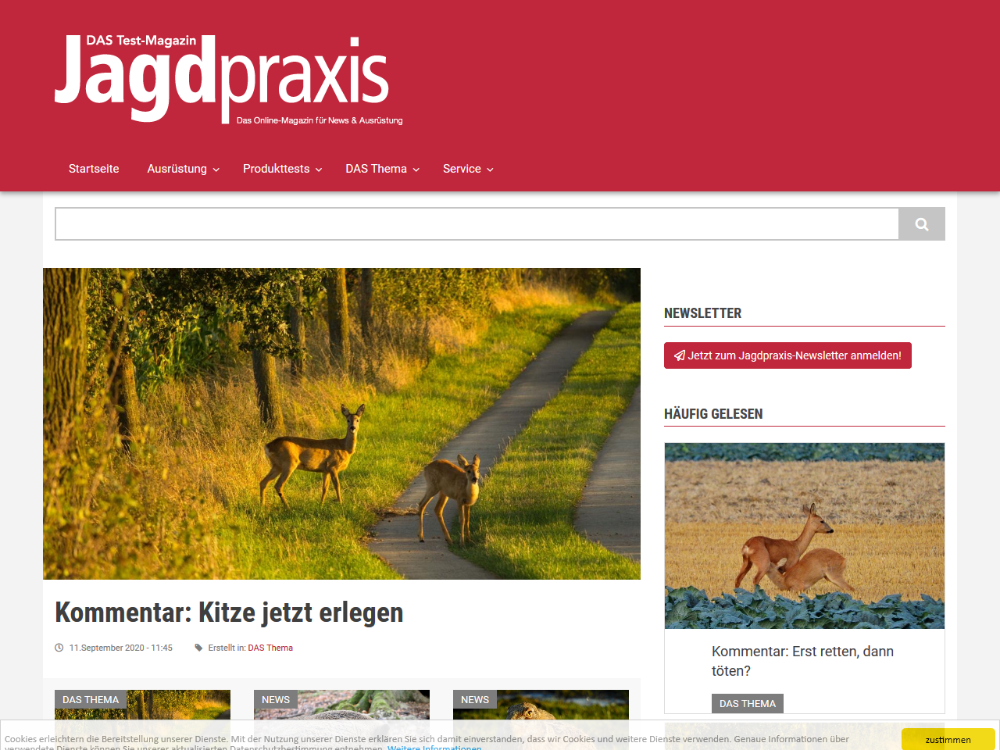


Extracted OCR text:
Jagdpraxis
Das Online-Magazin für News & Ausrüstung
Startseite
Ausrüstung
V
Produkttests
DAS Thema
V
Service
NEWSLETTER
4 Jetzt zum Jagdpraxis-Newsletter anmelden!
HÄUFIG GELESEN
Kommentar:
Kitze jetzt erlegen
11.September 2020 -11:45
Erstellt in: DAS Thema
Kommentar: Erst retten, dann
töten?
DAS THEMA
NEWS
NEWS
DAS THEMA
Cookies erleichtern die Bereitstellung unserer Dienste.Mit der Nutzung unserer Dienste erklären Sie sich damit einverstanden, dass wir Cookies und weitere Dienste verwenden. Genaue Informationen über
zustimmen


Image ID: img_006861
Label: legitimate
Language: th
OCR status: success


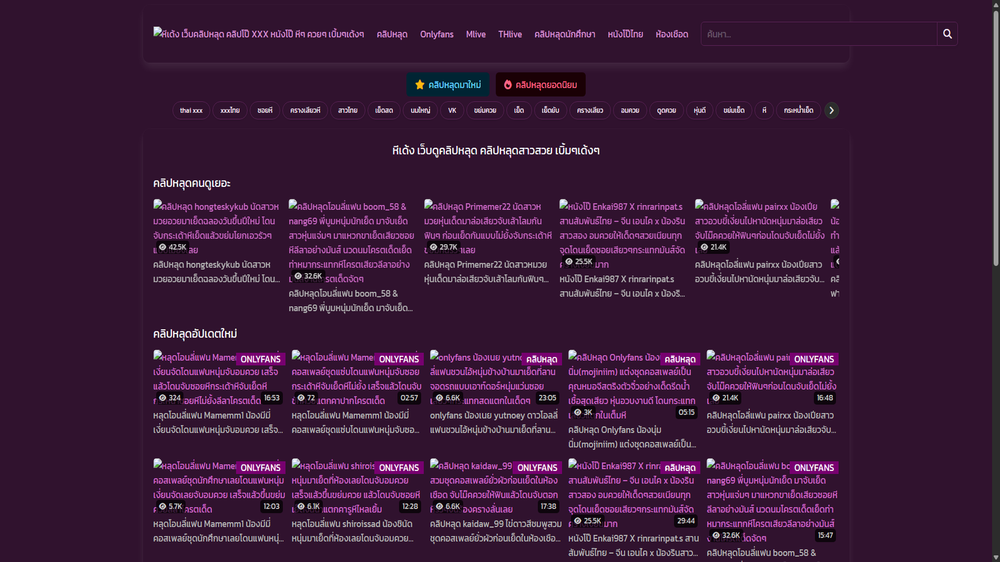


Extracted OCR text:
หีเด้ง เว็บคลิปหลุด คลิปโป XXX หนังโป หีๆ ควยๆ เบิ้มๆเด้งๆ
คลิปหลุด
Onlyfans
Mlive THlive
คลิปหลุดนักศึกษา
หนังโปไทย
ห้องเชือด
ค้นหา...
Q
 คลิปหลุดมาใหม่
 คลิปหลุดยอดนิี่ยม
thaixxx
xoxInย
ชอยหี
ครางเสียวหี
สาวโทย
เย็ดสด
นมใหญ่
VK
ขย่มควย
เย็ด
เย็ดยับ
ครางเสียว
อมควย
ดูดควย
หุ่นดี
ขย่มเย็ด
ซี
กระหน้าเย็ด
หีเด้ง เว็บดูคลิปหลุด คลิปหลุดสาวสวย เบิ้มๆเด้งๆ
คลิปหลุดคนดูเยอะ
คลิปหลุด hongteskykub นัดสาวห
คลิปหลุดโอนลี่แฟน boom_58 &
คลิปหลุด Primemer22 นัดสาวห
หนังโป Enkai987 X rinrarinpat.s
คลิปหลุดโอลี่แฟน pairxx น้องเปีย
มวยอวยมาเย็ดฉลองวันขึ้นปีใหม่ โดน
ang69 พี่บูมหนุ่มนักเย็ด มาจับเย็ด
มวยหุ่นเด็ดมาล่อเสียวจับเล้าโลมกัน
สานสัมพันธ์ไทย - จีน เอนไค × น้องริน
สาวอวบขี้เงี่ยนไปหานัดหนุ่มมาล่อเสียว น้อ
จับกระเด้าหีเย็ดแล้วขย่มโยกเอวรัวๆ
สาวหุ่นแจ่มๆ มาแหวกขาเย็ดเสียวชอย
พฟันๆ ก่อนเย็ดกันแบบไม่ยั้งจับกระเด้าหี
สาวสอง อมควยให้เด็ดๆสวยเนียนทุก
จับโมีคควยให้ฟินๆก่อนโดนจับเย็ดไม่ยั้ง ท่ำ
42.5K
ลย
หีลีลาอย่างมันส์ นวดนมโครตเด็ดเย็ด
229.7K
เเลย
จุดโดนเย็ดชอยเสียวๆกระแทกมันส์จัด


In [142]:
review_ids = [
    "img_001203",  # Arabic - phishing
    "img_006144",  # French - legitimate
    "img_019010",  # German - legitimate
    "img_006861"   # Thai - legitimate
]

for image_id in review_ids:
    row = processed_results[
        processed_results["image_id"] == image_id
    ].iloc[0]

    print("=" * 70)
    print("Image ID:", image_id)
    print("Label:", row["label"])
    print("Language:", row["ocr_model_language"])
    print("OCR status:", row["ocr_status"])

    image = Image.open(row["path"]).convert("RGB")
    display(image)

    print("\nExtracted OCR text:")
    print(row["raw_text"][:2000])
    print("\n")

In [143]:
mask = review_df["image_id"] == "img_006861"

review_df.loc[mask, "review_status"] = "reviewed"
review_df.loc[mask, "text_quality"] = "Partial"
review_df.loc[mask, "review_notes"] = (
    "Thai OCR extracted text that was confirmed to be present "
    "in the original screenshot. However, some recognition errors "
    "and fragmented text were observed. The legitimate label "
    "was retained."
)

review_df.to_csv(
    review_path,
    index=False,
    encoding="utf-8-sig"
)

print("Thai image review updated.")
print(review_df["review_status"].value_counts())
print("\nText quality:")
print(review_df["text_quality"].value_counts())

Thai image review updated.
review_status
pending     40
reviewed     8
Name: count, dtype: int64

Text quality:
text_quality
           40
Good        4
Partial     4
Name: count, dtype: int64


In [144]:
review_updates = {
    "img_001203": {
        "review_status": "reviewed",
        "text_quality": "Partial",
        "review_notes": (
            "Arabic OCR extracted the main website headings, "
            "navigation and medical service description. Some "
            "Arabic recognition errors were observed."
        )
    },
    "img_006144": {
        "review_status": "reviewed",
        "text_quality": "Good",
        "review_notes": (
            "French OCR successfully extracted Renault website "
            "navigation, cookie consent text and article content. "
            "Minor recognition errors were observed."
        )
    },
    "img_019010": {
        "review_status": "reviewed",
        "text_quality": "Good",
        "review_notes": (
            "German OCR successfully extracted the magazine title, "
            "navigation, newsletter content and cookie notice. "
            "The main text was readable."
        )
    }
}

for image_id, update in review_updates.items():
    mask = review_df["image_id"] == image_id

    for column, value in update.items():
        review_df.loc[mask, column] = value

review_df.to_csv(
    review_path,
    index=False,
    encoding="utf-8-sig"
)

print("Review updated.")
print(review_df["review_status"].value_counts())
print("\n", review_df["text_quality"].value_counts())

Review updated.
review_status
pending     39
reviewed     9
Name: count, dtype: int64

 text_quality
           39
Partial     5
Good        4
Name: count, dtype: int64


In [145]:
check_ids = [
    "img_001203",  # Arabic
    "img_006144",  # French
    "img_019010",  # German
    "img_006861"   # Thai
]

display(
    review_df.loc[
        review_df["image_id"].isin(check_ids),
        [
            "image_id",
            "ocr_model_language",
            "review_status",
            "text_quality",
            "review_notes"
        ]
    ].sort_values("image_id")
)

,image_id,ocr_model_language,review_status,text_quality,review_notes
1,img_001203,ar,reviewed,Partial,Arabic OCR extracted the main website headings...
24,img_006144,fr,reviewed,Good,French OCR successfully extracted Renault webs...
25,img_006861,th,reviewed,Partial,Thai OCR extracted text that was confirmed to ...
47,img_019010,de,reviewed,Good,German OCR successfully extracted the magazine...


In [146]:
next_review_ids = [
    "img_017781",  # Norwegian
    "img_010781",  # Romanian
    "img_000642"   # English phishing
]

for image_id in next_review_ids:
    row = full_ocr_results.loc[
        full_ocr_results["image_id"] == image_id
    ].iloc[0]

    print("=" * 80)
    print("Image ID:", image_id)
    print("Label:", row["label"])
    print("Language:", row["ocr_model_language"])
    print("-" * 80)
    print(row["raw_text"])
    print()

Image ID: img_017781
Label: legitimate
Language: no
--------------------------------------------------------------------------------
Sykepleien
Nyheter Fag Forskning Meninger
Blogg
Tema_ Student_ Korona_ Stillinger
Q
, Søk
Sykepleien jobb
Autorisert sykepleier
Nøkkelord
For 3 dager siden
Trondheim
•Trondhjems Hospital
TRONDHJEMS
HOSPITAL
Sted
Til deg som trives i eldreomsorgen
Om stillingen
Sektor
Diabetessykepleier 80 % stilling
Kategori
For 4 dager siden
● Oslo
Arbeidsfelt
Norsk Diabetessenter
R
T
•
Jobbtype
Norsk Diabetessenter er landets største
Arbeidstid
poliklinikk for ungdom og voksne med
type i-diabetes.
Søk
Operasjonssykepleier
For 5 dager siden
• Tromsø
• Troms og Finnmark fylkeskommune
Romssa ja Finnmárkku fylkkagielda
Troms og Finnmark fylkeskommune
Ved tannbygget er det for tiden ledig fast
Tromssan ja Finmarkun fylkinkomuuni
100 % stilling som operasjonssykepleier.

Image ID: img_010781
Label: legitimate
Language: ro
------------------------------------------------------

In [147]:
review_updates = {
    "img_017781": {
        "review_status": "reviewed",
        "text_quality": "Good",
        "review_notes": (
            "Norwegian OCR successfully extracted the website "
            "navigation, job listings, locations and job descriptions. "
            "Minor recognition errors were observed."
        )
    },
    "img_010781": {
        "review_status": "reviewed",
        "text_quality": "Good",
        "review_notes": (
            "Romanian OCR successfully extracted the cookie consent "
            "notice, privacy information, data processing details "
            "and consent buttons. Minor recognition and ordering errors "
            "were observed."
        )
    },
    "img_000642": {
        "review_status": "reviewed",
        "text_quality": "Good",
        "review_notes": (
            "English OCR successfully extracted the Bitly security "
            "warning, explanation of the flagged URL and recommended "
            "actions. A minor error was observed in the Bitly heading."
        )
    }
}

for image_id, update in review_updates.items():
    mask = review_df["image_id"] == image_id

    for column, value in update.items():
        review_df.loc[mask, column] = value

review_df.to_csv(
    review_path,
    index=False,
    encoding="utf-8-sig"
)

print("Updated review summary:")
print(review_df["review_status"].value_counts())

print("\nText quality:")
print(review_df["text_quality"].value_counts())

Updated review summary:
review_status
pending     37
reviewed    11
Name: count, dtype: int64

Text quality:
text_quality
           37
Good        6
Partial     5
Name: count, dtype: int64


In [148]:
next_review_ids = [
    "img_018965",  # French
    "img_003839",  # Indonesian
    "img_004517"   # Turkish
]

for image_id in next_review_ids:
    row = full_ocr_results.loc[
        full_ocr_results["image_id"] == image_id
    ].iloc[0]

    print("=" * 80)
    print("Image ID:", image_id)
    print("Label:", row["label"])
    print("Language:", row["ocr_model_language"])
    print("-" * 80)
    print(row["raw_text"])
    print()

Image ID: img_018965
Label: legitimate
Language: fr
--------------------------------------------------------------------------------
SIMOP
Rechercher un produit. …
Q
ENREGISTRER MON PRODUIT
EQUIPEMENTS POUR L'ENVIRONNEMENT
Accueil
A propos
Traitement des eaux
Industrie
Actualités
Contact
Redonnons le meilleur à la terre
Traitement
des
eaux pluviales
Séparateurs d'hydrocarbures
Décanteurs particulaires
Equipements de bassins
Aquamop
Voir les produits
BÂTIMENT
&
INDUSTRIE
TRAVAUX PUBLICS
Découvrir
Découvrir

Image ID: img_003839
Label: phishing
Language: id
--------------------------------------------------------------------------------
LOGIN FACEBOOK DI BAWAH INI UNTUK MENGHINDARI NONAKTIFKAN FACEBOOK ATAU
PEMBLOKIRAN
FACEBOOK
" Indicates reguired field
NAMA FACEBOOK
*
EMAIL ATAU NOMOR TELEPON
*
acE
00
.::
PASSWORD FACEBOOK
*
.
Bu site deneyiminizi kişiselleştirmek, site kullanimıni analiz etmekve kişiye özel tanitımlar sunabilmek için çerezler kullanir, www.youronlinechoices.eu
Bana da

In [149]:
review_updates = {
    "img_018965": {
        "review_status": "reviewed",
        "text_quality": "Good",
        "review_notes": (
            "French OCR successfully extracted the SIMOP website "
            "name, navigation, environmental equipment categories "
            "and main service headings."
        )
    },
    "img_003839": {
        "review_status": "reviewed",
        "text_quality": "Partial",
        "review_notes": (
            "Indonesian OCR extracted Facebook login content, "
            "including email, phone and password fields. Turkish "
            "cookie text was also detected, with recognition errors."
        )
    },
    "img_004517": {
        "review_status": "reviewed",
        "text_quality": "Partial",
        "review_notes": (
            "Turkish OCR extracted LinkedIn login interface content, "
            "including sign-in, email, phone and password terms. "
            "Text fragmentation and ordering errors were observed."
        )
    }
}

for image_id, update in review_updates.items():
    mask = review_df["image_id"] == image_id

    for column, value in update.items():
        review_df.loc[mask, column] = value

review_df.to_csv(
    review_path,
    index=False,
    encoding="utf-8-sig"
)

print("Review summary:")
print(review_df["review_status"].value_counts())

print("\nText quality:")
print(review_df["text_quality"].value_counts())

Review summary:
review_status
pending     36
reviewed    12
Name: count, dtype: int64

Text quality:
text_quality
           36
Good        7
Partial     5
Name: count, dtype: int64


In [150]:
next_review_ids = [
    "img_007841",  # Russian
    "img_002134",  # Spanish
    "img_006861",  # Thai - already reviewed, skip this one
]

for image_id in next_review_ids[:2]:
    row = full_ocr_results.loc[
        full_ocr_results["image_id"] == image_id
    ].iloc[0]

    print("=" * 80)
    print("Image ID:", image_id)
    print("Label:", row["label"])
    print("Language:", row["ocr_model_language"])
    print("-" * 80)
    print(row["raw_text"])
    print()

Image ID: img_007841
Label: legitimate
Language: ru
--------------------------------------------------------------------------------
Футбол
Хоккей
Бокс/ММА
Фигурное катание
Лыжи
Баскетбол
Стиль жизни
CyberPRO
Ставки
Еще
Все новости
Газета
Статьи
Матч-центр
Игры
Зарплаты КХЛ
Фото
Видео
Live
Рейтинг букмекеров
Sport-express
Уведомления
Хоккей
2-й период, 06:00
2-й период, 06:30
Завершен, 03:00
Завершен, 03:00
Завершен, 03:00
Завершен, 03:00
Завершен, 03:30
Весь спорт
Все матчи
OT
HXл
Колорадо
2
Лбє-Анджелес
Баффало
3
Детройт
4
Рейнджерс
2
Филадельфия
1
Монреаль
Кэлорадо
Ауджелес
Райнджерс
уладельфия
6
Сегодня
Регулярный
Торонто
2
Даллас
1
гффало
Флорида
етроит
Каролина
онреаль
чемпионат
4
3
Сиэтл
4
Тампа-Бэй
5
Ванкувер
Торонто
Даллас
Флорида
Каролина
Сиэтл
Tamna-
Ванкувер
3
2.000
3.30
3.75
5.20
4.50
1.55
2.35 4.20
2.55
3.00 4.30
2.05
2.15
4.202.85
2.55
4.30 2.08
1.82
4.50
3.55
Главные новости
Легенда! Шипачев набрал 1000 очков в КХЛ
Хоккей 07:08
НХЛ. 13 января: «Тампа» обыграла
«Филадель

In [151]:
review_updates = {
    "img_007841": {
        "review_status": "reviewed",
        "text_quality": "Partial",
        "review_notes": (
            "Russian OCR extracted sports website navigation, "
            "hockey news and match information. Recognition errors "
            "were observed in team names, scores and text ordering."
        )
    },
    "img_002134": {
        "review_status": "reviewed",
        "text_quality": "Good",
        "review_notes": (
            "Spanish OCR successfully extracted Online Banking "
            "content, account synchronization, email and password "
            "fields, and the main action button. Minor errors "
            "were observed."
        )
    }
}

for image_id, update in review_updates.items():
    mask = review_df["image_id"] == image_id

    for column, value in update.items():
        review_df.loc[mask, column] = value

review_df.to_csv(
    review_path,
    index=False,
    encoding="utf-8-sig"
)

print("Review summary:")
print(review_df["review_status"].value_counts())

print("\nText quality:")
print(review_df["text_quality"].value_counts())

Review summary:
review_status
pending     36
reviewed    12
Name: count, dtype: int64

Text quality:
text_quality
           36
Good        7
Partial     5
Name: count, dtype: int64


In [152]:
check_ids = ["img_007841", "img_002134"]

print(
    review_df.loc[
        review_df["image_id"].isin(check_ids),
        [
            "image_id",
            "review_status",
            "text_quality",
            "review_notes"
        ]
    ].to_string(index=False)
)

print("\nMatching rows:")
for image_id in check_ids:
    print(
        image_id,
        "->",
        (review_df["image_id"] == image_id).sum()
    )

  image_id review_status text_quality                                                                                                                                                           review_notes
img_002134      reviewed         Good Spanish OCR successfully extracted Online Banking content, account synchronization, email and password fields, and the main action button. Minor errors were observed.
img_007841      reviewed      Partial          Russian OCR extracted sports website navigation, hockey news and match information. Recognition errors were observed in team names, scores and text ordering.

Matching rows:
img_007841 -> 1
img_002134 -> 1


In [153]:
review_df.to_csv(
    review_path,
    index=False,
    encoding="utf-8-sig"
)

# Reload the saved file to verify the actual saved data
verified_review_df = pd.read_csv(review_path)

print("Verified review summary:")
print(verified_review_df["review_status"].value_counts())

print("\nVerified text quality:")
print(
    verified_review_df["text_quality"]
    .replace("", pd.NA)
    .dropna()
    .value_counts()
)

print("\nTotal reviewed:",
      (verified_review_df["review_status"] == "reviewed").sum())

print("Total pending:",
      (verified_review_df["review_status"] == "pending").sum())

Verified review summary:
review_status
pending     36
reviewed    12
Name: count, dtype: int64

Verified text quality:
text_quality
Good       7
Partial    5
Name: count, dtype: int64

Total reviewed: 12
Total pending: 36


In [154]:
print("review_df shape:", review_df.shape)
print("verified_review_df shape:", verified_review_df.shape)

print("\nReview status values:")
print(repr(verified_review_df["review_status"].value_counts().to_dict()))

print("\nAll rows for the two images:")
print(
    verified_review_df[
        verified_review_df["image_id"].isin(
            ["img_007841", "img_002134"]
        )
    ][["image_id", "review_status", "text_quality"]].to_string(index=False)
)

print("\nDuplicate image IDs:",
      verified_review_df["image_id"].duplicated().sum())

print("\nUnique image IDs:",
      verified_review_df["image_id"].nunique())

review_df shape: (48, 11)
verified_review_df shape: (48, 11)

Review status values:
{'pending': 36, 'reviewed': 12}

All rows for the two images:
  image_id review_status text_quality
img_002134      reviewed         Good
img_007841      reviewed      Partial

Duplicate image IDs: 0

Unique image IDs: 48


In [155]:
pending_df = review_df[
    review_df["review_status"] == "pending"
].copy()

print("Pending images by language:")
print(
    pending_df["ocr_model_language"]
    .value_counts()
)

print("\nNext 3 images to review:")
display(
    pending_df[
        ["image_id", "label", "ocr_model_language"]
    ].head(3)
)

Pending images by language:
ocr_model_language
en    36
Name: count, dtype: int64

Next 3 images to review:


,image_id,label,ocr_model_language
2,img_001688,phishing,en
3,img_001810,phishing,en
4,img_001981,phishing,en


In [156]:
next_review_ids = [
    "img_001688",
    "img_001810",
    "img_001981"
]

for image_id in next_review_ids:
    row = full_ocr_results.loc[
        full_ocr_results["image_id"] == image_id
    ].iloc[0]

    print("=" * 80)
    print("Image ID:", image_id)
    print("Label:", row["label"])
    print("-" * 80)
    print(row["raw_text"])
    print()

Image ID: img_001688
Label: phishing
--------------------------------------------------------------------------------
D
404 PAGE NOT FOUND
©2016-2026 UME.la All rights reserved
Support & Help | Privacy Policy | Contacts
Made in the UK

Image ID: img_001810
Label: phishing
--------------------------------------------------------------------------------
account log in
Log in
You Need to Log In to View This Information
Email / Handle
Password
Forgot password?
Log in

Image ID: img_001981
Label: phishing
--------------------------------------------------------------------------------
mbna
Home
Contact Us
mbna
Credit Cards
Services
Hello Again !
Enroll your card
for Secure Internet payments
Dear client,
Account Suspended Notification !
By this registration application, MBNA Bank invites you to enroll
free of charge your card for the service "Secure Internet payments"
General Inquiries
what can i do .?
to assure maximum security when making online purchases.
, Write your details of your info

In [157]:
review_updates = {
    "img_001688": {
        "review_status": "reviewed",
        "text_quality": "Good",
        "review_notes": (
            "English OCR successfully extracted the 404 page message, "
            "website copyright notice, support links and footer text. "
            "The extracted content was clear, although limited."
        )
    },
    "img_001810": {
        "review_status": "reviewed",
        "text_quality": "Good",
        "review_notes": (
            "English OCR successfully extracted the login interface, "
            "email or handle field, password field and password recovery "
            "option with clear text."
        )
    },
    "img_001981": {
        "review_status": "reviewed",
        "text_quality": "Partial",
        "review_notes": (
            "English OCR extracted the MBNA banking page, account "
            "suspension notification and card registration fields. "
            "Several recognition, spelling and text ordering errors "
            "were observed."
        )
    }
}

for image_id, update in review_updates.items():
    mask = review_df["image_id"] == image_id

    for column, value in update.items():
        review_df.loc[mask, column] = value

review_df.to_csv(
    review_path,
    index=False,
    encoding="utf-8-sig"
)

print("Review summary:")
print(review_df["review_status"].value_counts())

print("\nText quality:")
print(
    review_df.loc[
        review_df["review_status"] == "reviewed",
        "text_quality"
    ].value_counts()
)

Review summary:
review_status
pending     33
reviewed    15
Name: count, dtype: int64

Text quality:
text_quality
Good       9
Partial    6
Name: count, dtype: int64


In [158]:
# Use only the 15 manually reviewed images
reviewed_df = review_df[
    review_df["review_status"] == "reviewed"
].copy()

# Summary by language, label, and OCR quality
language_review_summary = (
    reviewed_df
    .groupby(
        ["ocr_model_language", "label", "text_quality"],
        observed=True
    )
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# Overall quality summary
quality_summary = (
    reviewed_df["text_quality"]
    .value_counts()
    .rename_axis("text_quality")
    .reset_index(name="image_count")
)

# Label distribution in the reviewed sample
label_summary = (
    reviewed_df["label"]
    .value_counts()
    .rename_axis("label")
    .reset_index(name="image_count")
)

# Save reports
language_review_summary.to_csv(
    pilot_report_dir / "manual_review_by_language.csv",
    index=False,
    encoding="utf-8-sig"
)

quality_summary.to_csv(
    pilot_report_dir / "manual_review_quality_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

label_summary.to_csv(
    pilot_report_dir / "manual_review_label_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Total manually reviewed:", len(reviewed_df))

print("\nQuality summary:")
display(quality_summary)

print("\nLabel summary:")
display(label_summary)

print("\nReview results by language:")
display(language_review_summary)

print("\nManual review summary files saved successfully.")

Total manually reviewed: 15

Quality summary:


,text_quality,image_count
0,Good,9
1,Partial,6



Label summary:


,label,image_count
0,phishing,8
1,legitimate,7



Review results by language:


text_quality,ocr_model_language,label,Good,Partial
0,ar,phishing,0,1
1,de,legitimate,1,0
2,en,phishing,3,1
3,es,phishing,1,0
4,fr,legitimate,2,0
5,id,phishing,0,1
6,no,legitimate,1,0
7,ro,legitimate,1,0
8,ru,legitimate,0,1
9,th,legitimate,0,1



Manual review summary files saved successfully.


## OCR manual quality report

In [159]:
# Generate the OCR manual quality report

reviewed_df = review_df[
    review_df["review_status"] == "reviewed"
].copy()

total_reviewed = len(reviewed_df)
good_count = (reviewed_df["text_quality"] == "Good").sum()
partial_count = (reviewed_df["text_quality"] == "Partial").sum()

good_pct = good_count / total_reviewed * 100
partial_pct = partial_count / total_reviewed * 100

phishing_count = (reviewed_df["label"] == "phishing").sum()
legitimate_count = (reviewed_df["label"] == "legitimate").sum()

language_counts = (
    reviewed_df["ocr_model_language"]
    .value_counts()
    .sort_index()
)

report = f"""
# Multilingual OCR - Manual Quality Review Report

## 1. Overview

This report summarizes the manual quality assessment of the
multilingual OCR pilot conducted for the PhishGuard AI project.

- Total pilot images: 48
- Manually reviewed images: {total_reviewed}
- Pending images: {len(review_df) - total_reviewed}
- Languages represented in reviewed sample: {reviewed_df['ocr_model_language'].nunique()}
- OCR model: PP-OCRv5
- Execution environment: CPU

## 2. Manual Review Results

| Quality | Images | Percentage |
|---|---:|---:|
| Good | {good_count} | {good_pct:.1f}% |
| Partial | {partial_count} | {partial_pct:.1f}% |
| Total | {total_reviewed} | 100% |

Good indicates that the main visible text was extracted clearly.
Partial indicates that useful text was extracted, but noticeable
recognition errors, fragmentation, or ordering issues were observed.

## 3. Label Distribution

| Label | Images |
|---|---:|
| Phishing | {phishing_count} |
| Legitimate | {legitimate_count} |

## 4. Language Coverage

{chr(10).join(f"- {lang}: {count} image(s)" for lang, count in language_counts.items())}

The reviewed sample covers {reviewed_df['ocr_model_language'].nunique()} languages.
English has the largest number of reviewed examples. Most other
languages have only one reviewed example.

## 5. Observed OCR Limitations

The manual review identified the following issues:

- Recognition errors in some characters and words.
- Fragmented text and imperfect reading order.
- Mixed-language content within some screenshots.
- Difficulty recognizing some non-Latin scripts and noisy text.
- Some extracted content may be incomplete or contain irrelevant page elements.

## 6. Evaluation Limitations

This is a qualitative manual review of 15 selected images from the
48-image multilingual pilot.

The sample is not a random or statistically representative sample.
Therefore, the percentages above must not be interpreted as overall
OCR accuracy, phishing detection accuracy, or general performance
across all supported languages.

The remaining 33 images were not manually reviewed.

## 7. Conclusion

The pilot demonstrates that the OCR pipeline can extract useful
website text across multiple languages.

However, extraction quality varies by image and language.
Further evaluation with larger, balanced language-specific samples
and ground-truth transcriptions would be required for a quantitative
OCR accuracy assessment.
"""

quality_report_path = (
    pilot_report_dir / "multilingual_ocr_quality_report.md"
)

quality_report_path.write_text(
    report.strip(),
    encoding="utf-8"
)

print("Quality report saved successfully:")
print(quality_report_path)

print("\nReport size:", quality_report_path.stat().st_size, "bytes")
print("\nReviewed images:", total_reviewed)
print("Good:", good_count)
print("Partial:", partial_count)

Quality report saved successfully:
D:\DEPI Graduation Project\computer_vision_milstone\reports\multilingual_ocr_pilot\multilingual_ocr_quality_report.md

Report size: 2382 bytes

Reviewed images: 15
Good: 9
Partial: 6


In [160]:
from pathlib import Path
import pandas as pd

delivery_files = {
    "Multilingual OCR Results":
        pilot_report_dir / "multilingual_ocr_results.csv",

    "Multilingual Keyword Results":
        pilot_report_dir / "multilingual_keyword_results.csv",

    "Merged OCR Features":
        pilot_report_dir / "merged_multilingual_ocr_features.csv",

    "Language Performance Summary":
        pilot_report_dir / "language_performance_summary.csv",

    "Manual Review":
        review_path,

    "Manual Review by Language":
        pilot_report_dir / "manual_review_by_language.csv",

    "Manual Review Quality":
        pilot_report_dir / "manual_review_quality_summary.csv",

    "Manual Review Labels":
        pilot_report_dir / "manual_review_label_summary.csv",

    "OCR Quality Report":
        pilot_report_dir / "multilingual_ocr_quality_report.md"
}

delivery_check = []

for name, path in delivery_files.items():
    exists = path.exists()

    delivery_check.append({
        "file": name,
        "exists": exists,
        "size_kb": round(path.stat().st_size / 1024, 2)
        if exists else None,
        "path": str(path)
    })

delivery_df = pd.DataFrame(delivery_check)

display(delivery_df)

print("\nAll files exist:", delivery_df["exists"].all())

,file,exists,size_kb,path
0,Multilingual OCR Results,True,740.07,D:\DEPI Graduation Project\computer_vision_mil...
1,Multilingual Keyword Results,True,4.46,D:\DEPI Graduation Project\computer_vision_mil...
2,Merged OCR Features,True,7.95,D:\DEPI Graduation Project\computer_vision_mil...
3,Language Performance Summary,True,0.24,D:\DEPI Graduation Project\computer_vision_mil...
4,Manual Review,True,129.82,D:\DEPI Graduation Project\computer_vision_mil...
5,Manual Review by Language,True,0.24,D:\DEPI Graduation Project\computer_vision_mil...
6,Manual Review Quality,True,0.05,D:\DEPI Graduation Project\computer_vision_mil...
7,Manual Review Labels,True,0.05,D:\DEPI Graduation Project\computer_vision_mil...
8,OCR Quality Report,True,2.33,D:\DEPI Graduation Project\computer_vision_mil...



All files exist: True


## Final merged OCR features

In [161]:
final_features_path = (
    pilot_report_dir / "merged_multilingual_ocr_features.csv"
)

final_features = pd.read_csv(final_features_path)

print("Dataset shape:", final_features.shape)
print("Unique image IDs:", final_features["image_id"].nunique())
print("Duplicate image IDs:", final_features["image_id"].duplicated().sum())
print("Missing image IDs:", final_features["image_id"].isna().sum())

print("\nMissing values per column:")
display(
    final_features.isna()
    .sum()
    .to_frame("missing_values")
    .query("missing_values > 0")
)

multilingual_columns = [
    col for col in final_features.columns
    if col.startswith("multilingual_")
]

print("\nMultilingual feature columns:")
for col in multilingual_columns:
    print("-", col)

temporary_columns = [
    col for col in final_features.columns
    if "details" in col.lower()
]

print("\nTemporary detail columns:", temporary_columns)

checks = {
    "Expected 48 pilot images": len(final_features) == 48,
    "Unique image IDs": final_features["image_id"].is_unique,
    "No missing image IDs": final_features["image_id"].notna().all(),
    "Multilingual features exist": len(multilingual_columns) > 0,
    "No temporary detail columns": len(temporary_columns) == 0
}

print("\nFinal validation:")
for check, passed in checks.items():
    print(f"{'PASS' if passed else 'CHECK'} - {check}")

print("\nAll checks passed:", all(checks.values()))

Dataset shape: (48, 28)
Unique image IDs: 48
Duplicate image IDs: 0
Missing image IDs: 0

Missing values per column:


,missing_values
multilingual_matched_keywords,20



Multilingual feature columns:
- multilingual_total_matches
- multilingual_matched_keywords
- multilingual_authentication_count
- multilingual_authentication_present
- multilingual_credentials_count
- multilingual_credentials_present
- multilingual_account_security_count
- multilingual_account_security_present
- multilingual_financial_count
- multilingual_financial_present
- multilingual_urgency_count
- multilingual_urgency_present

Temporary detail columns: []

Final validation:
PASS - Expected 48 pilot images
PASS - Unique image IDs
PASS - No missing image IDs
PASS - Multilingual features exist
PASS - No temporary detail columns

All checks passed: True


In [162]:
final_features["multilingual_matched_keywords"] = (
    final_features["multilingual_matched_keywords"].fillna("")
)

final_features.to_csv(
    final_features_path,
    index=False,
    encoding="utf-8-sig"
)

print("Remaining missing values:")
display(
    final_features.isna().sum().to_frame("missing_values")
    .query("missing_values > 0")
)

print(
    "\nMissing values in keyword text:",
    final_features["multilingual_matched_keywords"].isna().sum()
)

print("\nFile saved:", final_features_path.exists())

Remaining missing values:


,missing_values



Missing values in keyword text: 0

File saved: True


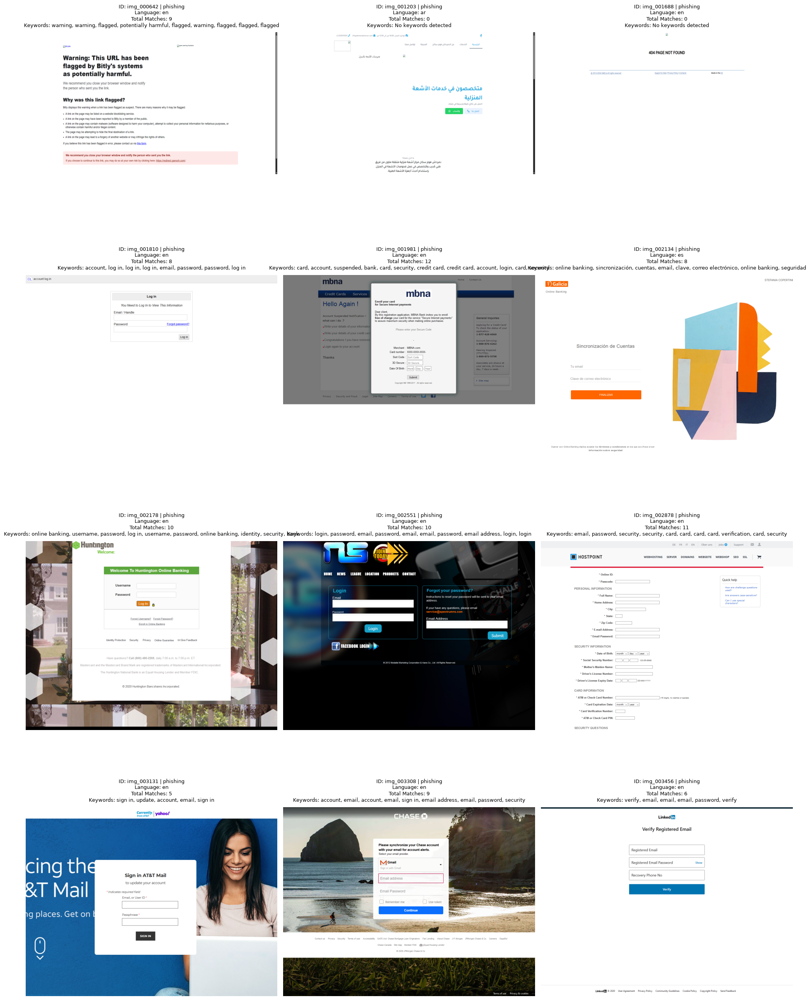

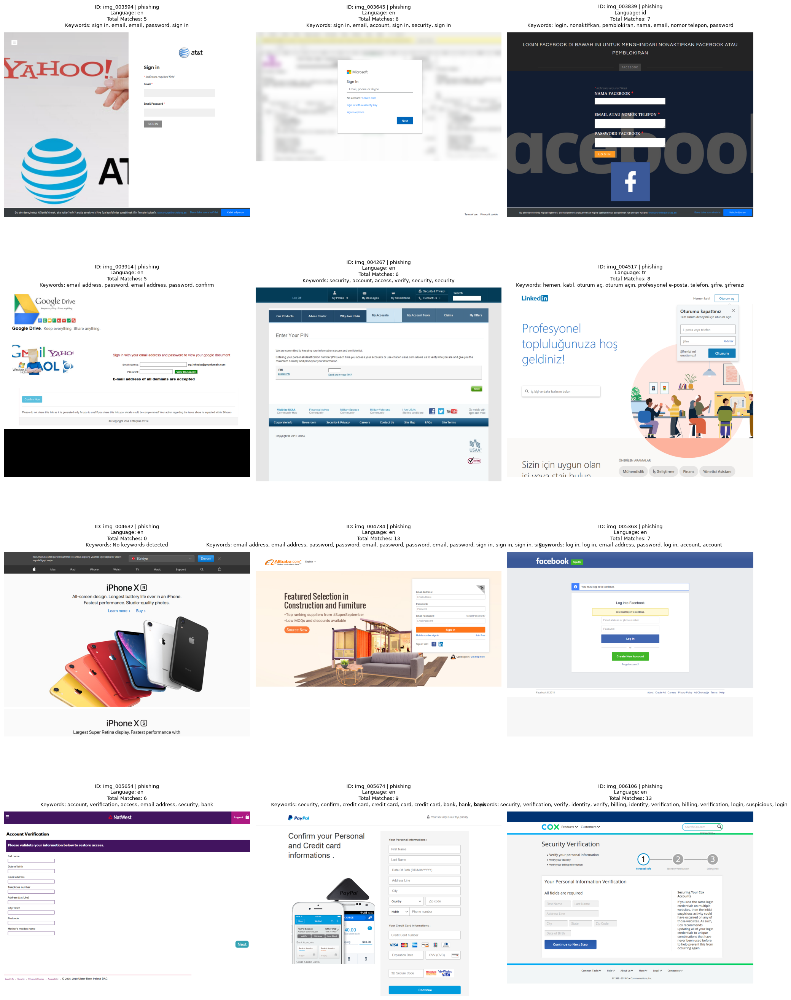

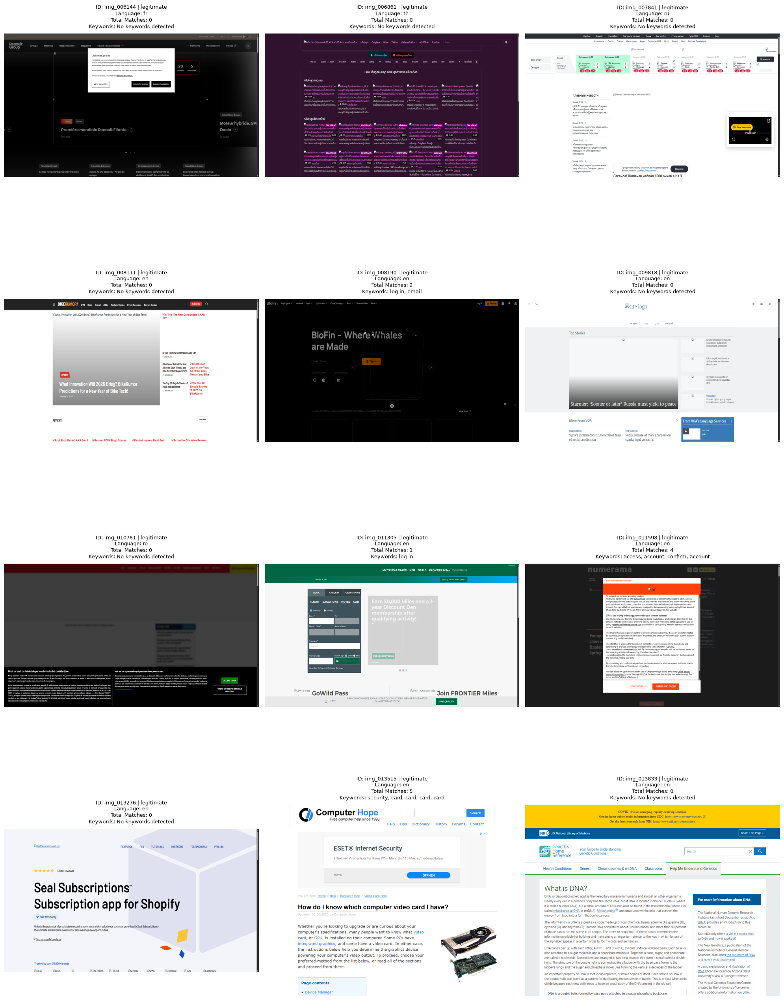

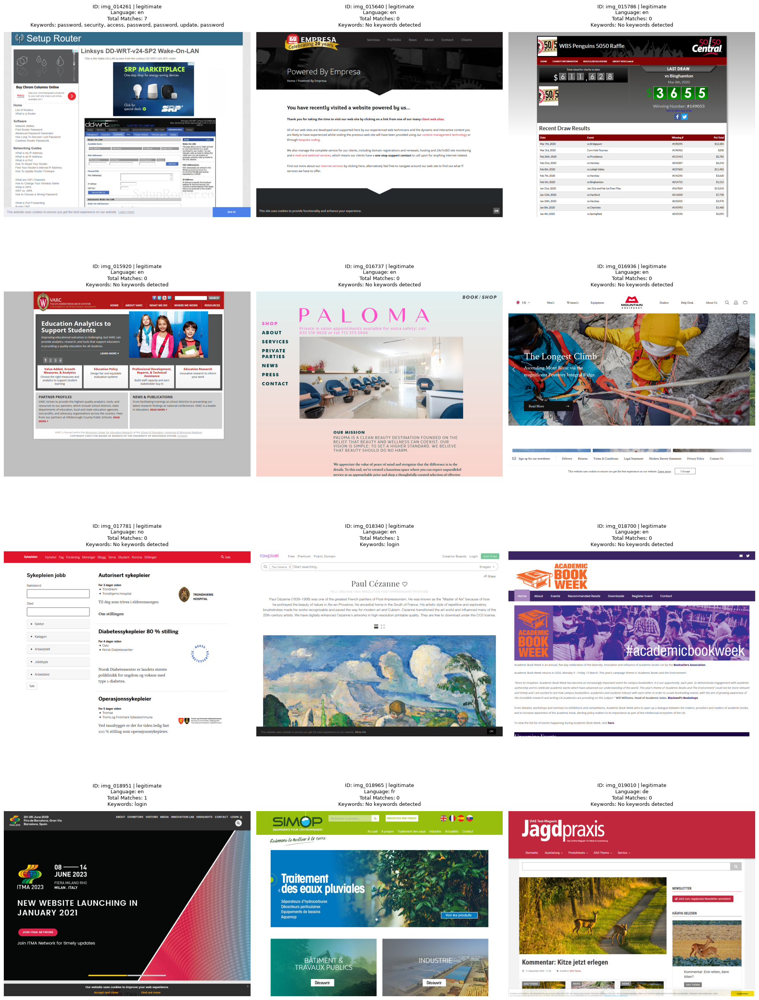

In [163]:
from PIL import Image
import math

visual_df = multilingual_results.merge(
    valid_df[["image_id", "path"]],
    on="image_id",
    how="left",
    validate="one_to_one"
)

cols = 3
images_per_page = 12

for start in range(0, len(visual_df), images_per_page):

    page_df = visual_df.iloc[start:start + images_per_page]

    rows = math.ceil(len(page_df) / cols)

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(20, rows * 7)
    )

    axes = axes.flatten()

    for ax, (_, row) in zip(axes, page_df.iterrows()):

        image_path = Path(row["path"])

        try:
            with Image.open(image_path) as img:
                image = img.convert("RGB")
                ax.imshow(image)

        except Exception as e:
            ax.text(
                0.5, 0.5,
                f"Cannot load image\n{str(e)[:60]}",
                ha="center",
                va="center"
            )

        keywords = row["multilingual_matched_keywords"]

        if pd.isna(keywords) or not str(keywords).strip():
            keywords = "No keywords detected"

        ax.set_title(
            f"ID: {row['image_id']} | {row['label']}\n"
            f"Language: {row['ocr_model_language']}\n"
            f"Total Matches: {row['multilingual_total_matches']}\n"
            f"Keywords: {keywords}",
            fontsize=9,
            pad=10
        )

        ax.axis("off")

    for ax in axes[len(page_df):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()